# DSCI 552 Homework 6

English submission. All official data are used. This notebook includes the full experiment implementation and the formal answers. Expensive fits are checkpointed in `results/`; executing with existing checkpoints reuses them and independently verifies predictions against saved estimators. A fresh run is obtained in a copy of the project with generated experiment checkpoints removed (see README). No input file is changed. Seed = 552.

The report and notebook read the same actual outputs. Final test imputation follows the unusual homework footnote; cross-validation remains strictly training-fold fitted. The standard XGBoost implementation differs from the node-level logistic model tree described by the question; see 1(e).

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
assert (ROOT / "Homework6.pdf").exists(), "Run from the project root"
sys.path.insert(0, str(ROOT / "scripts"))
print("Python:", sys.version)
print("Project:", ROOT)

Python: 3.12.8 (main, Jan 14 2025, 23:36:58) [Clang 19.1.6 ]
Project: /Users/a0000/Desktop/mac/usc/2026fall/ds552/hw6


## Reproducible experiment code

The following is the complete implementation used for the full-data fits, including the leakage-safe CV Pipeline, candidate search, metrics, and checkpoints. `run()` skips only successfully saved stages. CV results use no official test observations or labels.

In [2]:
__file__ = str(ROOT / "scripts" / "experiments.py")
"""Full-data APS experiments. Each completed stage is checkpointed; no test-driven tuning."""
import os
os.environ.setdefault('OMP_NUM_THREADS','4')
os.environ.setdefault('OPENBLAS_NUM_THREADS','4')
from pathlib import Path
import json,time,platform,hashlib,importlib.metadata as md
import numpy as np,pandas as pd,psutil
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix,roc_auc_score,average_precision_score,precision_score,recall_score,f1_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from joblib import Memory,dump
from xgboost import XGBClassifier
ROOT=Path(__file__).resolve().parents[1]; R=ROOT/'results';R.mkdir(exist_ok=True)
SEED=552; ALPHAS=[0.,.001,.01,.1,1.,10.,100.]
def save(name,obj): (R/name).write_text(json.dumps(obj,indent=2,allow_nan=False))
def load_data():
 frames=[];info={}
 for split in ['training','test']:
  p=ROOT/'Homework 6 Data'/f'aps_failure_{split}_set.csv'
  with p.open() as f:
   for header,line in enumerate(f):
    if line.startswith('class,'): break
  df=pd.read_csv(p,skiprows=header,na_values=['na'])
  assert df['class'].isin(['pos','neg']).all()
  X=df.drop(columns='class').astype(float);y=df['class'].map({'pos':1,'neg':0}).to_numpy()
  assert X.shape[1]==170 and all(pd.api.types.is_numeric_dtype(t) for t in X.dtypes)
  info[split]={'rows':len(X),'features':X.shape[1],'header_line_1based':header+1,'counts':{'neg':int((y==0).sum()),'pos':int((y==1).sum())},'missing_cells':int(X.isna().sum().sum()),'all_missing_columns':X.columns[X.isna().all()].tolist(),'dtype':str(X.dtypes.iloc[0]),'sha256':hashlib.sha256(p.read_bytes()).hexdigest()}
  frames.append((X,y))
 assert frames[0][0].columns.equals(frames[1][0].columns)
 assert len(frames[0][0])==60000 and len(frames[1][0])==16000
 save('data_audit.json',info);return *frames,info

def metrics(y,p):
 pred=(p>=.5).astype(int)
 return {'n':len(y),'error':float(np.mean(pred!=y)),'auc':float(roc_auc_score(y,p)),'average_precision':float(average_precision_score(y,p)),'precision':float(precision_score(y,pred,zero_division=0)),'recall':float(recall_score(y,pred)),'f1':float(f1_score(y,pred)),'confusion_matrix':confusion_matrix(y,pred,labels=[0,1]).tolist()}

def xgb(alpha):return XGBClassifier(booster='gbtree',objective='binary:logistic',reg_alpha=alpha,reg_lambda=1,n_estimators=250,max_depth=4,learning_rate=.08,subsample=1,colsample_bytree=1,min_child_weight=1,tree_method='hist',max_bin=256,n_jobs=4,random_state=SEED,eval_metric='logloss',base_score=.5)

def run():
 start=time.perf_counter()
 save('environment.json',{'python':platform.python_version(),'platform':platform.platform(),'cpu_count':os.cpu_count(),'ram_gib':psutil.virtual_memory().total/2**30,'available_ram_gib':psutil.virtual_memory().available/2**30,'versions':{m:md.version(m) for m in ['numpy','pandas','scikit-learn','xgboost','imbalanced-learn','matplotlib','nbformat','nbclient','reportlab']},'seed':SEED,'threads':4})
 (X,y),(T,yt),audit=load_data()
 imp=SimpleImputer(strategy='median',keep_empty_features=True); A=imp.fit_transform(X);B=SimpleImputer(strategy='median',keep_empty_features=True).fit_transform(T);Bt=imp.transform(T)
 assert np.isfinite(A).all() and np.isfinite(B).all()
 D=pd.DataFrame(A,columns=X.columns);mean=D.mean();sd=D.std(ddof=1);cv=sd/mean.replace(0,np.nan)
 tab=pd.DataFrame({'mean':mean,'sample_sd_ddof1':sd,'cv':cv,'missing_fraction':X.isna().mean(),'zero_mean':mean==0,'all_missing':X.isna().all()});tab.to_csv(R/'feature_cv.csv');D.corr().to_csv(R/'correlation.csv');save('top13.json',cv.nlargest(13).index.tolist())
 for balanced,name in [(False,'rf_plain'),(True,'rf_balanced')]:
  if (R/f'{name}.json').exists():continue
  t=time.perf_counter(); model=RandomForestClassifier(n_estimators=500,max_features='sqrt',bootstrap=True,oob_score=True,class_weight='balanced' if balanced else None,n_jobs=4,random_state=SEED)
  model.fit(A,y);pt=model.predict_proba(A)[:,1];pv=model.predict_proba(B)[:,1];ps=model.predict_proba(Bt)[:,1]
  out={'train':metrics(y,pt),'test':metrics(yt,pv),'test_train_only_imputation':metrics(yt,ps),'oob_error':float(np.mean((model.oob_decision_function_[:,1]>=.5)!=y)),'fit_and_evaluate_seconds':time.perf_counter()-t,'parameters':{k:('NaN (default missing sentinel)' if isinstance(v,float) and np.isnan(v) else v) for k,v in model.get_params().items()}}
  np.savez_compressed(R/f'{name}_predictions.npz',train=pt,test=pv,test_train_only=ps);dump(model,R/f'{name}.joblib',compress=3);save(f'{name}.json',out);print(name,out,flush=True)
 folds=list(StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED).split(X,y))
 np.savez_compressed(R/'cv_folds.npz',**{f'validation_{i+1}':v for i,(_,v) in enumerate(folds)})
 cache=Memory(ROOT/'tmp'/'pipeline_cache',verbose=0)
 for smote,name in [(False,'xgb_plain'),(True,'xgb_smote')]:
  rows=[];pfile=R/f'{name}_cv_folds.csv'
  if pfile.exists():rows=pd.read_csv(pfile).to_dict('records')
  for alpha in ALPHAS:
   for fold,(tr,va) in enumerate(folds,1):
    if any(r['alpha']==alpha and r['fold']==fold for r in rows):continue
    t=time.perf_counter()
    steps=[('imputer',SimpleImputer(strategy='median',keep_empty_features=True)),('scaler',StandardScaler())]
    if smote:steps.append(('smote',SMOTE(random_state=SEED,k_neighbors=5,sampling_strategy=1.0)))
    pipe=Pipeline(steps+[('estimator',xgb(alpha))],memory=cache)
    pipe.fit(X.iloc[tr],y[tr]); p=pipe.predict_proba(X.iloc[va])[:,1]
    m=metrics(y[va],p);row={'alpha':alpha,'fold':fold,**{k:v for k,v in m.items() if k not in ['confusion_matrix']},'seconds':time.perf_counter()-t,'original_fold_n':len(tr),'resampled_fold_n':94400 if smote else len(tr)};rows.append(row);pd.DataFrame(rows).to_csv(pfile,index=False);print(name,'alpha',alpha,'fold',fold,'AP',row['average_precision'],'seconds',row['seconds'],flush=True)
  df=pd.DataFrame(rows);summary=df.groupby('alpha').agg(mean_ap=('average_precision','mean'),sd_ap=('average_precision','std'),mean_error=('error','mean'),sd_error=('error','std'),mean_auc=('auc','mean'),seconds=('seconds','sum')).reset_index();summary.to_csv(R/f'{name}_cv_summary.csv',index=False)
  best=float(summary.sort_values(['mean_ap','alpha'],ascending=[False,True]).iloc[0]['alpha'])
  if (R/f'{name}.json').exists():continue
  t=time.perf_counter();scaler=StandardScaler();As=scaler.fit_transform(A);Bs=scaler.transform(B);Bts=scaler.transform(Bt)
  tsm=time.perf_counter()
  if smote: Ar,yr=SMOTE(random_state=SEED,k_neighbors=5).fit_resample(As,y)
  else:Ar,yr=As,y
  smtime=time.perf_counter()-tsm;model=xgb(best);model.fit(Ar,yr)
  pt=model.predict_proba(As)[:,1];pv=model.predict_proba(Bs)[:,1];ps=model.predict_proba(Bts)[:,1]
  out={'selected_alpha':best,'selection_metric':'mean validation average precision (maximize; ties: smaller alpha)','cv':summary[summary.alpha==best].iloc[0].to_dict(),'train':metrics(y,pt),'test':metrics(yt,pv),'test_train_only_imputation':metrics(yt,ps),'resampling_seconds':smtime,'final_fit_and_evaluate_seconds':time.perf_counter()-t,'resampled_counts':{'neg':int((yr==0).sum()),'pos':int((yr==1).sum())},'parameters':{k:('NaN (default missing sentinel)' if isinstance(v,float) and np.isnan(v) else v) for k,v in model.get_params().items()}}
  np.savez_compressed(R/f'{name}_predictions.npz',train=pt,test=pv,test_train_only=ps);dump({'imputer':imp,'scaler':scaler,'model':model},R/f'{name}.joblib',compress=3);save(f'{name}.json',out);print(name,out,flush=True)
 save('run_complete.json',{'seconds_this_invocation':time.perf_counter()-start,'completed_models':['rf_plain','rf_balanced','xgb_plain','xgb_smote']})


In [3]:
run()
print("All four full-data model stages and both 35-fit CV searches are present.")
print((R / "environment.json").read_text())

All four full-data model stages and both 35-fit CV searches are present.
{
  "python": "3.12.8",
  "platform": "macOS-26.6.2-arm64-arm-64bit",
  "cpu_count": 8,
  "ram_gib": 16.0,
  "available_ram_gib": 3.9661712646484375,
  "versions": {
    "numpy": "2.5.4",
    "pandas": "3.1.1",
    "scikit-learn": "1.9.1",
    "xgboost": "3.4.1",
    "imbalanced-learn": "0.14.2",
    "matplotlib": "3.11.2",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "reportlab": "5.1.0"
  },
  "seed": 552,
  "threads": 4
}


## Figure-generation code

The plotting subsample affects only scatter plots. Box plots and correlations use the complete training set. Models use all 170 predictors.

In [4]:
"""Rebuild publication figures from actual saved data and predictions."""
from pathlib import Path
import json
import numpy as np,pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_curve,precision_recall_curve
from sklearn.svm import SVC
from experiments import ROOT,load_data,SEED
F=ROOT/'figures';F.mkdir(exist_ok=True);R=ROOT/'results'
plt.rcParams.update({'font.size':11,'axes.titlesize':12,'figure.dpi':130})
def finish(name):
 plt.savefig(F/f'{name}.png',dpi=190,bbox_inches='tight');plt.savefig(F/f'{name}.pdf',bbox_inches='tight');plt.close()
def preparation():
 (X,y),(T,yt),_=load_data();D=pd.DataFrame(SimpleImputer(strategy='median',keep_empty_features=True).fit_transform(X),columns=X.columns)
 top=json.loads((R/'top13.json').read_text());corr=D.corr()
 fig,ax=plt.subplots(figsize=(9,8));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm');ax.set_xticks(np.arange(0,170,10),np.arange(1,171,10));ax.set_yticks(np.arange(0,170,10),np.arange(1,171,10));ax.set(xlabel='Feature index in original CSV (1-based)',ylabel='Feature index in original CSV (1-based)',title='All 170 features: training Pearson correlation after median imputation');fig.colorbar(im,ax=ax,label='Pearson r',shrink=.85);fig.tight_layout();finish('correlation_overview')
 fig,ax=plt.subplots(figsize=(28,26));im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm');ax.set_xticks(range(170),X.columns,rotation=90,fontsize=7);ax.set_yticks(range(170),X.columns,fontsize=7);fig.colorbar(im,ax=ax,shrink=.7);fig.tight_layout();finish('correlation_all_labels')
 pd.DataFrame({'index_1based':np.arange(1,171),'feature':X.columns}).to_csv(R/'feature_index.csv',index=False)
 rng=np.random.default_rng(SEED);idx=np.concatenate([rng.choice(np.where(y==0)[0],2500,replace=False),np.where(y==1)[0]])
 Z=np.log1p(D.iloc[idx][top]);colors=np.where(y[idx]==1,'#d34c49','#3378a6')
 def matrix(cols,name,size):
  n=len(cols);fig,axes=plt.subplots(n,n,figsize=size)
  for i,a in enumerate(cols):
   for j,b in enumerate(cols):
    ax=axes[i,j]
    if i==j:
     for c,color in [(0,'#3378a6'),(1,'#d34c49')]:ax.hist(Z.loc[:,a].to_numpy()[y[idx]==c],bins=20,histtype='step',color=color,density=True)
    else:ax.scatter(Z[b],Z[a],c=colors,s=1.5,alpha=.25,rasterized=True)
    ax.tick_params(labelsize=6)
    if i==n-1:ax.set_xlabel(b,fontsize=8)
    else:ax.set_xticklabels([])
    if j==0:ax.set_ylabel(a,fontsize=8)
    else:ax.set_yticklabels([])
  fig.suptitle('Training scatter matrix: log(1+x); blue neg, red pos',fontsize=13);fig.tight_layout(rect=[0,0,1,.98]);finish(name)
 matrix(top,'scatter_all13',(22,22));matrix(top[:6],'scatter_top6',(9,9))
 # Every one of the 13 is visible in report through shared reference-feature panels.
 fig,axes=plt.subplots(4,3,figsize=(9,10))
 for ax,col in zip(axes.flat,top[1:]):
  ax.scatter(Z[top[0]],Z[col],c=colors,s=3,alpha=.3,rasterized=True);ax.set(xlabel=f'log(1+{top[0]})',ylabel=f'log(1+{col})');ax.tick_params(labelsize=11);ax.xaxis.label.set_size(13);ax.yaxis.label.set_size(13)
 fig.suptitle('All other selected features versus the highest-CV feature');fig.tight_layout(rect=[0,0,1,.97]);finish('scatter_report')
 fig,axes=plt.subplots(5,3,figsize=(10,10))
 for ax,col in zip(axes.flat,top):
  ax.boxplot([np.log1p(D.loc[y==c,col]) for c in [0,1]],tick_labels=['neg','pos'],showfliers=False,patch_artist=True,boxprops={'facecolor':'#bbd6e6'});ax.set_title(col,fontsize=14);ax.set_ylabel('log(1+x)',fontsize=13);ax.tick_params(labelsize=12)
 for ax in list(axes.flat)[13:]:ax.axis('off')
 fig.suptitle('Top 13 CV features: all training rows; outliers hidden, not removed');fig.tight_layout(rect=[0,0,1,.97]);finish('boxplots13')
 # Q2 pedagogical shapes, not empirical APS estimates.
 s=np.linspace(0,4,300);fig,axes=plt.subplots(1,2,figsize=(9,3.6))
 axes[0].plot(s,1+5*np.exp(-s),label='Training RSS');axes[0].plot(s,2+(s-1.6)**2,label='Typical test RSS');axes[0].legend();axes[0].set(xlabel='L1 constraint radius s',ylabel='Schematic error',title='Relaxing the lasso constraint')
 axes[1].plot(s,3*np.exp(-s),label='Squared bias');axes[1].plot(s,.3+s*.7,label='Variance');axes[1].plot(s,np.ones_like(s),label='Irreducible error');axes[1].legend();axes[1].set(xlabel='L1 constraint radius s',title='Typical bias-variance tradeoff');fig.tight_layout();finish('q2_shapes')
 p=np.array([.1,.15,.2,.2,.55,.6,.6,.65,.7,.75]);fig,ax=plt.subplots(figsize=(9,3.5));ax.bar(np.arange(1,11),p,color=np.where(p>.5,'#d34c49','#4e9c78'));ax.axhline(.5,color='k',ls='--',label='Class threshold 0.5');ax.axhline(p.mean(),color='#7030a0',label=f'Mean = {p.mean():.2f}');ax.set(xlabel='Bootstrap tree',ylabel='P(Red | x)',ylim=(0,1));ax.legend(loc='upper left');fig.tight_layout();finish('q4_votes')
 points=np.array([[3,4],[2,2],[4,4],[1,4],[2,1],[4,3],[4,1]],dtype=float);labels=np.array([1,1,1,1,-1,-1,-1]);svm=SVC(C=1e6,kernel='linear',tol=1e-10).fit(points,labels)
 assert np.allclose(svm.coef_[0],[-2,2],atol=1e-3);assert set(svm.support_)=={1,2,4,5}
 (R/'q5_verification.json').write_text(json.dumps({'coef':svm.coef_.tolist(),'intercept':svm.intercept_.tolist(),'support_observations_1based':(svm.support_+1).tolist(),'margin':float(1/np.linalg.norm(svm.coef_[0]))},indent=2))
 fig,axes=plt.subplots(1,2,figsize=(10,5.7));xx=np.linspace(.5,4.8,200)
 for ax in axes:
  ax.scatter(points[:4,0],points[:4,1],c='#d34c49',s=65,label='Red');ax.scatter(points[4:,0],points[4:,1],c='#3378a6',s=65,label='Blue');
  for i,(a,b) in enumerate(points,1):ax.annotate(str(i),(a+.07,b+.09))
  ax.plot(xx,xx-.5,'k-',label='Optimal: X2 = X1 - 0.5');ax.plot(xx,xx,'k--',lw=1);ax.plot(xx,xx-1,'k--',lw=1);ax.set(xlim=(.5,4.8),ylim=(.3,4.8),xlabel='X1',ylabel='X2');ax.set_aspect('equal');ax.grid(alpha=.15)
 axes[0].scatter(points[[1,2,4,5],0],points[[1,2,4,5],1],s=180,facecolors='none',edgecolors='black',label='Support vectors');axes[0].plot(xx,xx-.2,color='#8d4ca6',ls=':',label='Other separator: X2 = X1 - 0.2');axes[0].set_title('(a)-(g): separator and margins');axes[0].legend(fontsize=10,loc='upper center',bbox_to_anchor=(.5,-.19),ncol=2)
 axes[1].scatter([3],[3],c='#3378a6',s=110,marker='X',label='New Blue (3,3)');axes[1].plot([2,4],[2,4],color='#d34c49',alpha=.5,lw=3,label='Red convex-hull segment');axes[1].set_title('(h): intersecting convex hulls');axes[1].legend(fontsize=10,loc='upper center',bbox_to_anchor=(.5,-.19),ncol=2);fig.tight_layout();finish('q5_geometry')

def model_figures():
 (X,y),(T,yt),_=load_data()
 for name in ['rf_plain','rf_balanced','xgb_plain','xgb_smote']:
  if not (R/f'{name}.json').exists():continue
  d=json.loads((R/f'{name}.json').read_text());p=np.load(R/f'{name}_predictions.npz');fig,axes=plt.subplots(1,3,figsize=(11,3.4))
  for ax,split in zip(axes[:2],['train','test']):
   cm=np.array(d[split]['confusion_matrix']);ax.imshow(cm,cmap='Blues');ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['neg','pos'],yticklabels=['neg','pos'],xlabel='Predicted',ylabel='True',title=split.title())
   for (i,j),v in np.ndenumerate(cm):ax.text(j,i,str(v),ha='center',va='center',fontsize=12,color='white' if v>cm.max()/2 else 'black')
  for split,yy in [('train',y),('test',yt)]:
   fpr,tpr,_=roc_curve(yy,p[split]);axes[2].plot(fpr,tpr,label=f'{split}: AUC {d[split]["auc"]:.4f}')
  axes[2].plot([0,1],[0,1],'k--',lw=.7);axes[2].set(xlabel='False positive rate',ylabel='True positive rate',title=name.replace('_',' ').upper());axes[2].legend(fontsize=8,loc='lower right');fig.tight_layout();finish(name+'_evaluation')
 if all((R/f'{n}.json').exists() for n in ['rf_plain','rf_balanced','xgb_plain','xgb_smote']):
  fig,axes=plt.subplots(1,2,figsize=(10,4))
  for name in ['rf_plain','rf_balanced','xgb_plain','xgb_smote']:
   d=json.loads((R/f'{name}.json').read_text());p=np.load(R/f'{name}_predictions.npz')['test'];a,b,_=roc_curve(yt,p);axes[0].plot(a,b,label=name);prec,rec,_=precision_recall_curve(yt,p);axes[1].plot(rec,prec,label=f'{name}: AP={d["test"]["average_precision"]:.3f}')
  axes[0].set(xlabel='False positive rate',ylabel='Recall',title='Official test ROC');axes[1].set(xlabel='Recall',ylabel='Precision',title='Official test precision-recall');axes[1].axhline(yt.mean(),color='k',ls='--',lw=.8);axes[0].legend(fontsize=8);axes[1].legend(fontsize=8);fig.tight_layout();finish('model_comparison')


In [5]:
preparation()
model_figures()
print("All figures regenerated from training data and saved model predictions.")

All figures regenerated from training data and saved model predictions.


## DSCI 552 Homework 6

Tree-Based Methods and ISLR Exercises | Reproducible full-data analysis | Random seed 552

### 1(a). Data loading and validation

The supplied APS CSV files contain a license/preamble before the header. The loader searches for the line starting with class,; in both files the header is line 21 (20 preceding lines). The literal na is parsed as missing. Labels are mapped pos = 1 and neg = 0. All 170 predictors are numeric float64 after parsing, and train/test names and order match exactly. The class column is excluded from every feature matrix.

| Official split | Rows | Predictors | neg (0) | pos (1) | Missing cells |
| --- | --- | --- | --- | --- | --- |
| Training | 60,000 | 170 | 59,000 | 1,000 | 850,015 |
| Test | 16,000 | 170 | 15,625 | 375 | 228,680 |

The local description identifies anonymized counters and histogram bins from heavy trucks. A positive label represents a failure of the specific APS component; negatives concern other components. Raw data and the original ZIP/PDF have been retained. File hashes and parsing details are in results/data_audit.json.

### 1(b)(i). Missing-value methods and choice

Common approaches include complete-case deletion, constant/mean/median/mode imputation, nearest-neighbor imputation, and iterative conditional models; multiple imputation can reflect uncertainty. Median imputation is used here because it is inexpensive, preserves all observations and features, and is less sensitive to extreme counters than a mean [2]. It does not preserve joint distributions or model missingness mechanisms. Missing indicators and alternative imputers are outside this fixed comparison.

Footnote 1 explicitly calls for using test statistics to fill test missing values. Main results therefore use training medians for training and separately computed, unlabeled test medians for test. This differs from the usual deployment workflow, where the fitted training imputer is retained and only transforms future observations. No train/test statistics are pooled and test labels are never used for preprocessing. The unified comparison reports the train-only alternative.

Inside cross-validation, each imputer is fitted only on that fold's training rows and then transforms validation rows. No validation statistics, labels, synthetic examples, or official test data enter fitting or selection. The footnote convention is applied only to the final official-test evaluation.

## 1(b)(ii). Coefficients of variation

All descriptive calculations use the 60,000 training rows after training-median imputation. Coefficients are calculated on the original scale, before any standardization or plotting transform. The sample standard deviation uses ddof = 1.

$$
\bar{x}_j=\frac{1}{n}\sum_{i=1}^n x_{ij},\qquad s_j=\sqrt{\frac{\sum_i(x_{ij}-\bar{x}_j)^2}{n-1}},\qquad CV_j=\frac{s_j}{\bar{x}_j}
$$

All 170 coefficients are saved in results/feature_cv.csv. There are 0 zero-mean features and 0 entirely missing training features. If a mean were zero, its CV would be undefined (NaN) and excluded from ranking; an entirely missing column would be retained with a zero-fill fallback and flagged. No such fallback is needed here. A zero-variance feature with nonzero mean has CV zero.

| Rank | Feature | Training mean | Sample SD | CV |
| --- | --- | --- | --- | --- |
| 1 | cf_000 | 1.4311e+05 | 3.5045e+07 | 244.8875 |
| 2 | co_000 | 1.4333e+05 | 3.5045e+07 | 244.5074 |
| 3 | ad_000 | 1.4344e+05 | 3.5045e+07 | 244.3228 |
| 4 | cs_009 | 770.51 | 1.8333e+05 | 237.9306 |
| 5 | dh_000 | 4392.6 | 5.4124e+05 | 123.2161 |
| 6 | dj_000 | 37.271 | 4379.2 | 117.4942 |
| 7 | ag_000 | 219.16 | 20364 | 92.9178 |
| 8 | as_000 | 125.41 | 10952 | 87.3325 |
| 9 | ay_009 | 1149.6 | 97412 | 84.7337 |
| 10 | ak_000 | 907.66 | 72999 | 80.4250 |
| 11 | az_009 | 41.603 | 3238.3 | 77.8385 |
| 12 | ch_000 | 0.00033333 | 0.025818 | 77.4539 |
| 13 | au_000 | 228.16 | 15717 | 68.8828 |

The 13 selected features are floor(sqrt(170)) = 13. Large CV values indicate dispersion relative to a possibly tiny mean; rare very large counter values can dominate this ranking. A high CV is not a measure of predictive importance or statistical significance.

These 13 predictors are selected exclusively for visualization. Every random forest and XGBoost fit uses all 170 features. No model uses this ranking for feature selection, and no ranking uses the official test set.

## 1(b)(iii). Correlation of all 170 features

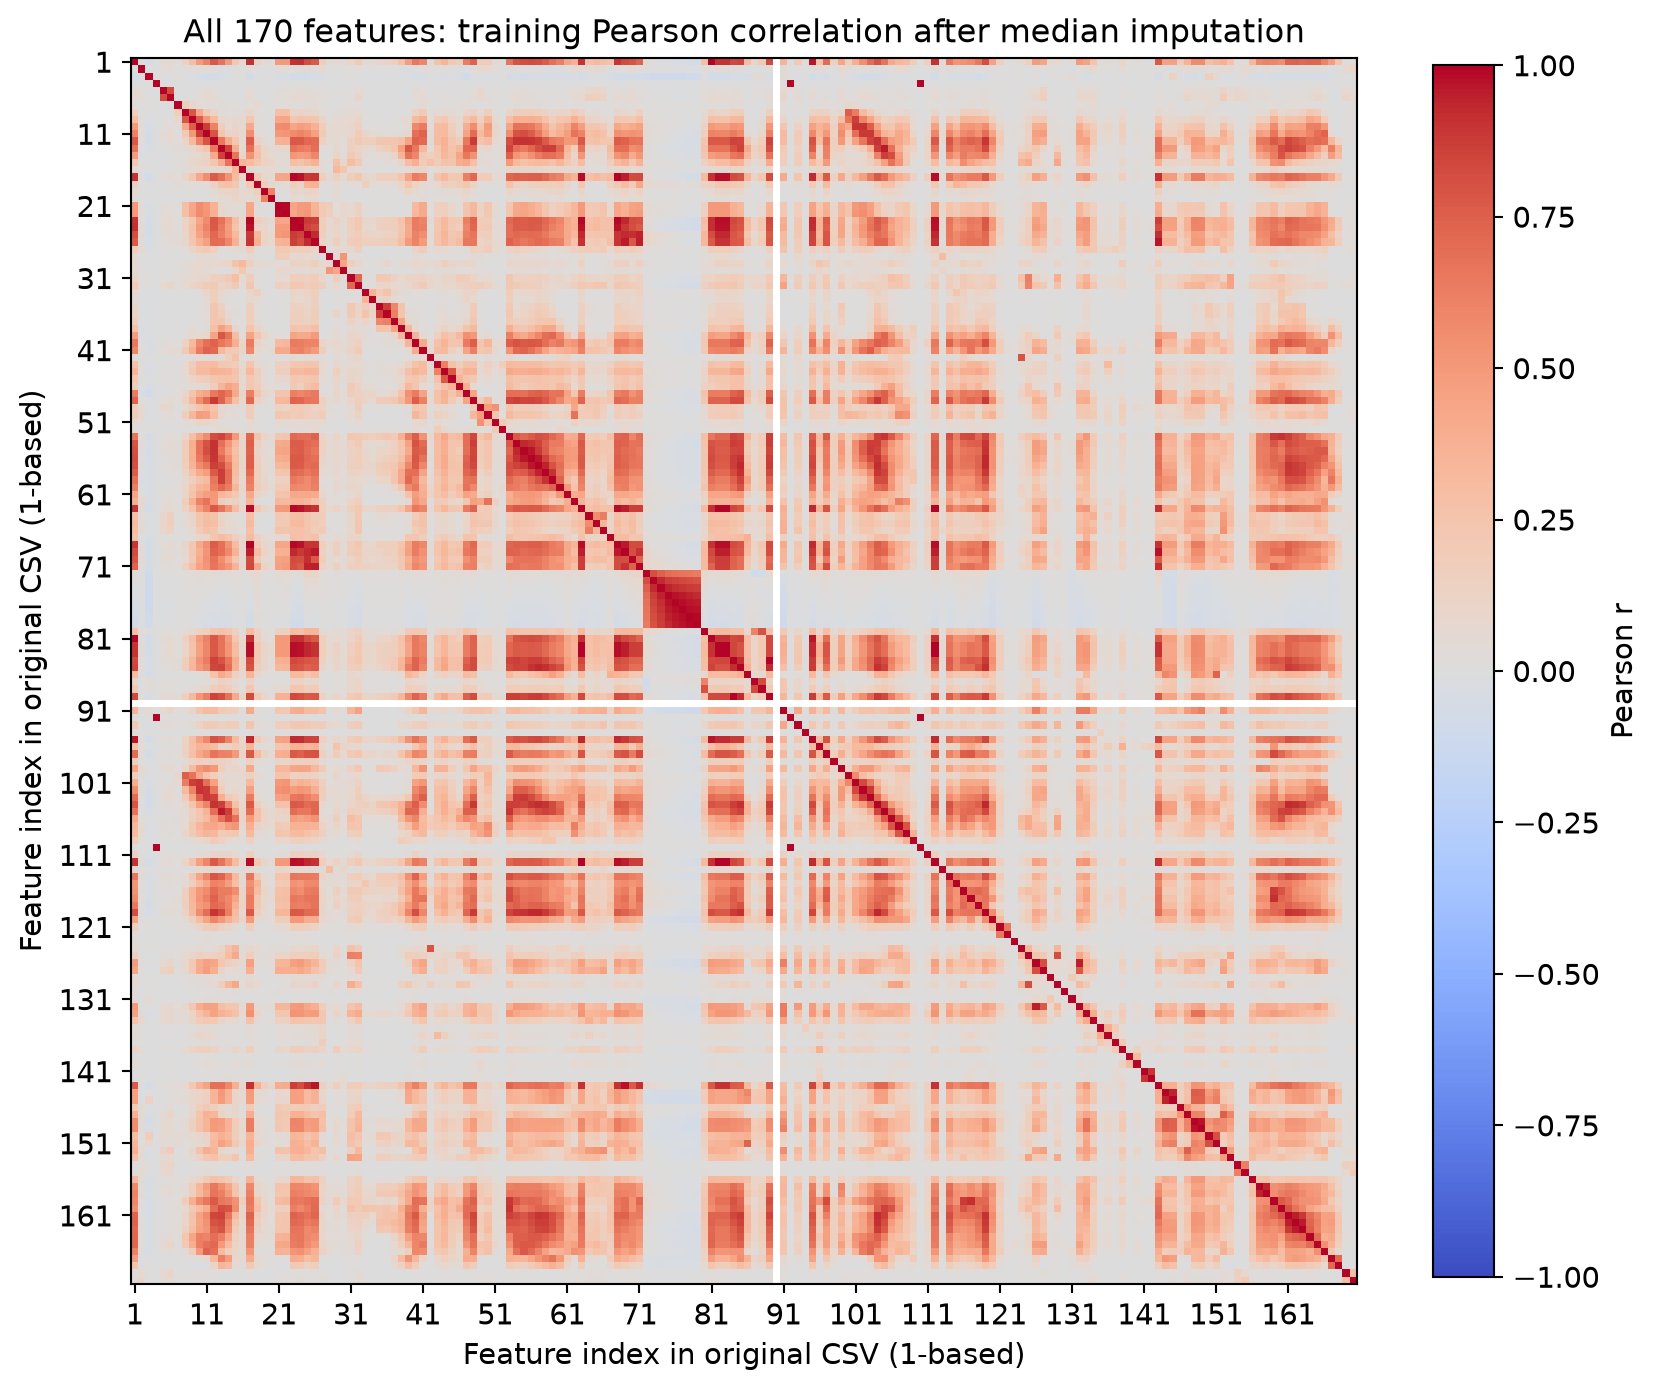

In [6]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / "correlation_overview.png"), width=1000))

Pearson correlations use all imputed training observations. Axes retain the CSV feature order and use 1-based indices to keep the full matrix readable on paper. The exact index-to-name mapping is in results/feature_index.csv; the large, individually labeled version is figures/correlation_all_labels.pdf (also PNG). The complete numerical matrix is results/correlation.csv.

The blocks of strong positive association are consistent with related operational counters and histogram bins. Correlation describes marginal linear relationships; it neither proves causation nor captures all nonlinear interactions. Median imputation can change correlations. The diagonal is one, and the numerical matrix is checked for symmetry. Strong correlations can make separate feature effects difficult to interpret.

## 1(b)(iv). Scatter plots for the top 13 CV features

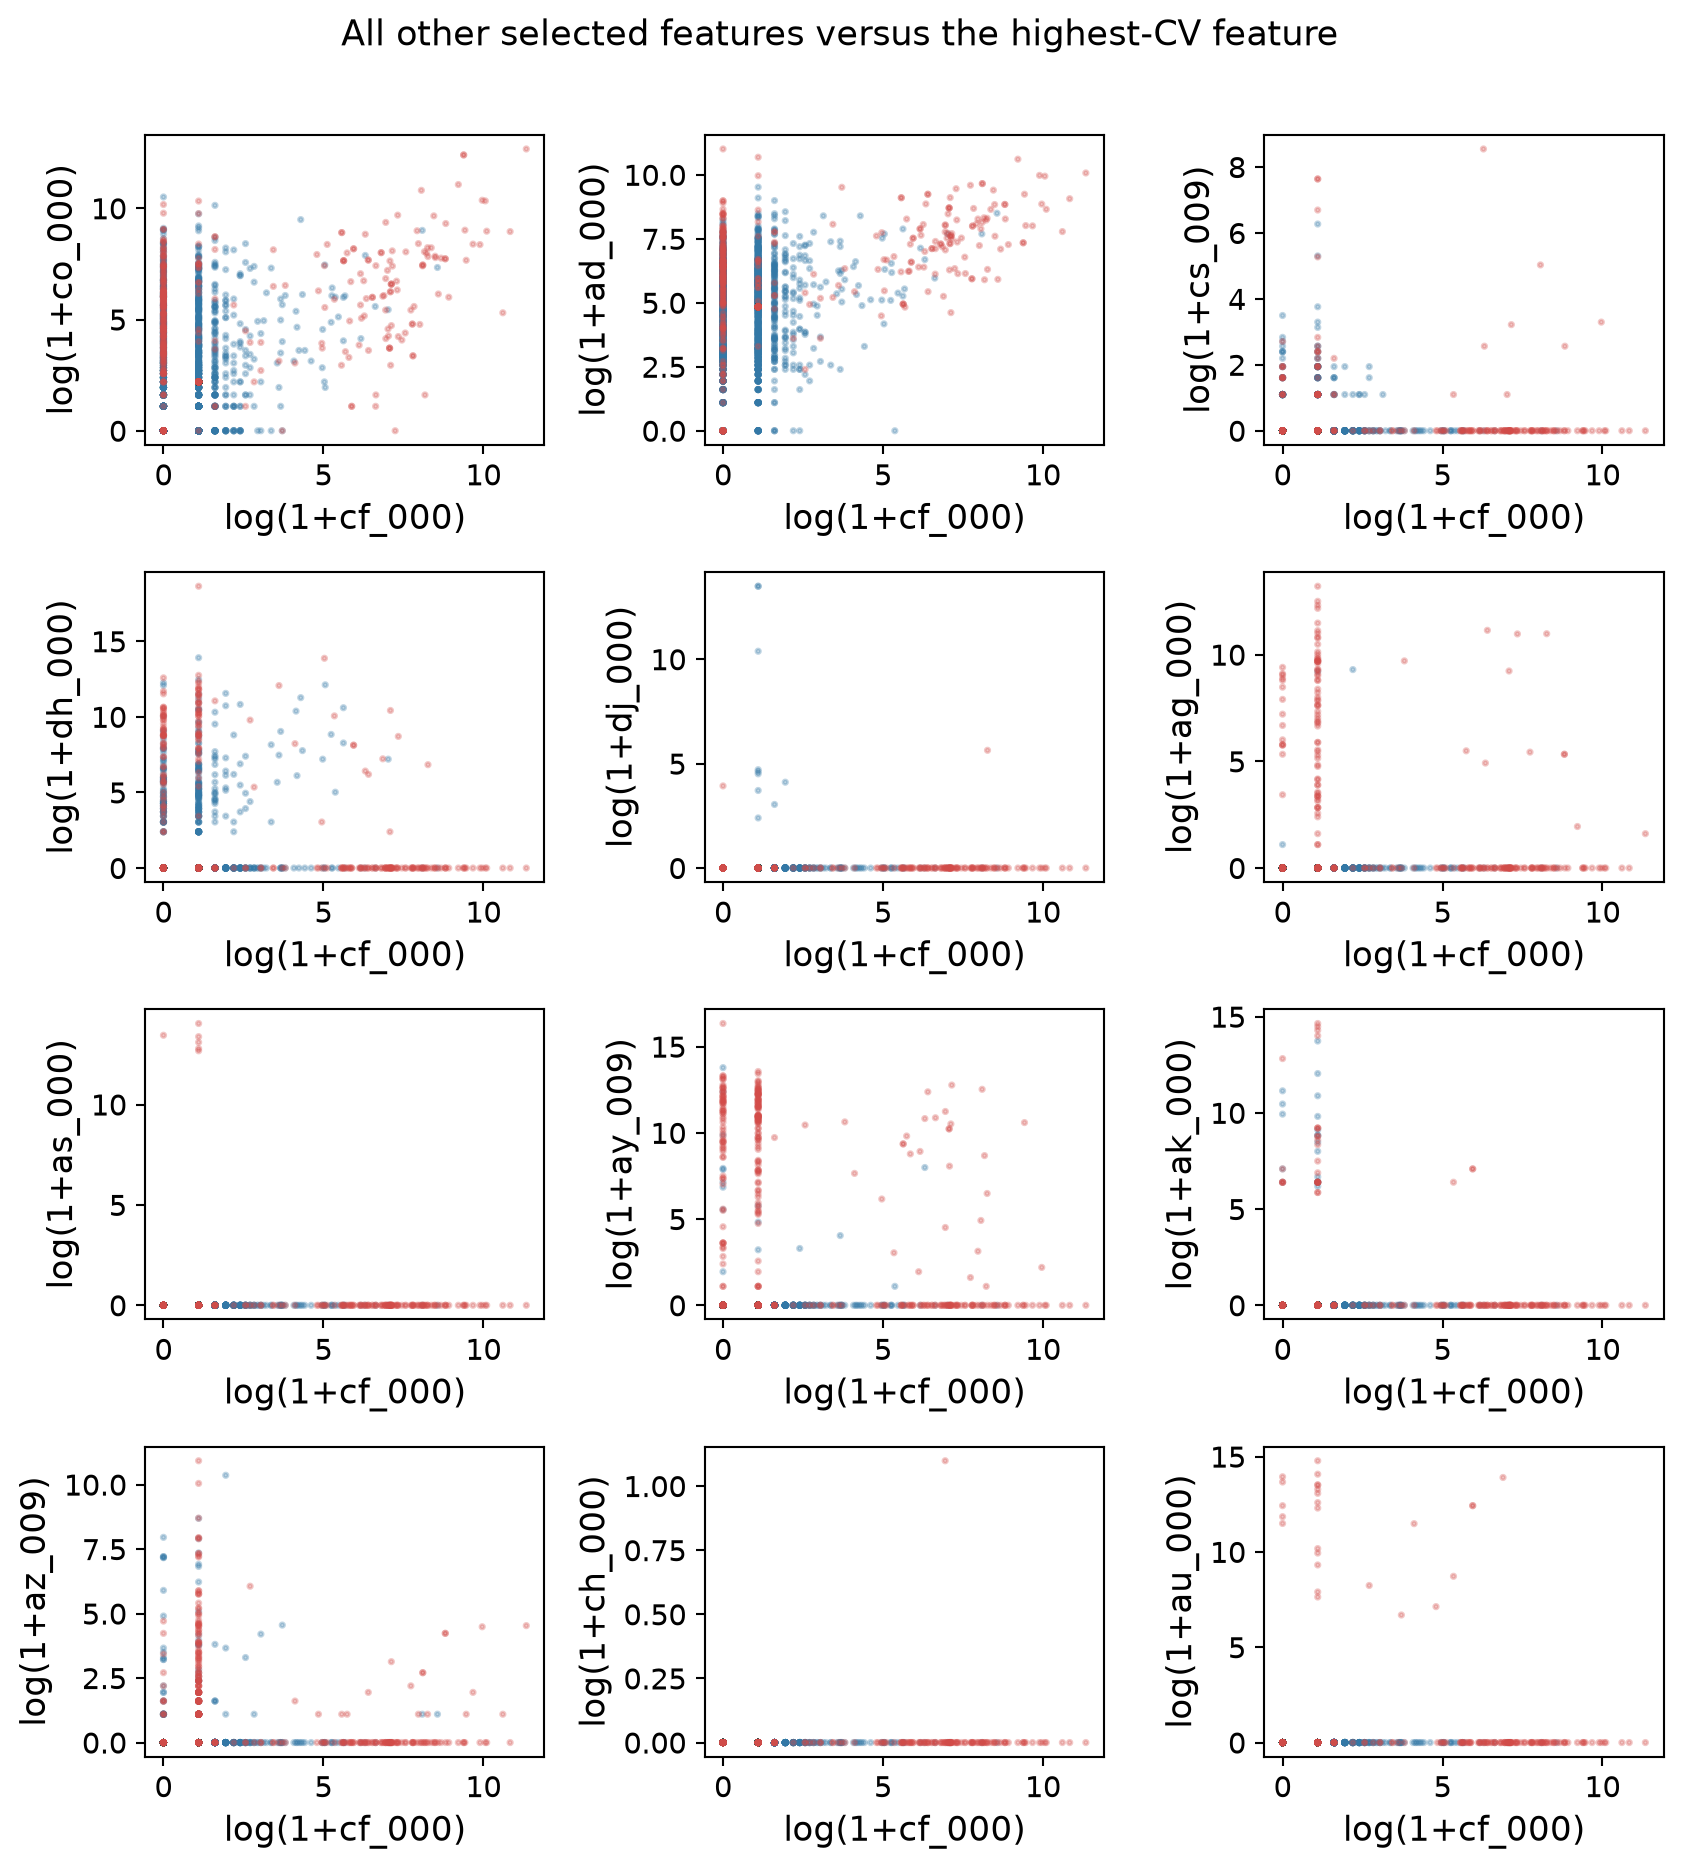

In [7]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / "scatter_report.png"), width=1000))

Each of the other 12 selected features is plotted against the highest-CV feature. Blue denotes neg and red denotes pos. For readable skewed counters, axes use log(1+x). Sampling uses seed 552 and includes all 1,000 positives plus 2,500 randomly selected negatives: 3,500 training observations. This deliberate class-stratified display is not representative of class prevalence.

The complete 13-by-13 scatter matrix, including every pair, is provided in the executed notebook and figures/scatter_all13.pdf. No model is fitted to the plotting subsample. The transformations are for visualization only.

## 1(b)(iv)-(v). Box plots and class imbalance

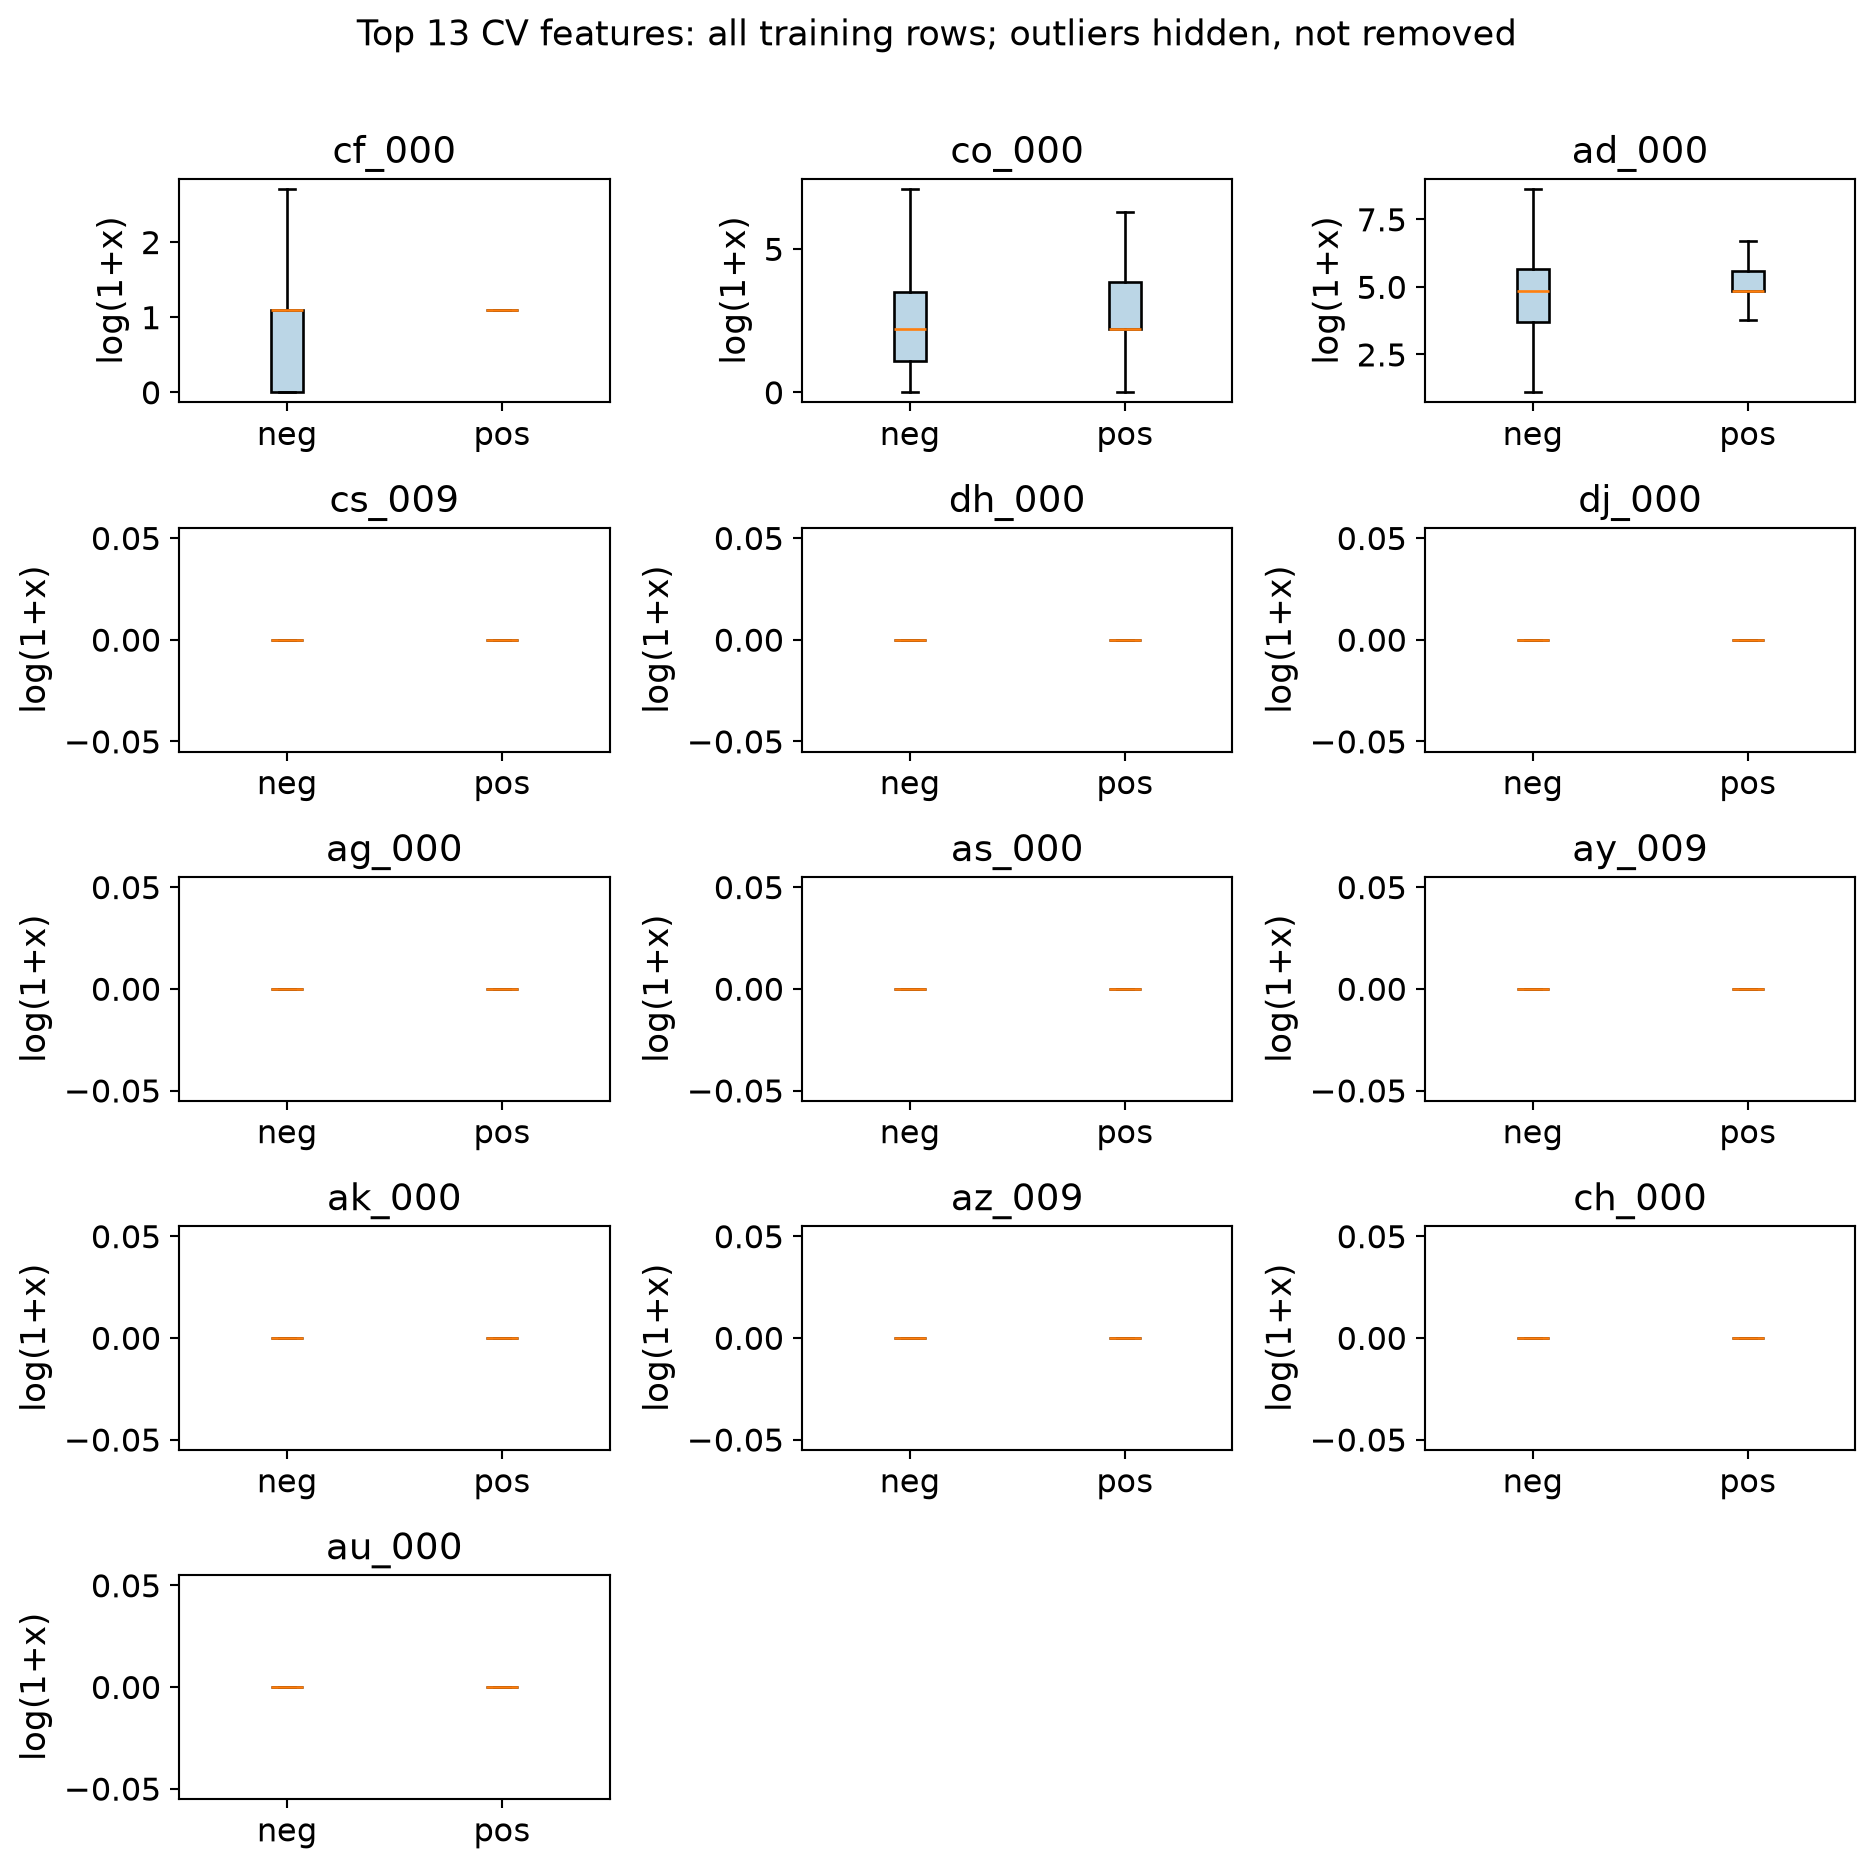

In [8]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / "boxplots13.png"), width=1000))

Boxes use all 60,000 imputed training rows, separated by class, with log(1+x) axes. Outlier markers are hidden to expose the boxes; no observations are deleted. Several low-frequency features concentrate at zero, so a class box can collapse to a line.

Scatter plots alone cannot establish significance: they omit conditional effects, have overplotting, and involve many inspected pairs. A visual association does not supply a hypothesis test or independent evidence of predictive value. Model-based validation or a carefully specified inferential analysis would be needed.

The training ratio is 59:1 (positive prevalence 1.667%); test prevalence is 2.344% with 15,625 negatives and 375 positives. Both splits are severely imbalanced. Always predicting neg yields errors of 1.667% and 2.344%, respectively, while missing every positive. Therefore positive precision, recall, F1 and average precision accompany the required error and ROC-AUC.

## 1(c). Random forest without imbalance compensation

Both forests use 500 fully grown Gini trees, bootstrap sampling, sqrt(170) candidate features per split, minimum leaf size 1, seed 552 and 4 workers. The entire official training set is used. A prediction is pos when the positive-class probability is at least 0.5 (including exact ties). ROC and AUC use probabilities, not hard labels.

This baseline uses class_weight=None and no resampling. OOB predictions aggregate only trees for which the observation was absent from the bootstrap sample. The reported OOB error uses the same 0.5 rule as all other confusion matrices.

| Split | Error | ROC-AUC | AP | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| Train | 0.00000 | 1.00000 | 1.00000 | 1.00000 | 1.00000 | 1.00000 |
| Test | 0.00775 | 0.99435 | 0.92609 | 0.93127 | 0.72267 | 0.81381 |

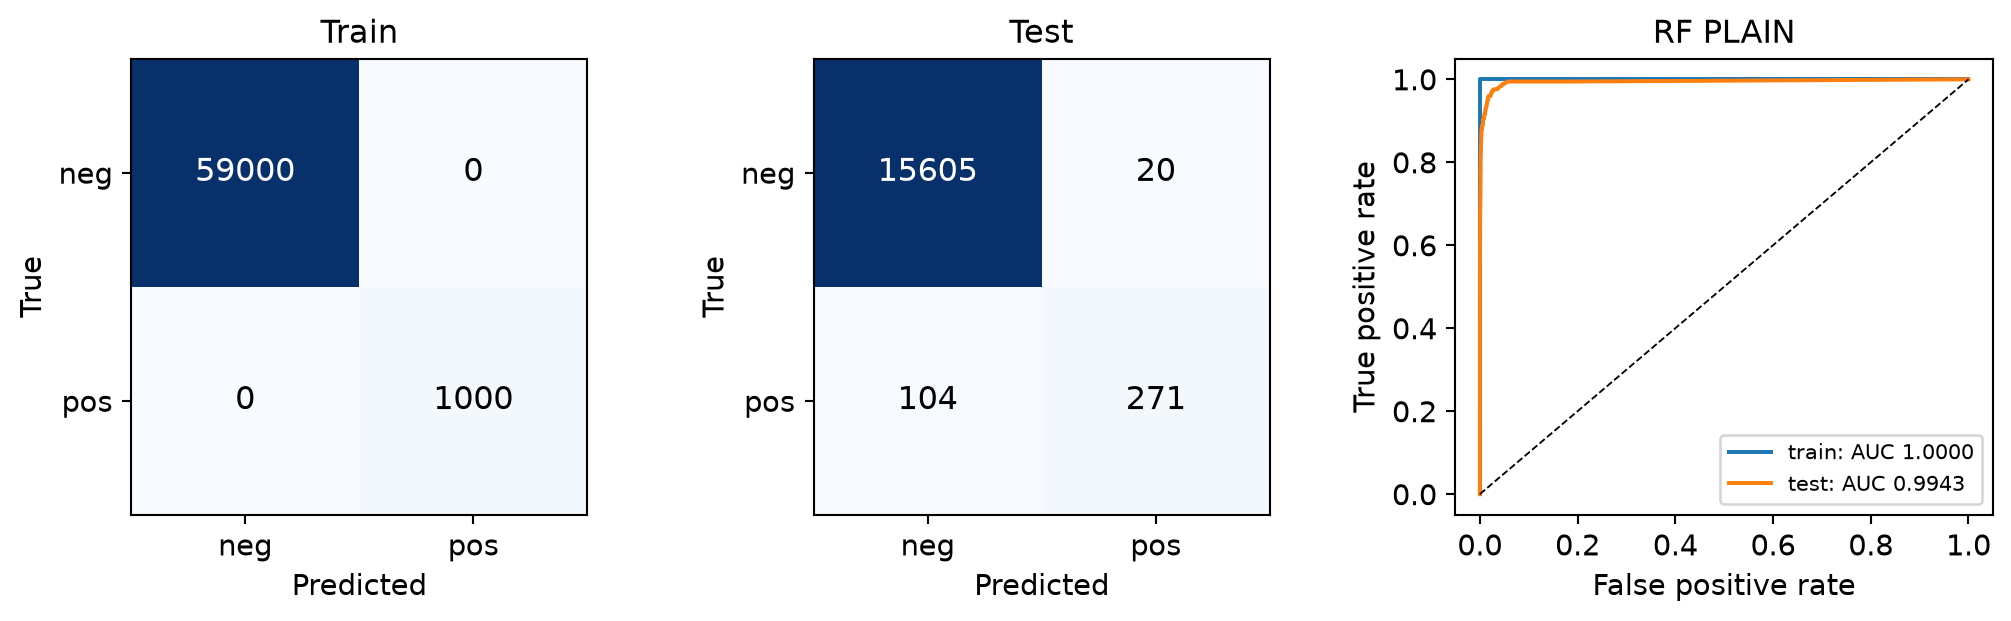

In [9]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / "rf_plain_evaluation.png"), width=1000))

OOB error = 0.00582; official test error = 0.00775; test minus OOB = 0.00193. Fit and evaluation took 70.9 seconds. OOB uses the global training imputation, so it is an approximate internal estimate rather than a fully cross-fitted preprocessing estimate. Test prevalence also differs from training.

Confusion matrices have true labels in rows and predicted labels in columns, ordered [neg, pos]. Training performance is resubstitution performance and can be optimistic for deep forests.

## 1(d). Random forest with class weighting

Both forests use 500 fully grown Gini trees, bootstrap sampling, sqrt(170) candidate features per split, minimum leaf size 1, seed 552 and 4 workers. The entire official training set is used. A prediction is pos when the positive-class probability is at least 0.5 (including exact ties). ROC and AUC use probabilities, not hard labels.

Chen, Liaw and Breiman [3] study cost-sensitive weighting and sampling for imbalanced forests. Here class_weight="balanced" weights class k by n/(2 n_k): approximately 0.5085 for neg and 30 for pos, a 59-fold ratio. All other forest settings are unchanged. This weights split impurity and fitted class probabilities; it does not guarantee higher minority recall [4].

| Split | Error | ROC-AUC | AP | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| Train | 0.00013 | 1.00000 | 1.00000 | 0.99206 | 1.00000 | 0.99602 |
| Test | 0.00944 | 0.99418 | 0.88701 | 0.83735 | 0.74133 | 0.78642 |

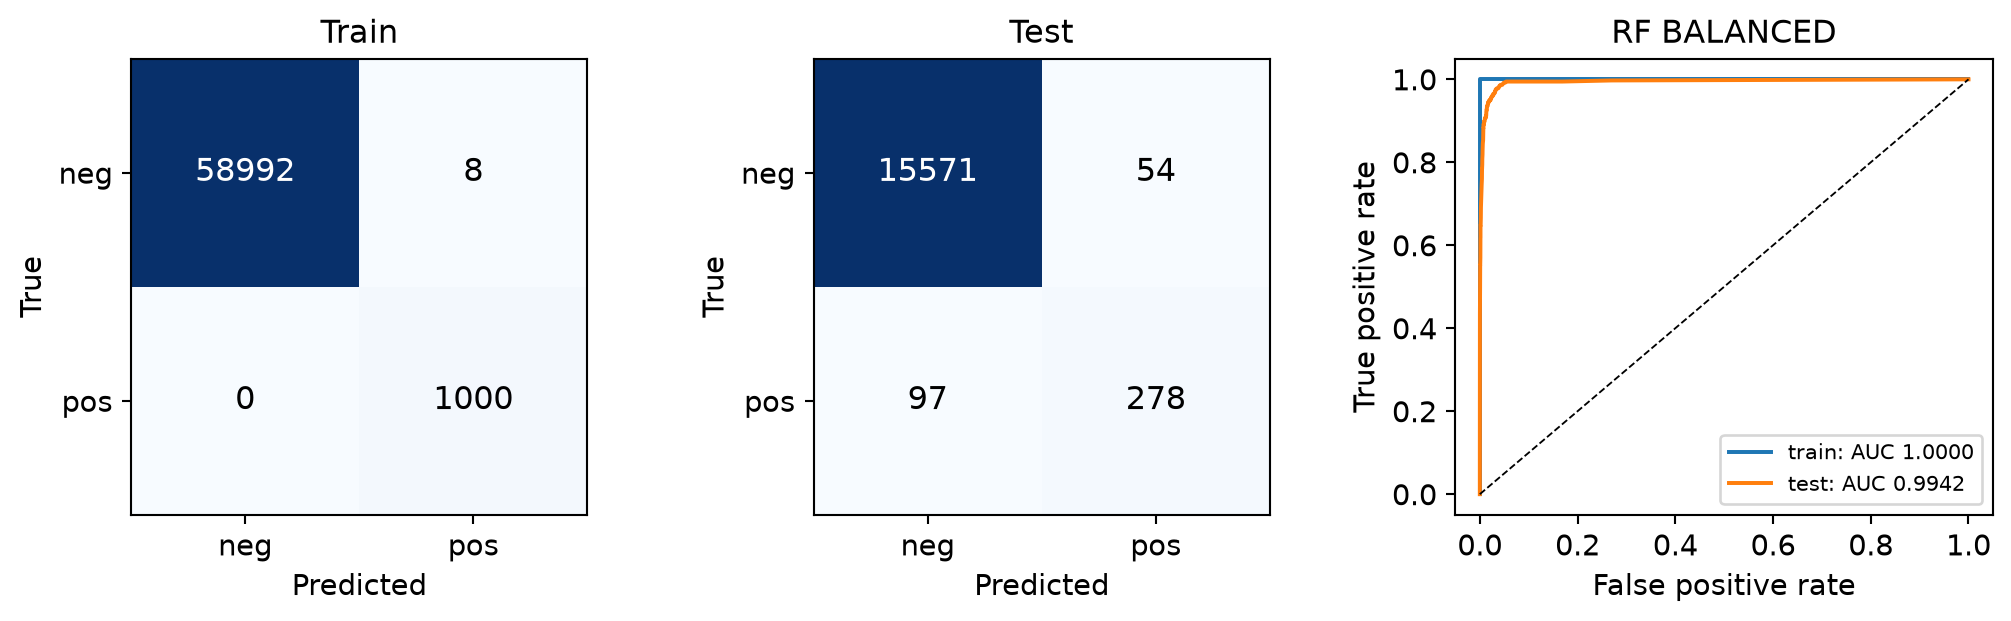

In [10]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / "rf_balanced_evaluation.png"), width=1000))

OOB error = 0.01998; official test error = 0.00944; test minus OOB = -0.01055. Fit and evaluation took 44.3 seconds. OOB uses the global training imputation, so it is an approximate internal estimate rather than a fully cross-fitted preprocessing estimate. Test prevalence also differs from training.

Confusion matrices have true labels in rows and predicted labels in columns, ordered [neg, pos]. Training performance is resubstitution performance and can be optimistic for deep forests.

Compared with the unweighted forest, weighting changes test recall from 0.7227 to 0.7413 and precision from 0.9313 to 0.8373. Its observed behavior, rather than the compensation label alone, determines whether it helps. A small overall error can be achieved by emphasizing the abundant negatives; recall directly exposes missed APS failures.

## 1(e). XGBoost interpretation and validation design

The installed XGBoost version is 3.4.1. Its local XGBClassifier API and the matching v3.4.1 parameter documentation were inspected [5]. The homework describes logistic regressions at tree nodes, but the standard gbtree booster uses feature-threshold splits and scalar leaf scores. binary:logistic applies a logistic loss/link to the summed score. reg_alpha is an L1 penalty on leaf weights; it does not fit a logistic regression at every node.

$$
P(Y=1\mid x)=\sigma\!\left(\sum_{t=1}^{T}f_t(x)\right),\quad\Omega(f_t)=\gamma L_t+\frac{\lambda}{2}\sum_\ell w_{t\ell}^2+\alpha\sum_\ell|w_{t\ell}|
$$

gblinear instead fits a global linear model, with L1-regularized coefficients; it is not a tree model. A true logistic model tree combines a tree with local logistic models and needs a different implementation. No local course clarification was found. The runnable interpretation here is gbtree + binary:logistic + tuned reg_alpha; it satisfies the XGBoost/alpha experiment but does not claim to realize the described node-level model tree. Instructor confirmation of that wording remains appropriate.

Fixed before test evaluation: 250 rounds, depth 4, learning rate 0.08, L2 penalty 1, max_bin 256, min_child_weight 1, subsample = colsample_bytree = 1, histogram trees on CPU, 4 threads, base_score 0.5. There is no early stopping or test-based choice of rounds/thresholds. There is no class weighting or resampling in this section.

Stratified shuffled 5-fold CV (seed 552) uses the full 60,000 training rows, with 48,000 fitting rows and 12,000 validation rows per fold. The imputer and StandardScaler are fitted inside the training fold. Scaling is shared with 1(f) to isolate the SMOTE comparison; it is not needed for tree splits. Alpha maximizes mean validation average precision (AP), with smaller alpha breaking exact ties. AP rewards ranking of rare positives; CV misclassification at 0.5 is also reported.

| Alpha | Mean CV AP | AP SD | Mean CV error | Error SD |
| --- | --- | --- | --- | --- |
| 0 | 0.88760 | 0.01406 | 0.00562 | 0.00055 |
| 0.001 | 0.88568 | 0.01212 | 0.00577 | 0.00054 |
| 0.01 | 0.88727 | 0.01173 | 0.00568 | 0.00064 |
| 0.1 | 0.88643 | 0.01335 | 0.00582 | 0.00064 |
| 1 | 0.88472 | 0.01300 | 0.00598 | 0.00084 |
| 10 | 0.86932 | 0.01362 | 0.00658 | 0.00063 |
| 100 | 0.78346 | 0.02698 | 0.00943 | 0.00089 |

## 1(e). XGBoost without compensation: results

The selected alpha is 0. Mean validation AP is 0.88760; mean CV misclassification error is 0.00562, with fold SD 0.00055. Selection used only training-fold validation predictions.

| Split | Error | ROC-AUC | AP | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| Train | 0.00118 | 0.99959 | 0.99088 | 0.99679 | 0.93200 | 0.96331 |
| Test | 0.00637 | 0.99623 | 0.93199 | 0.95652 | 0.76267 | 0.84866 |

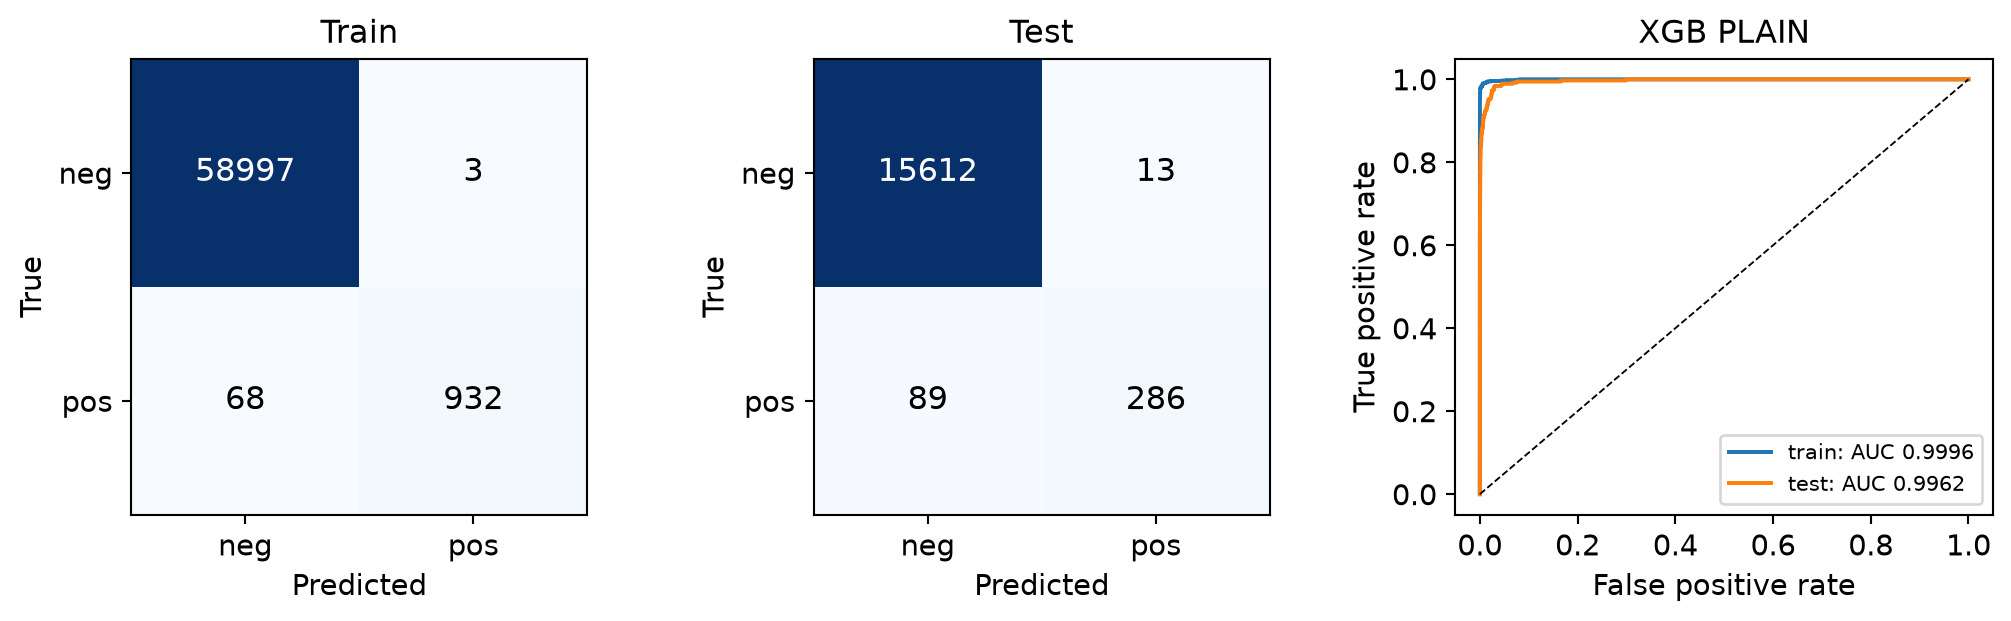

In [11]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / "xgb_plain_evaluation.png"), width=1000))

Test error (0.00637) minus selected-alpha CV error (0.00562) is 0.00076. CV fits use 80% of training rows and train-only fold preprocessing, whereas the final model uses all training rows and the main test evaluation follows the footnote. Distribution/prevalence differences can also affect this gap.

The selected mean CV performance is a tuning estimate, not an independent, unbiased estimate of the whole selection procedure. Nested CV was not required or performed. The untouched official test set gives the final evaluation after tuning. Fold SD is descriptive variation across five dependent folds, not a confidence interval.

The final fit and evaluation took 1.9 seconds; the 35 CV fits took 99.4 seconds in total. Full per-fold scores and times are saved in results/xgb_plain_cv_folds.csv. AP is sklearn average_precision_score (a recall-weighted precision sum), not trapezoidal PR-AUC.

## 1(f). SMOTE: full-data and fold-safe design

SMOTE creates a synthetic positive between an observed minority point and one of its minority nearest neighbors [7]. A single seeded imblearn Pipeline applies: training-fold median imputer, training-fold StandardScaler, SMOTE(k_neighbors=5, sampling_strategy=1.0), then the same XGBoost estimator as 1(e). CV runs serially and each model uses 4 threads to avoid nested parallel oversubscription.

$$
x_{new}=x_i+u(x_{neighbor}-x_i),\qquad u\sim U(0,1)
$$

Distance is computed after standardizing all 170 features using current training-fold statistics; otherwise large-unit counters dominate Euclidean neighbors. Standardization still cannot eliminate high-dimensional distance issues, skew or imputation artifacts. No log transformation is applied in the model pipeline.

| Stage | neg | Original pos | Final pos | Total |
| --- | --- | --- | --- | --- |
| Each CV training fold | 47,200 | 800 | 47,200 | 94,400 |
| Final full training fit | 59,000 | 1,000 | 59,000 | 118,000 |
| Each validation fold (unchanged) | 11,800 | 200 | 200 | 12,000 |
| Official test (unchanged) | 15,625 | 375 | 375 | 16,000 |

The validation rows are never passed to fit_resample; resampling before splitting would leak neighbor information and invalidate validation [8]. Cache reuse is restricted to identical training-fold inputs and settings. Final SMOTE uses the entire original training set without downsampling. All reported training metrics are evaluated on the original 60,000 observations, not the synthetic population.

The same folds, alpha grid, selection metric, fixed rounds and classification rule are used as in 1(e). Alpha is reselected for the SMOTE procedure; its effect depends on changed sample size and gradients.

| Alpha | Mean CV AP | AP SD | Mean CV error | Error SD |
| --- | --- | --- | --- | --- |
| 0 | 0.84750 | 0.02992 | 0.00977 | 0.00057 |
| 0.001 | 0.84761 | 0.02998 | 0.00975 | 0.00057 |
| 0.01 | 0.84911 | 0.02871 | 0.00985 | 0.00065 |
| 0.1 | 0.84890 | 0.03101 | 0.00990 | 0.00093 |
| 1 | 0.84974 | 0.03083 | 0.00990 | 0.00083 |
| 10 | 0.84177 | 0.02887 | 0.01052 | 0.00070 |
| 100 | 0.78665 | 0.02999 | 0.02017 | 0.00159 |

## 1(f). SMOTE + XGBoost: results and tradeoffs

Selected alpha = 1; mean CV AP = 0.84974; mean CV error = 0.00990 (fold SD 0.00083). The final data contain 59,000 negatives and 59,000 positives. Full-data SMOTE took 0.13 seconds, and final scaling, SMOTE, fit and evaluation took 4.7 seconds.

| Split | Error | ROC-AUC | AP | Precision | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| Train | 0.00583 | 0.99885 | 0.96342 | 0.75712 | 0.95700 | 0.84541 |
| Test | 0.01600 | 0.99365 | 0.88362 | 0.60799 | 0.89333 | 0.72354 |

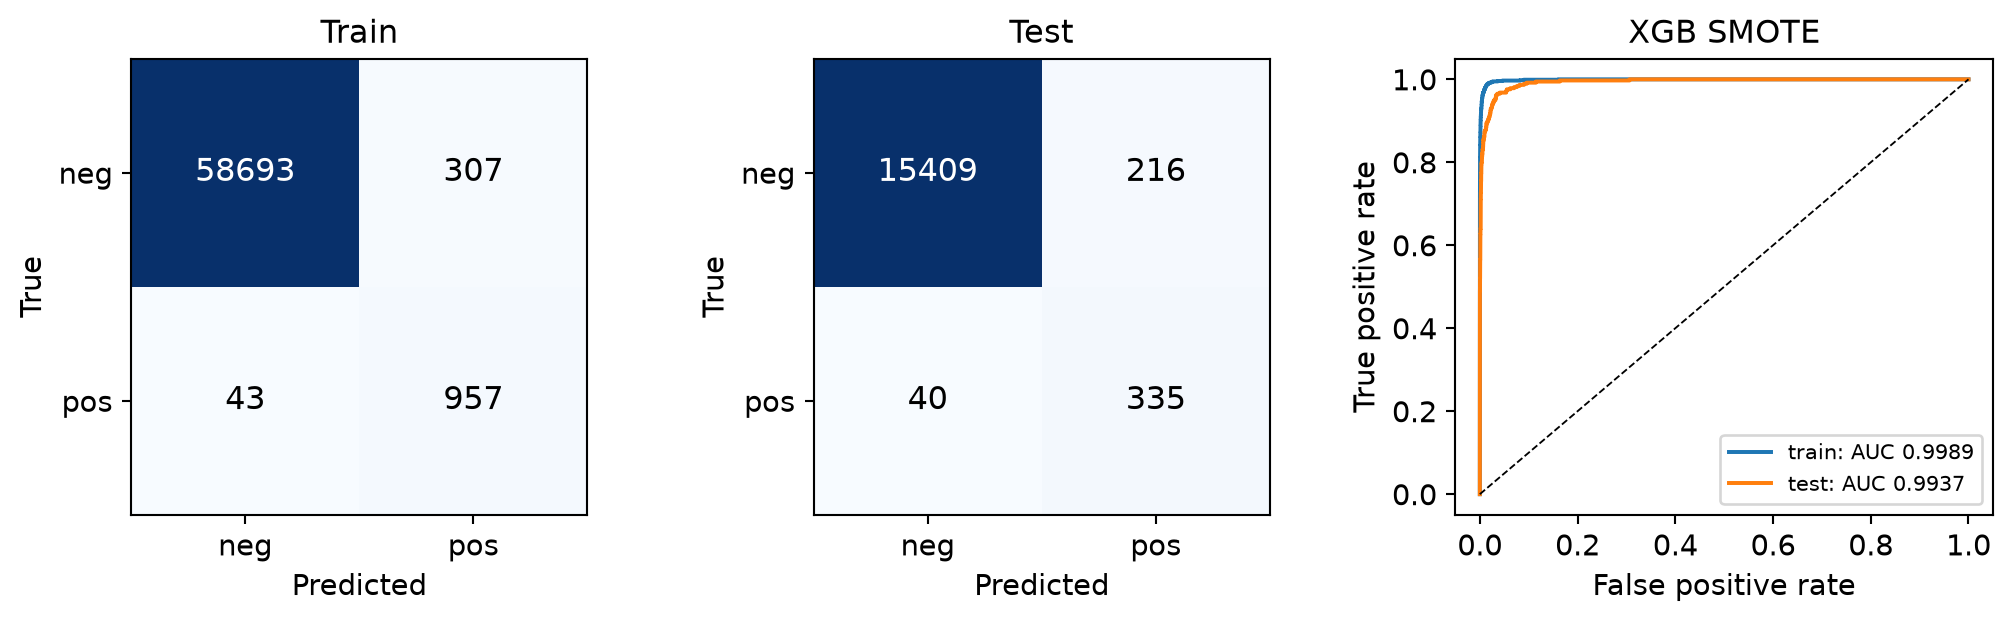

In [12]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / "xgb_smote_evaluation.png"), width=1000))

Test error minus selected-alpha CV error is 0.00610. The 35 CV fits required 143.6 seconds in total, including fold preprocessing and cached reuse. Both alpha searches include all original training observations; only the fold fitting sets are oversampled.

Without SMOTE, test precision/recall are 0.9565/0.7627, with 13 false positives and 89 false negatives. With SMOTE they are 0.6080/0.8933, with 216 false positives and 40 false negatives. These counts expose the minority-recall versus unnecessary-inspection tradeoff.

Oversampling changes the fitted class prior and may distort probability calibration. A 0.5 threshold is retained for comparability, rather than optimized on official test labels. Scores should not automatically be interpreted as calibrated failure probabilities in the original population.

## 1(c)-(f). Unified comparison and sensitivity

| Model / test | Error | ROC-AUC | AP | Prec. | Recall | F1 |
| --- | --- | --- | --- | --- | --- | --- |
| RF: unweighted | 0.0077 | 0.9943 | 0.9261 | 0.9313 | 0.7227 | 0.8138 |
| RF: balanced | 0.0094 | 0.9942 | 0.8870 | 0.8373 | 0.7413 | 0.7864 |
| XGB: unweighted | 0.0064 | 0.9962 | 0.9320 | 0.9565 | 0.7627 | 0.8487 |
| XGB: SMOTE | 0.0160 | 0.9937 | 0.8836 | 0.6080 | 0.8933 | 0.7235 |

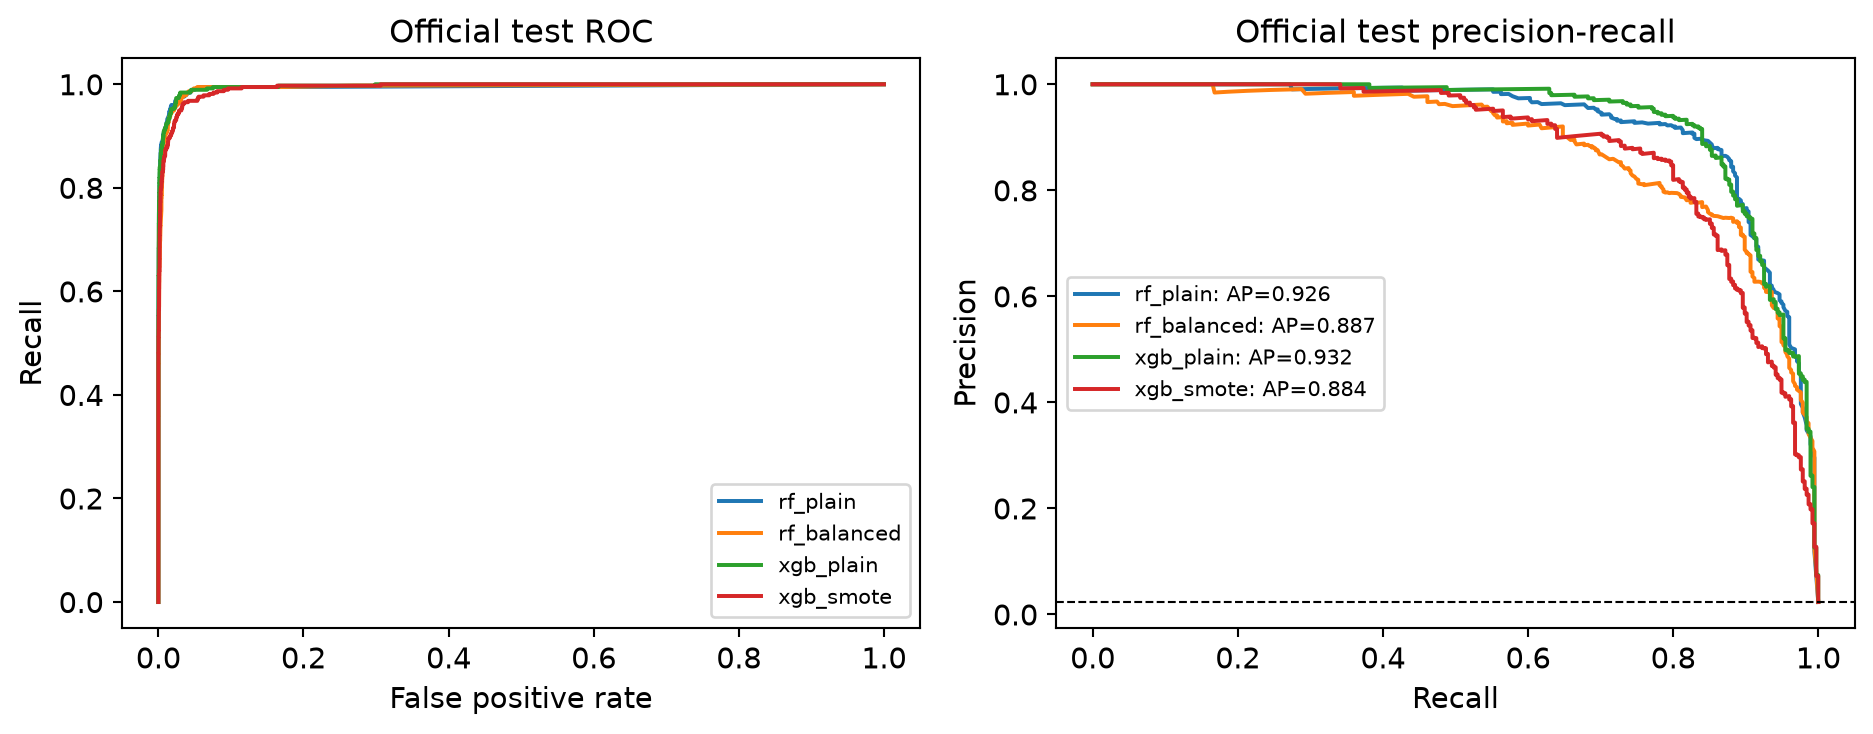

In [13]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / "model_comparison.png"), width=1000))

### Sensitivity: fit the imputer on training data only

Each model is held fixed; only missing official-test values change from test medians (main results) to fitted training medians. The scaler, where present, always uses training statistics. This is a post-fit robustness comparison, not an additional selection criterion. SMOTE is sensitive to this convention: train-only test imputation reduces its error from 1.600% to 1.075%, with false positives falling from 216 to 125 and false negatives rising from 40 to 47. Synthetic neighbors can amplify shifts in imputed feature values. This makes the preprocessing convention a material part of the result.

| Model | Main error | Train-only error | Main AP | Train-only AP |
| --- | --- | --- | --- | --- |
| RF: unweighted | 0.00775 | 0.00775 | 0.92609 | 0.92614 |
| RF: balanced | 0.00944 | 0.00944 | 0.88701 | 0.88716 |
| XGB: unweighted | 0.00637 | 0.00625 | 0.93199 | 0.93160 |
| XGB: SMOTE | 0.01600 | 0.01075 | 0.88362 | 0.89974 |

ROC-AUC measures ranking across both classes; AP focuses on precision along minority recall and depends on prevalence. The dashed PR baseline is the test positive prevalence (0.02344). No model or operating threshold was selected using this figure. Comparisons apply to this fixed protocol and one official test set.

The data description assigns cost 10 to an unnecessary inspection and 500 to a missed failure. For context, test cost (10 FP + 500 FN) is RF: unweighted: 52,200, RF: balanced: 49,040, XGB: unweighted: 44,630, XGB: SMOTE: 22,160. These retrospective costs did not guide parameter or threshold selection.

## Question 2. ISLR 6.6.3: relaxing the lasso constraint

Edition check: ISLR second edition (2021, corrected June 21, 2023), Section 6.6, Exercise 3. The first edition places the same exercise in 6.8. The problem minimizes training residual sum of squares with an unpenalized intercept under an L1 coefficient bound s [1].

$$
\min_{\beta_0,\beta}\sum_i\left(y_i-\beta_0-\sum_j x_{ij}\beta_j\right)^2\quad\mathrm{subject\ to}\quad\sum_j|\beta_j|\leq s
$$

**(a) Training RSS: option iv, decreases (more precisely, is nonincreasing).** If s2 is at least s1, every solution feasible at s1 remains feasible at s2. Minimizing over a larger set cannot increase training RSS. At s = 0, all slopes vanish and only the sample-mean intercept remains. Once a least-squares solution is feasible, RSS can stay constant.

**(b) Test RSS: option ii, typically decreases and then increases (a U shape).** Initially loosening a tight constraint can reduce underfitting. Excess flexibility eventually increases estimation variance and can worsen held-out fit. This is the intended bias-variance pattern, not a guaranteed shape for every realized test set.

**(c) Variance: option iii, typically increases.** A larger radius weakens shrinkage and allows coefficients to react more strongly to training-sample noise.

**(d) Squared bias: option iv, typically decreases.** Less shrinkage removes the distortion imposed by a tight L1 bound. This describes the usual statistical trend rather than a universal monotonic theorem for arbitrary designs and data-generating functions.

**(e) Irreducible error: option v, remains constant.** The conditional noise variance is a property of the data-generating process; changing a fitting constraint cannot change it.

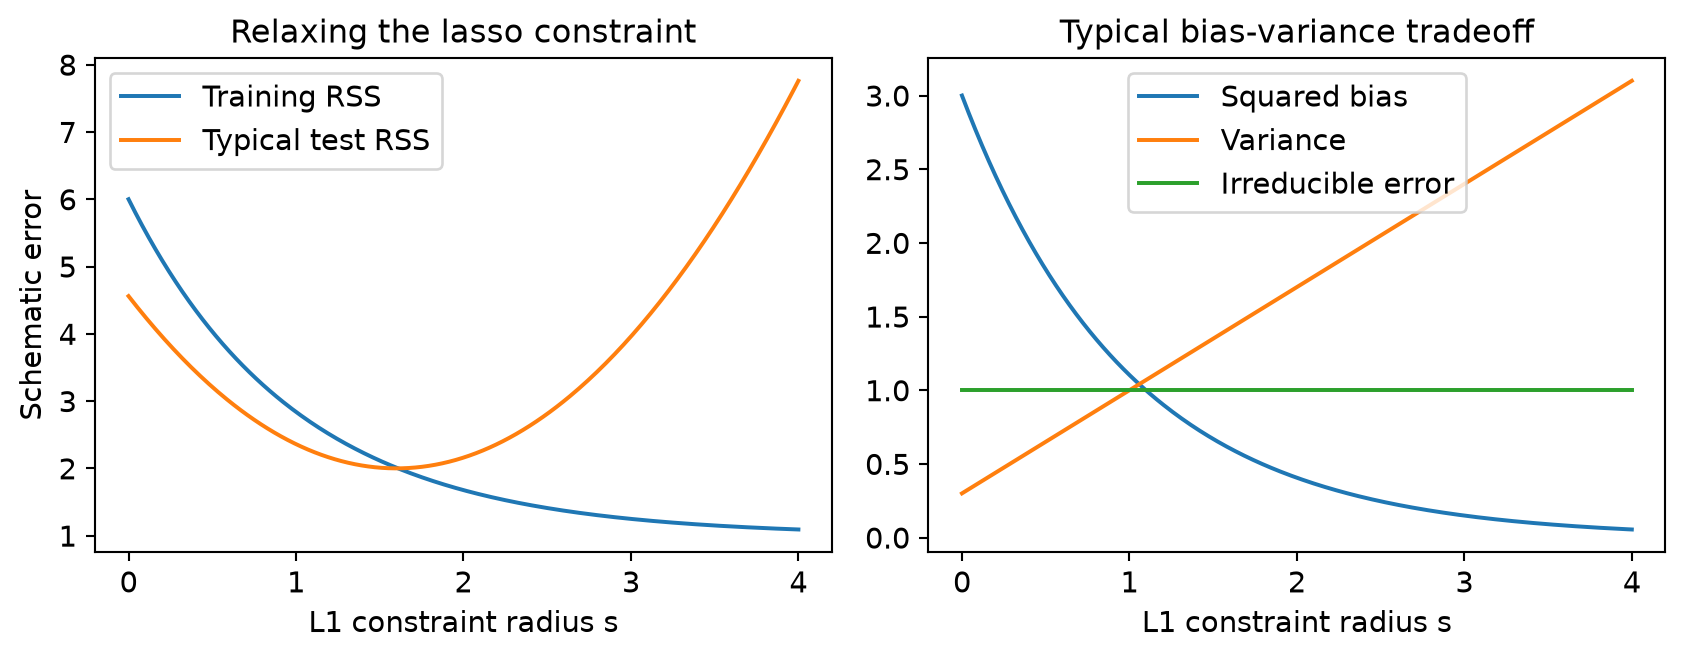

In [14]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / "q2_shapes.png"), width=1000))

These plots are schematic illustrations, not outputs of the APS experiments. Only the nested-feasible-set argument in (a) guarantees monotonicity; actual test curves may be noisy or have their minimum at a boundary.

## Question 3. ISLR 6.6.5: identical predictors

ISLR second edition Section 6.6 Exercise 5 (first edition: 6.8.5). Let x1 = x11 = x12 and x2 = x21 = x22, with centered x and y, so the fitted intercept is zero. Assume a nonzero predictor column and a positive penalty unless stated otherwise. Put t = beta1 + beta2, A = x1 squared + x2 squared > 0, and C = x1 y1 + x2 y2.

### (a) Ridge objective

$$
\min_{\beta_1,\beta_2}\ (y_1-x_1\beta_1-x_1\beta_2)^2+(y_2-x_2\beta_1-x_2\beta_2)^2+\lambda(\beta_1^2+\beta_2^2)
$$

### (b) Why the ridge coefficients are equal

For a fixed sum t, the residual term depends only on t. The identity below shows that the penalty is uniquely minimized by beta1 = beta2 = t/2. Equivalently, subtracting the two normal equations gives 2 lambda (beta1 - beta2) = 0. Strict convexity from lambda > 0 makes the solution unique.

$$
\beta_1^2+\beta_2^2=\frac{t^2}{2}+\frac{(\beta_1-\beta_2)^2}{2},\qquad\hat{\beta}_1=\hat{\beta}_2=\frac{C}{2A+\lambda}
$$

### (c) Lasso objective

$$
\min_{\beta_1,\beta_2}\ (y_1-x_1\beta_1-x_1\beta_2)^2+(y_2-x_2\beta_1-x_2\beta_2)^2+\lambda(|\beta_1|+|\beta_2|)
$$

### (d) Describe all minimizing coefficient pairs

The triangle inequality gives |beta1| + |beta2| >= |t|, with equality whenever the two coefficients have the same sign (allowing zero). Thus minimizing reduces to the one-dimensional objective A t squared - 2 C t + lambda |t| plus a constant. Its minimizer is the soft-thresholded sum below.

$$
t^*=\frac{\mathrm{sign}(C)(|C|-\lambda/2)_+}{A},\qquad(\hat{\beta}_1,\hat{\beta}_2)=(a t^*,(1-a)t^*),\quad 0\leq a\leq1
$$

When t* is nonzero, this continuum includes selecting only the first predictor, selecting only the second, and every same-sign split between them. All pairs have identical fitted values and identical L1 penalty. This explains why a lasso solver can treat perfectly correlated variables differently.

Boundary qualifications: if lambda >= 2|C| and lambda > 0, t* = 0 and only (0,0) minimizes, so nonuniqueness is not universal. If lambda = 0, any pair summing to C/A is least-squares optimal, including opposite signs; the equality claim for ridge is then not forced. These qualifications refine the exercise's generic nonuniqueness statement.

## Question 4. ISLR 8.4.5: votes versus probabilities

Both checked R editions place this exercise in Section 8.4, Exercise 5. For one fixed predictor value, ten bootstrap classification trees return the following red-class probabilities [1].

| Tree | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| P(Red) | 0.10 | 0.15 | 0.20 | 0.20 | 0.55 | 0.60 | 0.60 | 0.65 | 0.70 | 0.75 |

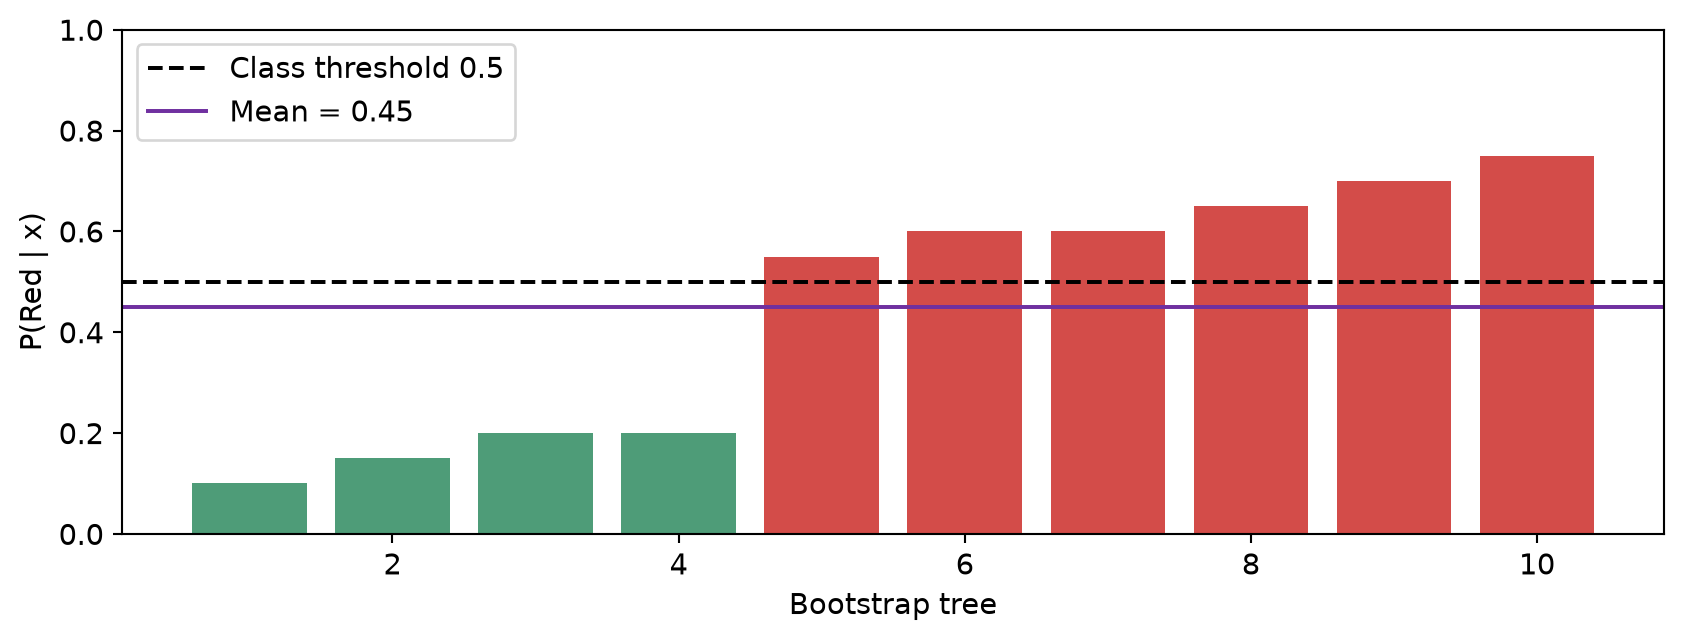

In [15]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / "q4_votes.png"), width=1000))

### Majority vote: Red

Applying a 0.5 rule separately to each tree gives four Green votes from trees 1-4 and six Red votes from trees 5-10. Six of ten hard predictions are Red, so the majority-vote ensemble predicts Red. No individual probability is exactly 0.5, so the tie convention is irrelevant.

### Average probability: Green

$$
\bar p_{Red}=\frac{0.10+0.15+0.20+0.20+0.55+0.60+0.60+0.65+0.70+0.75}{10}=0.45
$$

Averaging probabilities gives Red probability 0.45 and Green probability 0.55, so the probability-average rule predicts Green. The few low Red probabilities can outweigh a larger number of moderately high Red probabilities.

Hard voting counts how many models favor a class and discards their confidence. Probability averaging retains the numerical magnitudes. The two aggregation methods need not agree. The random forests in Question 1 use sklearn probability averaging followed by the explicitly recorded 0.5 threshold; this exercise should not be read as a claim that every software implementation votes on hard labels.

## Question 5. ISLR 9.7.3: maximal-margin geometry

Both checked R editions place this seven-observation problem in Section 9.7, Exercise 3. The numbered observations and constructions are shown below; the black dashed lines are supporting lines, not additional decision boundaries.

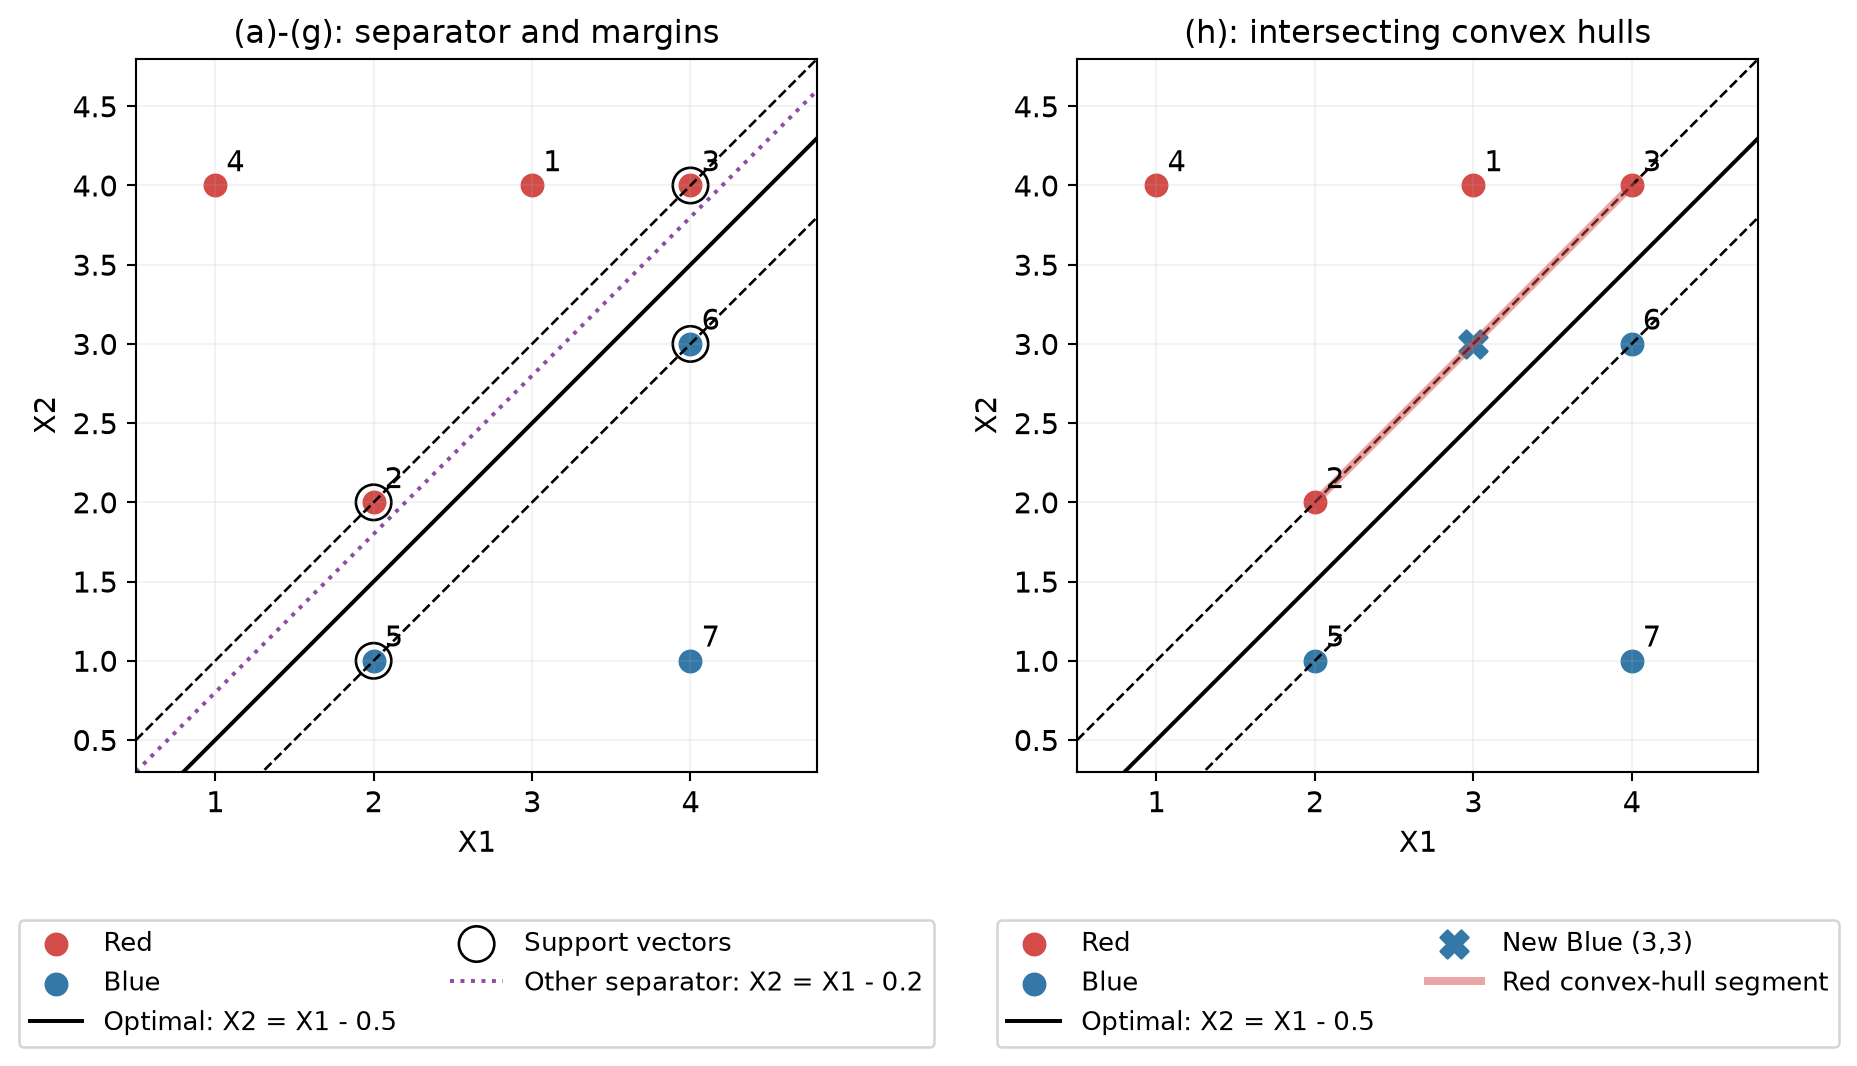

In [16]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / "q5_geometry.png"), width=1000))

**(a)** Red observations are 1=(3,4), 2=(2,2), 3=(4,4), 4=(1,4); Blue observations are 5=(2,1), 6=(4,3), 7=(4,1).

**(b)** The optimal boundary is X2 = X1 - 0.5, or 0.5 - X1 + X2 = 0. The nearest Red and Blue points lie on X2 = X1 and X2 = X1 - 1. Their convex hulls are 1/sqrt(2) apart; the midpoint line attains half this distance, the largest possible margin.

**(c)** Classify Red if 0.5 - X1 + X2 > 0; otherwise classify Blue. Thus (beta0, beta1, beta2) = (0.5, -1, 1); a positive rescaling gives the same classifier.

**(d)** The geometric margin on each side is 0.5/sqrt(2) = 0.353553. The full width between supporting lines is 1/sqrt(2) = 0.707107. In canonical functional-margin units use (1, -2, 2), with support scores +1 or -1.

**(e)** Support vectors are observations 2, 3, 5 and 6, on the dashed supporting lines. An independent hard-margin SVM approximation verifies these points, coefficients (-2,2), and intercept 1.

**(f)** Observation 7 has score 0.5 - 4 + 1 = -2.5. A sufficiently small movement keeps it strictly beyond the Blue supporting line, leaving the active margin constraints and optimal boundary unchanged.

**(g)** The purple dotted separator X2 = X1 - 0.2 still separates every original point. Its closest distance is 0.2/sqrt(2), smaller than 0.5/sqrt(2), so it is not optimal.

**(h)** Add a Blue point at (3,3), the midpoint of Red observations 2=(2,2) and 3=(4,4). A linear functional positive at both Red endpoints is positive at their midpoint. The convex hulls intersect, so no hyperplane can strictly separate the classes.

## References, assumptions and reproducibility

[1] James, G., Witten, D., Hastie, T., and Tibshirani, R. An Introduction to Statistical Learning, with Applications in R, 2nd ed. (2021), corrected June 21, 2023; compared against first-edition seventh printing (2013). Author-provided downloads: https://www.statlearning.com/ . Second-edition download redirect: https://hastie.su.domains/ISLR2/ISLRv2_corrected_June_2023.pdf.download.html . Verified exercise locations and source-page images are retained locally.

[2] Scikit-learn, Imputation of missing values: https://scikit-learn.org/stable/modules/impute.html .

[3] Chen, C., Liaw, A., and Breiman, L. (2004). Using Random Forest to Learn Imbalanced Data. Technical Report 666, UC Berkeley. https://statistics.berkeley.edu/sites/default/files/tech-reports/666.pdf .

[4] Scikit-learn, RandomForestClassifier API (class_weight and probability prediction): https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html .

[5] XGBoost v3.4.1 parameter source: https://github.com/dmlc/xgboost/blob/v3.4.1/doc/parameter.rst ; Python API: https://xgboost.readthedocs.io/en/stable/python/python_api.html .

[6] XGBoost, Introduction to Boosted Trees: https://xgboost.readthedocs.io/en/stable/tutorials/model.html .

[7] Chawla, N. V., Bowyer, K. W., Hall, L. O., and Kegelmeyer, W. P. (2002). SMOTE: Synthetic Minority Over-sampling Technique. JAIR 16, 321-357. https://doi.org/10.1613/jair.953 .

[8] Imbalanced-learn, Common pitfalls and recommended practices: https://imbalanced-learn.org/stable/common_pitfalls.html .

[9] Scania CV AB (2016). APS Failure and Operational Data for Scania Trucks, supplied data description and official train/test CSVs. Dataset record: https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks .

### Reproducibility and scope

Python 3.12.8; numpy 2.5.4, pandas 3.1.1, scikit-learn 1.9.1, xgboost 3.4.1, imbalanced-learn 0.14.2, matplotlib 3.11.2, nbformat 5.11.1, nbclient 0.11.0, reportlab 5.1.0. CPU-only execution on an 8-logical-CPU, 16 GiB machine. No GPU assumed. Five folds run sequentially, estimator threads = 4. Exact pins and saved environment metadata accompany this submission.

The notebook contains code, saved-result checks, all formal answers and rendered figures. scripts/experiments.py can resume completed stages; deleting only the documented generated result files triggers fresh fits. Source data are never rewritten. The 70 fold evaluations, final predictions and models, metrics, hyperparameters, timings, and fold memberships are retained.

Question 6 contains all four completed Extra Practice exercises, with individually verified edition references, computations and diagrams, integrated before the report references. The remaining interpretation issue is whether the instructor intended a genuine logistic model tree rather than the standard XGBoost implementation documented in 1(e). There are no unresolved formal exercise statements.

## Detailed outputs and supplementary plots

These are retained outside the page-limited report. The complete scatter matrix uses every pair among the 13 features. Numerical correlation and all 170 CVs are shown below.

'Unnamed: 0         mean  sample_sd_ddof1         cv  missing_fraction  zero_mean  all_missing\n    aa_000 5.933650e+04     1.454301e+05   2.450938          0.000000      False        False\n    ab_000 1.625000e-01     1.687318e+00  10.383494          0.772150      False        False\n    ac_000 3.362258e+08     7.767625e+08   2.310241          0.055583      False        False\n    ad_000 1.434383e+05     3.504525e+07 244.322816          0.247683      False        False\n    ae_000 6.535000e+00     1.581479e+02  24.200137          0.041667      False        False\n    af_000 1.054820e+01     2.053871e+02  19.471295          0.041667      False        False\n    ag_000 2.191577e+02     2.036364e+04  92.917755          0.011183      False        False\n    ag_001 9.648104e+02     3.400891e+04  35.249314          0.011183      False        False\n    ag_002 8.509771e+03     1.494818e+05  17.565907          0.011183      False        False\n    ag_003 8.760054e+04     7.575171e+05   8.6474

,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
aa_000,1.000000,0.014085,-0.063876,-0.001590,0.043095,0.062855,0.018549,0.142645,0.284797,0.493749,...,0.732449,0.736321,0.715000,0.724399,0.724102,0.603888,0.469836,0.247149,0.012409,0.024387
ab_000,0.014085,1.000000,-0.002128,-0.000394,0.037572,0.053293,-0.000179,0.007839,0.023144,0.037081,...,-0.001159,0.013330,0.002849,0.004470,0.015881,0.008520,-0.025599,-0.016247,0.056271,0.106360
ac_000,-0.063876,-0.002128,1.000000,-0.001765,-0.004250,-0.009480,0.017155,-0.007334,-0.022708,-0.047927,...,-0.046891,-0.040157,-0.039319,-0.039648,-0.047105,-0.048648,-0.003714,0.013764,-0.006262,0.014747
ad_000,-0.001590,-0.000394,-0.001765,1.000000,-0.000168,-0.000209,-0.000043,-0.000115,-0.000230,-0.000469,...,-0.001527,-0.001529,-0.001494,-0.001239,-0.001201,-0.000801,-0.001235,-0.000716,-0.000082,-0.000096
ae_000,0.043095,0.037572,-0.004250,-0.000168,1.000000,0.823123,-0.000445,-0.001072,0.002204,0.022460,...,0.010184,0.016818,0.011363,0.026130,0.060474,0.035503,-0.009632,-0.007218,0.070869,0.041725
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ee_007,0.603888,0.008520,-0.048648,-0.000801,0.035503,0.047858,0.000329,0.044185,0.182701,0.505149,...,0.455031,0.447002,0.437894,0.380114,0.546124,1.000000,0.225378,0.061805,-0.001733,0.000398
ee_008,0.469836,-0.025599,-0.003714,-0.001235,-0.009632,-0.012347,-0.000787,0.004927,0.009562,0.021448,...,0.454112,0.481672,0.459834,0.407250,0.374332,0.225378,1.000000,0.710167,-0.005963,-0.002842
ee_009,0.247149,-0.016247,0.013764,-0.000716,-0.007218,-0.008996,-0.001209,-0.004274,-0.009410,-0.019093,...,0.228527,0.239576,0.224931,0.190958,0.164162,0.061805,0.710167,1.000000,-0.003439,-0.000971
ef_000,0.012409,0.056271,-0.006262,-0.000082,0.070869,0.106312,-0.000078,0.001793,0.006870,0.012996,...,0.003657,0.011816,0.003236,0.032363,0.004613,-0.001733,-0.005963,-0.003439,1.000000,0.282201


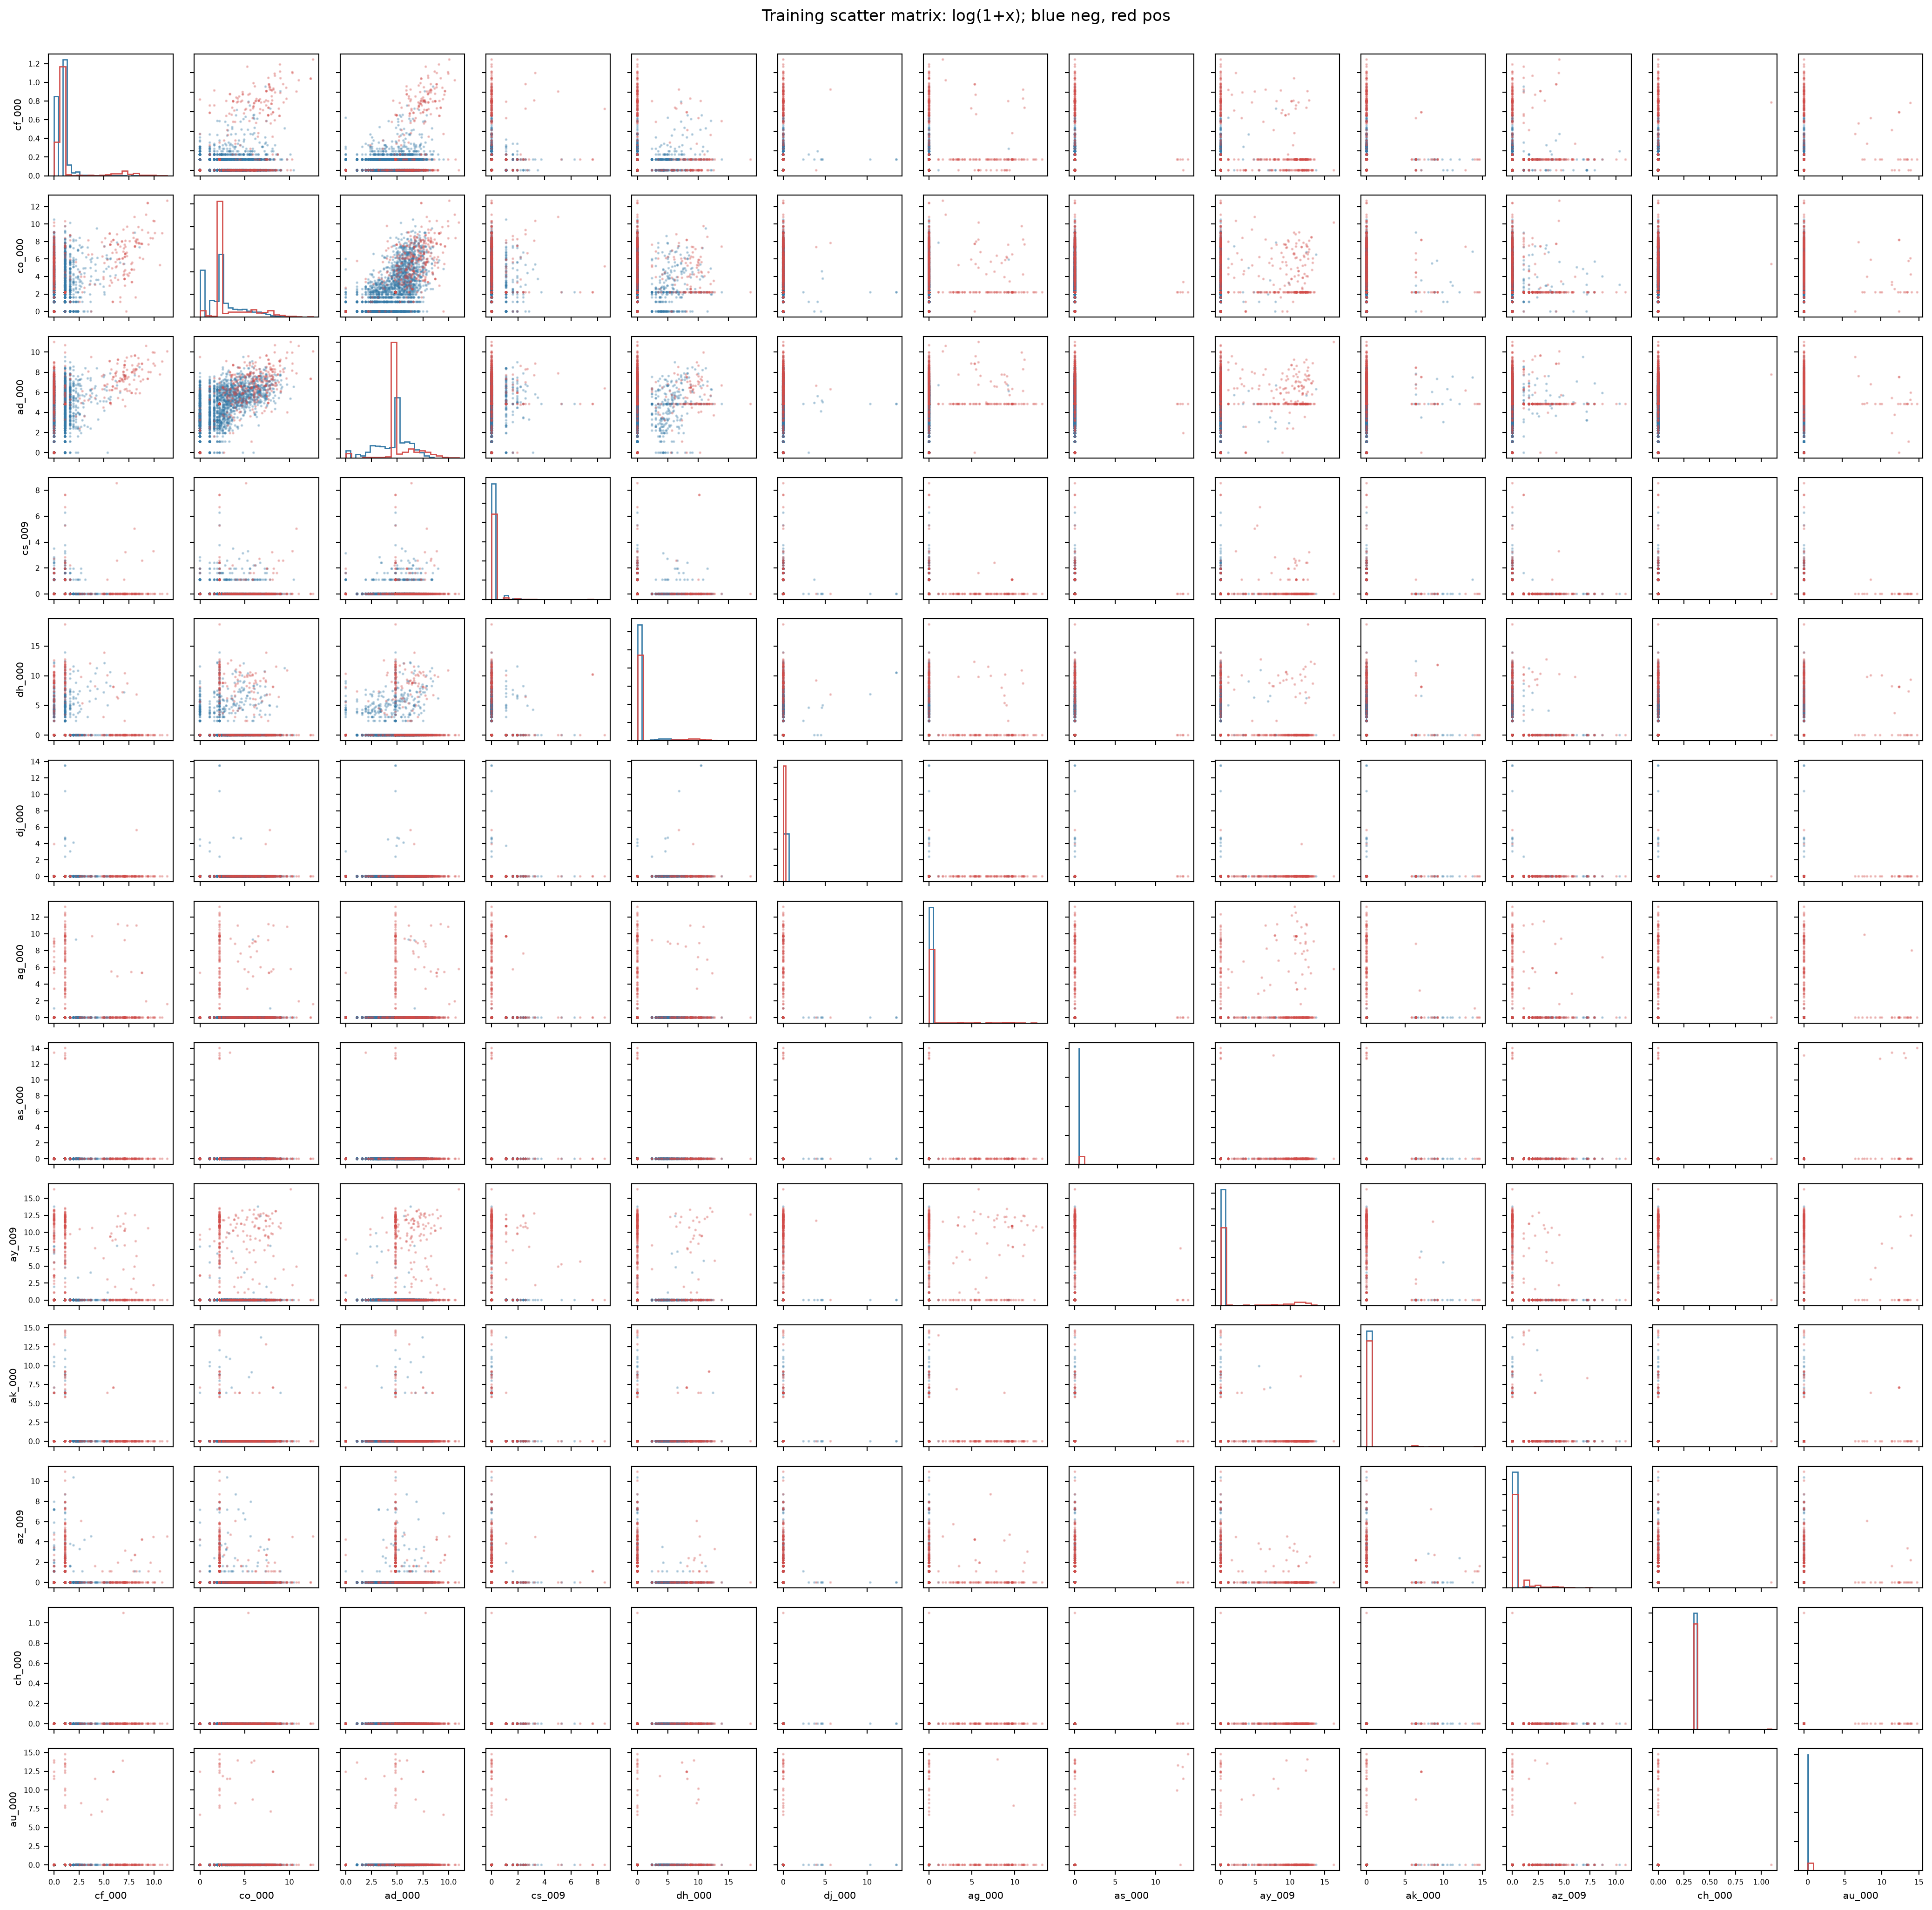

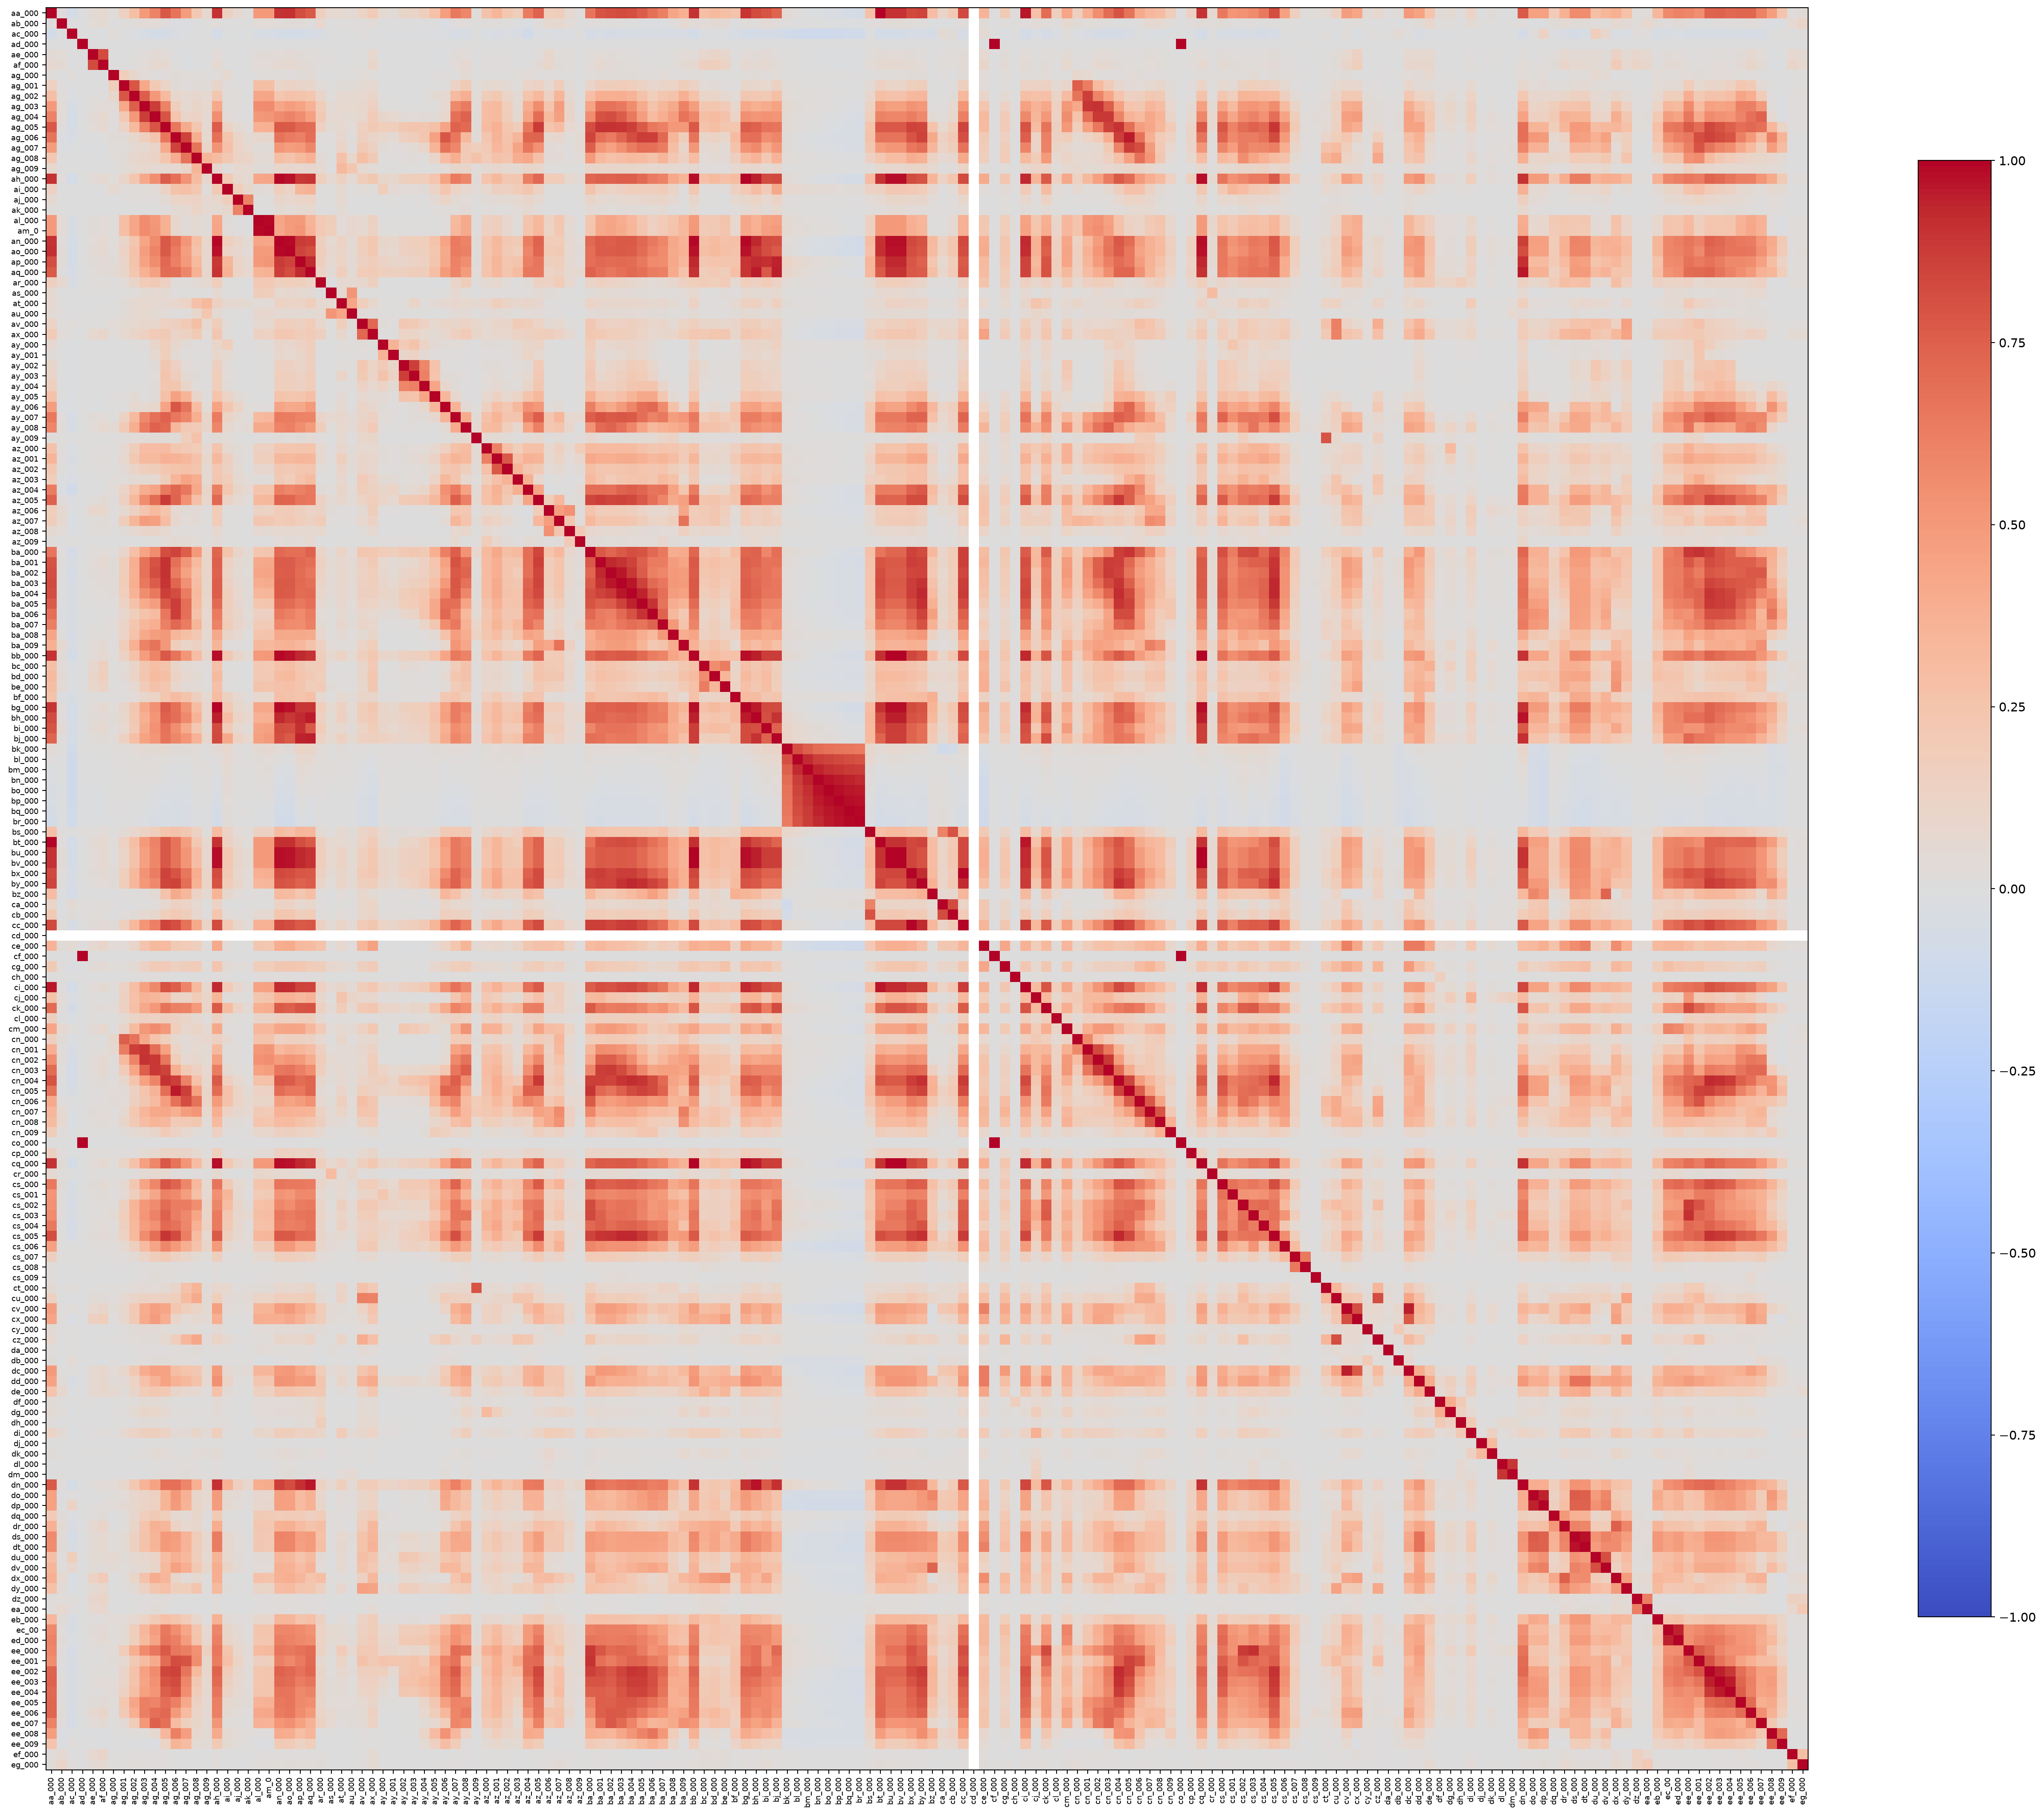

In [17]:
display(pd.read_csv(R / "feature_cv.csv").to_string(index=False))
display(pd.read_csv(R / "correlation.csv", index_col=0))
display(Image(filename=str(ROOT / "figures/scatter_all13.png"), width=1500))
display(Image(filename=str(ROOT / "figures/correlation_all_labels.png"), width=1500))

In [18]:
for name in ["xgb_plain", "xgb_smote"]:
    print(name, "all 35 fold evaluations")
    display(pd.read_csv(R / f"{name}_cv_folds.csv"))
for name in ["rf_plain", "rf_balanced", "xgb_plain", "xgb_smote"]:
    print(name, json.dumps(json.loads((R / f"{name}.json").read_text()), indent=2))

xgb_plain all 35 fold evaluations


,alpha,fold,n,error,auc,average_precision,precision,recall,f1,seconds,original_fold_n,resampled_fold_n
0,0.000,1,12000,0.006000,0.991012,0.890494,0.921053,0.700,0.795455,4.765477,48000,48000
1,0.000,2,12000,0.005083,0.991162,0.895974,0.897143,0.785,0.837333,4.152060,48000,48000
2,0.000,3,12000,0.005583,0.991226,0.903891,0.888889,0.760,0.819407,4.205971,48000,48000
3,0.000,4,12000,0.006333,0.987739,0.868021,0.878049,0.720,0.791209,4.457810,48000,48000
4,0.000,5,12000,0.005083,0.985658,0.879619,0.931677,0.750,0.831025,4.463802,48000,48000
5,0.001,1,12000,0.006000,0.990675,0.886430,0.926667,0.695,0.794286,4.001088,48000,48000
6,0.001,2,12000,0.005417,0.991623,0.895651,0.881356,0.780,0.827586,3.559075,48000,48000
7,0.001,3,12000,0.005833,0.989659,0.898145,0.886905,0.745,0.809783,3.712857,48000,48000
8,0.001,4,12000,0.006500,0.987976,0.868458,0.871951,0.715,0.785714,3.473955,48000,48000
9,0.001,5,12000,0.005083,0.985733,0.879697,0.931677,0.750,0.831025,3.905837,48000,48000


xgb_smote all 35 fold evaluations


,alpha,fold,n,error,auc,average_precision,precision,recall,f1,seconds,original_fold_n,resampled_fold_n
0,0.000,1,12000,0.008750,0.988235,0.852919,0.693878,0.850,0.764045,4.394605,48000,94400
1,0.000,2,12000,0.010083,0.986858,0.888324,0.642599,0.890,0.746331,3.783563,48000,94400
2,0.000,3,12000,0.009917,0.992474,0.857822,0.651685,0.870,0.745182,3.466367,48000,94400
3,0.000,4,12000,0.010000,0.991200,0.809784,0.662602,0.815,0.730942,3.888679,48000,94400
4,0.000,5,12000,0.010083,0.980995,0.828638,0.661224,0.810,0.728090,3.785448,48000,94400
5,0.001,1,12000,0.008750,0.988235,0.852921,0.693878,0.850,0.764045,4.363565,48000,94400
6,0.001,2,12000,0.010083,0.986858,0.888324,0.642599,0.890,0.746331,3.539647,48000,94400
7,0.001,3,12000,0.009833,0.992691,0.858410,0.655303,0.865,0.745690,4.396006,48000,94400
8,0.001,4,12000,0.010000,0.991200,0.809772,0.662602,0.815,0.730942,4.326032,48000,94400
9,0.001,5,12000,0.010083,0.980995,0.828638,0.661224,0.810,0.728090,3.759825,48000,94400


rf_plain {
  "train": {
    "n": 60000,
    "error": 0.0,
    "auc": 1.0,
    "average_precision": 1.0,
    "precision": 1.0,
    "recall": 1.0,
    "f1": 1.0,
    "confusion_matrix": [
      [
        59000,
        0
      ],
      [
        0,
        1000
      ]
    ]
  },
  "test": {
    "n": 16000,
    "error": 0.00775,
    "auc": 0.9943473493333334,
    "average_precision": 0.9260933913975355,
    "precision": 0.9312714776632303,
    "recall": 0.7226666666666667,
    "f1": 0.8138138138138138,
    "confusion_matrix": [
      [
        15605,
        20
      ],
      [
        104,
        271
      ]
    ]
  },
  "test_train_only_imputation": {
    "n": 16000,
    "error": 0.00775,
    "auc": 0.9943566506666668,
    "average_precision": 0.9261388699713318,
    "precision": 0.9312714776632303,
    "recall": 0.7226666666666667,
    "f1": 0.8138138138138138,
    "confusion_matrix": [
      [
        15605,
        20
      ],
      [
        104,
        271
      ]
    ]
  },
  "

## Executed mathematical checks for Questions 2-5

For Question 2 the nested feasible-set argument is analytical; the plotted shapes are explicitly schematic. The next cell verifies the ridge/lasso algebra on a centered identical-column example, the ten-tree calculation, and the geometric margin/support vectors.

In [19]:
# Centered example for Q3: x=(1,-1), y=(2,-2), lambda=2.
x = np.array([1., -1.]); yy = np.array([2., -2.]); lam = 2.
A0 = x @ x; C0 = x @ yy
ridge_beta = C0 / (2*A0 + lam)
tstar = np.sign(C0)*max(abs(C0)-lam/2, 0)/A0
splits = np.linspace(0,1,11)
lasso_objectives = [np.sum((yy-x*tstar)**2)+lam*(abs(a*tstar)+abs((1-a)*tstar)) for a in splits]
assert np.ptp(lasso_objectives)<1e-12
print("Q3 ridge coefficients:", (ridge_beta,ridge_beta), "lasso optimal sum:", tstar)
print("Q3 identical lasso objective across all 11 splits:", lasso_objectives[0])
probs = np.array([.1,.15,.2,.2,.55,.6,.6,.65,.7,.75])
assert (probs>.5).sum()==6 and np.isclose(probs.mean(), .45)
print("Q4 Red votes:", (probs>.5).sum(), "; average Red probability:", probs.mean())
print("Q5 independent SVM verification:", (R / "q5_verification.json").read_text())

Q3 ridge coefficients: (np.float64(0.6666666666666666), np.float64(0.6666666666666666)) lasso optimal sum: 1.5
Q3 identical lasso objective across all 11 splits: 3.5
Q4 Red votes: 6 ; average Red probability: 0.45
Q5 independent SVM verification: {
  "coef": [
    [
      -1.9999999999301519,
      1.999999999930151
    ]
  ],
  "intercept": [
    0.9999999999650773
  ],
  "support_observations_1based": [
    5,
    6,
    2,
    3
  ],
  "margin": 0.35355339060562135
}


## Final independent checks

Recompute all saved metrics, reload serialized estimators to reproduce official-test probabilities, and check fold membership, CV selection, feature CVs, shapes and correlation symmetry.

In [20]:
from verify import verify
validation = verify()
assert validation["all_passed"]
print("All necessary saved-result checks passed.")

{
  "checks": [
    "rf_plain: saved probabilities independently recomputed from serialized estimator; all metrics agree",
    "rf_balanced: saved probabilities independently recomputed from serialized estimator; all metrics agree",
    "xgb_plain: saved probabilities independently recomputed from serialized estimator; all metrics agree",
    "xgb_smote: saved probabilities independently recomputed from serialized estimator; all metrics agree",
    "Official splits and feature order preserved; labels excluded",
    "5 disjoint stratified validation folds cover every training row exactly once",
    "Two complete 7 x 5 alpha searches; AP-selected alpha agrees with saved summaries",
    "170 CVs recomputed with ddof=1; top 13 ranking and full correlation matrix verified",
    "CV Pipeline fits on tr only; transforms va only; SMOTE is inside fit",
    "Threshold is positive probability >= 0.5; AP is average_precision_score",
    "Training scores refer to the original 60,000 observations"
 

## Question 6 — Extra Practice

All four exercises are completed below. Each source was checked separately against both local R editions. The exact assignment reference 6.8.4 identifies the first edition; its second-edition equivalent is 6.6.4. The other three references agree across editions (with a changed tree-figure number). The original Q1–5 computations and outputs are retained; the following cells do not retrain any APS model. The additional cells were executed in a fresh kernel. For an end-to-end run, these cells are also self-contained after the earlier sections.

In [1]:
from pathlib import Path
__file__ = str(Path.cwd() / "scripts" / "extra_practice.py")
"""Question 6: verified ISLR exercises, executed computations, figures and shared answers.
No APS fitting or existing checkpoint writes occur in this module.
"""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle,Circle
ROOT=Path(__file__).resolve().parents[1]
R=ROOT/'results';F=ROOT/'figures';SEED=552

def savefig(fig,name):
 fig.savefig(F/f'{name}.png',dpi=210,bbox_inches='tight');fig.savefig(F/f'{name}.pdf',bbox_inches='tight');plt.close(fig)

def predict_a(x):
 x=np.asarray(x);a,b=x[...,0],x[...,1]
 return np.where(a>=1,5,np.where(b>=1,15,np.where(a<0,3,np.where(b<0,10,0))))

def predict_b(x):
 x=np.asarray(x);a,b=x[...,0],x[...,1]
 return np.where(b<1,np.where(a<1,-1.8,.63),np.where(b<2,np.where(a<0,-1.06,.21),2.49))

def tree(ax,nodes,edges,title):
 ax.set(xlim=(-.04,1.04),ylim=(-.06,1.08));ax.axis('off');ax.set_title(title,fontsize=13)
 for parent,child,answer in edges:
  xp,yp,label=nodes[parent];xc,yc,_=nodes[child]
  ax.plot([xp,xc],[yp-.035,yc+.035],color='#5b6b7a',lw=1.1,zorder=0)
  ax.text((xp+xc)/2+(.02 if xc>xp else -.02),(yp+yc)/2,answer,fontsize=9,ha='center',va='center',bbox={'facecolor':'white','edgecolor':'none','pad':1})
 for key,(x,y,label) in nodes.items():
  ax.text(x,y,label,ha='center',va='center',fontsize=12,bbox={'boxstyle':'round,pad=.2','facecolor':'#e7f0f6' if key.startswith('n') else '#fff3dc','edgecolor':'#718394','linewidth':.8})

def partition(ax,which):
 ax.set(xlim=(-1,3),ylim=(-1,3),xlabel='$X_1$',ylabel='$X_2$',xticks=[-1,0,1,2,3],yticks=[-1,0,1,2,3]);ax.set_aspect('equal');ax.tick_params(labelsize=10)
 if which=='a':
  regions=[(-1,-1,1,2,3),(0,-1,1,1,10),(0,0,1,1,0),(-1,1,2,2,15),(1,-1,2,4,5)]
  lines=[([1,1],[-1,3]),([-1,1],[1,1]),([0,0],[-1,1]),([0,1],[0,0])]
  ax.set_title('(a) Source partition (redrawn)',fontsize=13)
 else:
  regions=[(-1,-1,2,2,-1.8),(1,-1,2,2,.63),(-1,1,1,1,-1.06),(0,1,3,1,.21),(-1,2,4,1,2.49)]
  lines=[([-1,3],[1,1]),([1,1],[-1,1]),([-1,3],[2,2]),([0,0],[1,2])]
  ax.set_title('(b) Partition implied by source tree',fontsize=13)
 colors=['#dbe9f3','#f8e4be','#e4eddc','#e8def2','#f5dddd']
 for (x,y,w,h,v),c in zip(regions,colors):
  ax.add_patch(Rectangle((x,y),w,h,facecolor=c,edgecolor='none'));ax.text(x+w/2,y+h/2,f'{v:g}',ha='center',va='center',fontsize=14)
 for xx,yy in lines:ax.plot(xx,yy,color='#314c62',lw=1.5)


def run_extra():
 R.mkdir(exist_ok=True);F.mkdir(exist_ok=True)
 plt.rcParams.update({'font.size':11,'axes.labelsize':12,'axes.titlesize':13})
 # Bootstrap: enumerate every requested n, and actually generate all 10,000 samples.
 n=np.arange(1,100001);p=np.empty(len(n),float);p[0]=1.;p[1:]=-np.expm1(n[1:]*np.log1p(-1/n[1:]))
 pd.DataFrame({'n':n,'probability_included':p}).to_csv(R/'extra_bootstrap_curve.csv',index=False)
 rng=np.random.default_rng(SEED);samples=rng.integers(1,101,size=(10000,100));contains=np.any(samples==4,axis=1);exact=float(p[99]);estimate=float(contains.mean());se=float(np.sqrt(exact*(1-exact)/len(contains)))
 bootstrap={'seed':SEED,'replicates':10000,'sample_size':100,'observation_j':4,'inclusion_count':int(contains.sum()),'empirical_probability':estimate,'exact_probability':exact,'monte_carlo_standard_error':se,'standardized_difference':(estimate-exact)/se,'exact_requested':{str(i):float(p[i-1]) for i in [5,100,10000]},'limit':float(1-np.exp(-1))}
 assert np.all(np.diff(p)<0) and abs(estimate-exact)<4*se
 fig,axes=plt.subplots(1,2,figsize=(9.6,2.9))
 for ax in axes:
  ax.plot(n,p,lw=1.8,label='$1-(1-1/n)^n$');ax.axhline(bootstrap['limit'],ls='--',color='#a14c4c',label='$1-e^{-1}$');ax.set(xlabel='Sample size n',ylabel='Inclusion probability');ax.grid(alpha=.15)
 axes[0].set(xlim=(1,100),title='Initial decrease (n = 1,...,100)');axes[1].set_xscale('log');axes[1].set(xlim=(1,100000),title='Every integer n through 100,000');axes[1].legend(fontsize=10);fig.tight_layout();savefig(fig,'extra_bootstrap')
 # Ridge illustration: one actual orthogonal-design fit; analytic risk is not a test estimate.
 d=np.array([4.,2.,1.]);X=np.diag(d);beta=np.array([2.,-1.,.7]);sigma2=1.;rng=np.random.default_rng(SEED);y=X@beta+rng.normal(size=3)
 lambdas=np.r_[0,np.logspace(-4,4,300)];coef=np.array([np.linalg.solve(X.T@X+lam*np.eye(3),X.T@y) for lam in lambdas]);rss=((y[None,:]-coef@X.T)**2).sum(axis=1)
 shrink=d[None,:]**2/(d[None,:]**2+lambdas[:,None]);bias2=(((shrink-1)*beta)**2).sum(axis=1);variance=(sigma2*d[None,:]**2/(d[None,:]**2+lambdas[:,None])**2).sum(axis=1);risk=bias2+variance+sigma2
 assert np.all(np.diff(rss)>=-1e-10) and np.all(np.diff(variance)<=1e-10) and np.all(np.diff(bias2)>=-1e-10)
 pd.DataFrame({'lambda':lambdas,'observed_training_rss':rss,'squared_bias_isotropic_test':bias2,'prediction_variance':variance,'irreducible_error':sigma2,'expected_test_mse':risk}).to_csv(R/'extra_ridge_curve.csv',index=False)
 fig,axes=plt.subplots(1,2,figsize=(9.6,2.9))
 line1,=axes[0].plot(lambdas,rss,color='#2867b1',label='Training RSS (left)');riskax=axes[0].twinx();line2,=riskax.plot(lambdas,risk,color='#dd7931',label='Expected MSE (right)');riskax.set_ylabel('Expected test MSE',color='#dd7931',fontsize=10);axes[0].set(title='Computed orthogonal-design illustration',ylabel='Training RSS');axes[0].legend(handles=[line1,line2],fontsize=8,loc='upper left')
 for val,label in [(bias2,'Squared bias'),(variance,'Variance'),(np.ones(len(lambdas)),'Irreducible error')]:axes[1].plot(lambdas,val,label=label)
 axes[1].set(title='Analytic prediction-error components');axes[1].legend(fontsize=9)
 for ax in axes:ax.set_xscale('symlog',linthresh=.01);ax.set_xlabel('Ridge penalty lambda');ax.grid(alpha=.15)
 fig.tight_layout();savefig(fig,'extra_ridge')
 # Exact reconstruction of first-edition Figure 8.12, checked against second-edition 8.14.
 nodes_a={'n0':(.64,.97,'$X_1<1$'),'n1':(.39,.73,'$X_2<1$'),'l5':(.92,.73,'5'),'n2':(.20,.49,'$X_1<0$'),'l15':(.62,.49,'15'),'l3':(.04,.25,'3'),'n3':(.39,.25,'$X_2<0$'),'l10':(.29,.01,'10'),'l0':(.56,.01,'0')}
 edges_a=[('n0','n1','yes'),('n0','l5','no'),('n1','n2','yes'),('n1','l15','no'),('n2','l3','yes'),('n2','n3','no'),('n3','l10','yes'),('n3','l0','no')]
 nodes_b={'n0':(.48,.97,'$X_2<1$'),'n1':(.20,.65,'$X_1<1$'),'l1':(.04,.32,'-1.80'),'l2':(.34,.32,'0.63'),'n2':(.74,.65,'$X_2<2$'),'n3':(.60,.32,'$X_1<0$'),'l5':(.95,.32,'2.49'),'l3':(.49,.01,'-1.06'),'l4':(.75,.01,'0.21')}
 edges_b=[('n0','n1','yes'),('n0','n2','no'),('n1','l1','yes'),('n1','l2','no'),('n2','n3','yes'),('n2','l5','no'),('n3','l3','yes'),('n3','l4','no')]
 fig,axes=plt.subplots(1,2,figsize=(10,3.35));partition(axes[0],'a');tree(axes[1],nodes_a,edges_a,'(a) One valid corresponding tree');fig.tight_layout();savefig(fig,'extra_tree_a')
 fig,axes=plt.subplots(1,2,figsize=(10,3.35));tree(axes[0],nodes_b,edges_b,'(b) Source tree (redrawn)');partition(axes[1],'b');fig.tight_layout();savefig(fig,'extra_tree_b')
 points_a=np.array([[-.5,0],[.5,-.5],[.5,.5],[0,2],[2,0]]);targets_a=np.array([3,10,0,15,5]);points_b=np.array([[0,0],[2,0],[-.5,1.5],[.5,1.5],[0,2.5]]);targets_b=np.array([-1.8,.63,-1.06,.21,2.49])
 assert np.array_equal(predict_a(points_a),targets_a);assert np.allclose(predict_b(points_b),targets_b)
 # Independently traverse diagram edges and compare all piecewise values on a grid, including cuts.
 def traverse(point,nodes,edges):
  key='n0';mapping={(a,b):c for a,c,b in edges}
  while key.startswith('n'):
   label=nodes[key][2].replace('$','');lhs,rhs=label.split('<');dim=int(lhs.split('_')[1])-1;answer='yes' if point[dim]<float(rhs) else 'no';key=mapping[key,answer]
  return float(nodes[key][2])
 grid1=np.unique(np.r_[np.linspace(-1,3,81),0,1,2]);grid=np.array(np.meshgrid(grid1,grid1)).reshape(2,-1).T
 assert np.allclose([traverse(q,nodes_a,edges_a) for q in grid],predict_a(grid));assert np.allclose([traverse(q,nodes_b,edges_b) for q in grid],predict_b(grid))
 # Circular classification boundary, original four requested points and exact polynomial lift.
 points=np.array([[0,0],[-1,1],[2,2],[3,8]]);radius2=((points-np.array([-1,2]))**2).sum(axis=1);scores=radius2-4;classes=np.where(scores>0,'Blue','Red');expanded=points[:,0]**2+points[:,1]**2+2*points[:,0]-4*points[:,1]+1
 assert np.array_equal(scores,expanded);assert classes.tolist()==['Blue','Red','Blue','Blue']
 fig,axes=plt.subplots(1,2,figsize=(9.6,3.7))
 for ax in axes:
  ax.set_facecolor('#e5eefb');ax.add_patch(Circle((-1,2),2,facecolor='#f6d9db',edgecolor='#34495e',lw=1.5));ax.scatter([-1],[2],marker='+',color='black');ax.set_aspect('equal');ax.set(xlabel='$X_1$',ylabel='$X_2$');ax.grid(alpha=.12)
 axes[0].set(xlim=(-3.8,1.8),ylim=(-.8,4.8),title='(a)-(b) Boundary and signed regions');axes[0].text(-1,2.7,'Red: squared distance <= 4',ha='center',fontsize=9);axes[0].text(-1,4.35,'Blue: squared distance > 4',ha='center',fontsize=9);axes[0].annotate('center (-1,2)',xy=(-1,2),xytext=(-2.9,.7),fontsize=9,arrowprops={'arrowstyle':'->'});axes[0].plot([-1,1],[2,2],color='#34495e');axes[0].text(0,1.7,'radius 2',ha='center',fontsize=9)
 axes[1].set(xlim=(-3.8,4.4),ylim=(-1,9),title='(c) Classification of the four given points')
 for point,c in zip(points,classes):
  axes[1].scatter(*point,color='#c84a52' if c=='Red' else '#2867b1',s=35,zorder=4);axes[1].annotate(f'({int(point[0])},{int(point[1])})',point,xytext=(5,6),textcoords='offset points',fontsize=10)
 fig.tight_layout();savefig(fig,'extra_circle')
 pd.DataFrame({'X1':points[:,0],'X2':points[:,1],'squared_distance':radius2,'expanded_score':scores,'class':classes}).to_csv(R/'extra_circle_points.csv',index=False)
 result={'bootstrap':bootstrap,'ridge':{'design':'X = diag(4,2,1), beta = (2,-1,0.7), Gaussian noise variance = 1, known zero intercept, isotropic test covariates','seed':SEED,'response':y.tolist(),'training_rss_nondecreasing':True,'variance_nonincreasing':True,'squared_bias_nondecreasing':True},'tree':{'grid_points_checked':len(grid),'tree_and_partition_agree':True,'cut_convention':'less-than true branch; equality goes to false branch'},'circle':{'center':[-1,2],'radius':2,'requested_classes':classes.tolist(),'polynomial_coefficients_intercept_X1_X1sq_X2_X2sq':[1,2,1,-4,1]},'all_passed':True}
 (R/'extra_practice_results.json').write_text(json.dumps(result,indent=2));print(json.dumps(result,indent=2));return result


def extra_pages():
 # Tuple schema is shared with the existing report/notebook generators.
 def p(t):return ('p',t)
 def h(t):return ('h',t)
 def eq(t):return ('math',t)
 def im(n,w=510):return ('image',n,w)
 def table(a,b):return ('table',a,b)
 d=json.loads((R/'extra_practice_results.json').read_text());b=d['bootstrap']
 return [
 ('Question 6 - Extra Practice: ISLR 5.4.2',[
 p('Source verified separately: first edition, seventh printing, Section 5.4 Exercise 2, printed pp.197-198 (PDF pp.212-213). The second-edition 5.4.2, pp.219-220, has the same eight subparts. The task concerns inclusion of one fixed original observation j in n independent draws with replacement.'),
 p('<b>(a)</b> The first draw misses observation j with probability (n-1)/n = 1 - 1/n: exactly n-1 of the n equally likely indices differ from j. <b>(b)</b> The second draw has the same probability, 1 - 1/n; replacement restores the same sampling population.'),
 p('<b>(c)</b> All n draws are independent, so the probability that j is absent is the product of n identical miss probabilities. Taking the complement gives its inclusion probability:'),
 eq(r'P(j\notin B)=(1-1/n)^n,\qquad P(j\in B)=1-(1-1/n)^n'),
 table(['Subpart','n','Exact inclusion probability'],[[part,str(n),f'{b["exact_requested"][str(n)]:.10f}'] for part,n in [('(d)',5),('(e)',100),('(f)',10000)]]),
 p('<b>(g)</b> The code evaluates every integer n from 1 through 100,000 (the right panel uses a logarithmic x-axis). Inclusion decreases from 1 toward 1 - exp(-1) = 0.6321205588, approaching from above. Equivalently, about 36.8% of original observations are absent from a large bootstrap sample. The sample still has n draws; repeated indices explain the difference.'),im('extra_bootstrap',510),
 p(f'<b>(h)</b> With seed {b["seed"]}, we actually generated {b["replicates"]:,} bootstrap samples of size 100, and checked whether index j = 4 occurs. It appeared in {b["inclusion_count"]:,} samples: empirical probability {b["empirical_probability"]:.4f}, versus exact {b["exact_probability"]:.6f}. The Monte Carlo standard error is sqrt(p(1-p)/10000) = {b["monte_carlo_standard_error"]:.5f}; the difference is {b["standardized_difference"]:.2f} standard errors. This is consistent with simulation noise. Sampling uses NumPy\'s generator, so the seeded realization need not equal R\'s.')]),
 ('Question 6 - Extra Practice: ISLR 6.8.4',[
 p('Source: first edition, seventh printing, Section 6.8 Exercise 4, printed pp.260-261 (PDF pp.275-276). This is the ridge-penalty question. The equivalent second-edition exercise is 6.6.4, not 6.8.4. An unpenalized intercept is understood; lambda increases from zero.'),
 eq(r'\min_{\beta_0,\beta}\ R(\beta)+\lambda P(\beta),\quad R=\sum_i(y_i-\beta_0-x_i^T\beta)^2,\quad P=\sum_j\beta_j^2'),
 p('<b>(a) Training RSS: iii, steadily increases (nondecreasing).</b> Let R1,P1 and R2,P2 be the residual and penalty values at minimizers for 0 <= lambda1 < lambda2. Optimality gives R1 + lambda1 P1 <= R2 + lambda1 P2 and R2 + lambda2 P2 <= R1 + lambda2 P1. Adding implies P2 <= P1; substituting yields R2 - R1 >= lambda1(P1 - P2) >= 0. Equality is possible, for example when all fitted slopes are zero.'),
 p('<b>(b) Test RSS: ii, typically decreases initially and then increases.</b> Moderate shrinkage can reduce variance enough to improve prediction; excessive shrinkage causes underfitting. A U shape is the intended bias-variance pattern, not a theorem for every test set or underlying signal.'),
 p('<b>(c) Variance: iv, decreases.</b> For centered X = U D V-transpose with fixed design and homoskedastic noise, a ridge coefficient along right singular direction k has variance sigma squared times d_k squared / (d_k squared + lambda) squared. Each such component is nonincreasing; the unpenalized intercept contributes a constant term.'),
 eq(r'\operatorname{Var}(\hat\beta_{\lambda,k})=\frac{\sigma^2 d_k^2}{(d_k^2+\lambda)^2},\qquad \operatorname{Bias}_k=-\frac{\lambda}{d_k^2+\lambda}\beta_k'),
 p('<b>(d) Squared bias: iii, typically increases.</b> Larger lambda shrinks identifiable slope directions farther toward zero, increasing shrinkage bias. In the orthogonal coefficient norm (or isotropic test average), squared directional biases increase. Arbitrary pointwise squared prediction bias need not be monotone because directional contributions can cancel.'),
 p('<b>(e) Irreducible error: v, remains constant.</b> Changing regularization cannot change the response noise variance.'),im('extra_ridge',510),
 p('Computed illustration: X = diag(4,2,1), true slopes (2,-1,0.7), known zero intercept, unit Gaussian noise, seed 552. Training RSS comes from the realized response; expected test MSE is the analytic sum of squared bias, variance and noise for isotropic test covariates. These are not APS results or held-out empirical estimates. Monotonicity checks passed.')]),
 ('Question 6 - Extra Practice: ISLR 8.4.4',[
 p('Source: first edition, seventh printing, Section 8.4 Exercise 4, printed pp.332-333 (PDF pp.347-348), Figure 8.12. Checked independently against second-edition 8.4.4, pp.361-362, Figure 8.14: both partitions and all leaf values agree. The task asks (a) for a tree from the left partition and (b) for a partition from the right tree.'),
 p('<b>(a)</b> A valid first split is X1 < 1 (false leaf: 5). On the true branch split X2 < 1 (false leaf: 15). In the lower-left part split X1 < 0 (true leaf: 3). On its false branch split X2 < 0, yielding 10 if true and 0 otherwise. The picture is a redrawing of the source regions and our corresponding tree; the finite plotting window does not bound the actual outer regions.'),im('extra_tree_a',510),
 p('<b>(b)</b> The source tree first splits horizontally at X2 = 1, splits the lower half vertically at X1 = 1, then splits the upper half horizontally at X2 = 2 and the middle strip vertically at X1 = 0. The resulting five regions and their means are:'),im('extra_tree_b',510),
 table(['Region conditions','Mean Y'],[['X2 < 1 and X1 < 1','-1.80'],['X2 < 1 and X1 >= 1','0.63'],['1 <= X2 < 2 and X1 < 0','-1.06'],['1 <= X2 < 2 and X1 >= 0','0.21'],['X2 >= 2','2.49']]),
 p(f'Boundary convention: a less-than condition sends equality to the false branch. Independent tree traversal and piecewise region evaluation agree on {d["tree"]["grid_points_checked"]:,} grid points, including the cut lines. Each diagram has five leaves/regions.')]),
 ('Question 6 - Extra Practice: ISLR 9.7.2',[
 p('Source: first edition, seventh printing, Section 9.7 Exercise 2, printed p.368 (PDF p.383). The second-edition 9.7.2, p.398, has the same four subparts, curve, inequalities and query points.'),
 p('<b>(a)</b> The curve (1 + X1) squared + (2 - X2) squared = 4 is a circle centered at (-1,2) with radius 2. Its horizontal extremes are (-3,2) and (1,2), and its vertical extremes are (-1,0) and (-1,4).'),
 p('<b>(b)</b> The strict inequality > 4 denotes the exterior; <= 4 denotes the closed disk, including the boundary. The figure shades the exterior Blue and the closed disk Red, matching the rule in (c).'),im('extra_circle',510),
 h('(c) Classify all four specified observations'),
 table(['Point (X1,X2)','Squared distance from (-1,2)','Class'],[[f'({a},{b})',str((a+1)**2+(2-b)**2),'Blue' if (a+1)**2+(2-b)**2>4 else 'Red'] for a,b in [(0,0),(-1,1),(2,2),(3,8)]]),
 h('(d) A linear boundary in the expanded feature space'),
 eq(r'(1+X_1)^2+(2-X_2)^2-4=X_1^2+X_2^2+2X_1-4X_2+1'),
 p('Let z = (X1, X1 squared, X2, X2 squared). The same boundary is 1 + 2 z1 + z2 - 4 z3 + z4 = 0, an affine hyperplane with intercept 1 and coefficients (2,1,-4,1). Predict Blue if this score is positive and Red otherwise. Thus the boundary is nonlinear in the original two inputs but linear in these four transformed coordinates. The computed expanded scores (1,-3,5,48) agree exactly with squared distance minus 4.')])]



In [2]:
extra_results = run_extra()
assert extra_results["all_passed"]

{
  "bootstrap": {
    "seed": 552,
    "replicates": 10000,
    "sample_size": 100,
    "observation_j": 4,
    "inclusion_count": 6238,
    "empirical_probability": 0.6238,
    "exact_probability": 0.6339676587267705,
    "monte_carlo_standard_error": 0.0048171845139590354,
    "standardized_difference": -2.1107056823974846,
    "exact_requested": {
      "5": 0.67232,
      "100": 0.6339676587267705,
      "10000": 0.6321389535670702
    },
    "limit": 0.6321205588285577
  },
  "ridge": {
    "design": "X = diag(4,2,1), beta = (2,-1,0.7), Gaussian noise variance = 1, known zero intercept, isotropic test covariates",
    "seed": 552,
    "response": [
      9.695131952201761,
      -2.0092186909731895,
      0.8647655450579655
    ],
    "training_rss_nondecreasing": true,
    "variance_nonincreasing": true,
    "squared_bias_nondecreasing": true
  },
  "tree": {
    "grid_points_checked": 6561,
    "tree_and_partition_agree": true,
    "cut_convention": "less-than true branch; equa

### ISLR 5.4.2

Source verified separately: first edition, seventh printing, Section 5.4 Exercise 2, printed pp.197-198 (PDF pp.212-213). The second-edition 5.4.2, pp.219-220, has the same eight subparts. The task concerns inclusion of one fixed original observation j in n independent draws with replacement.

**(a)** The first draw misses observation j with probability (n-1)/n = 1 - 1/n: exactly n-1 of the n equally likely indices differ from j. **(b)** The second draw has the same probability, 1 - 1/n; replacement restores the same sampling population.

**(c)** All n draws are independent, so the probability that j is absent is the product of n identical miss probabilities. Taking the complement gives its inclusion probability:

$$
P(j\notin B)=(1-1/n)^n,\qquad P(j\in B)=1-(1-1/n)^n
$$

| Subpart | n | Exact inclusion probability |
| --- | --- | --- |
| (d) | 5 | 0.6723200000 |
| (e) | 100 | 0.6339676587 |
| (f) | 10000 | 0.6321389536 |

**(g)** The code evaluates every integer n from 1 through 100,000 (the right panel uses a logarithmic x-axis). Inclusion decreases from 1 toward 1 - exp(-1) = 0.6321205588, approaching from above. Equivalently, about 36.8% of original observations are absent from a large bootstrap sample. The sample still has n draws; repeated indices explain the difference.

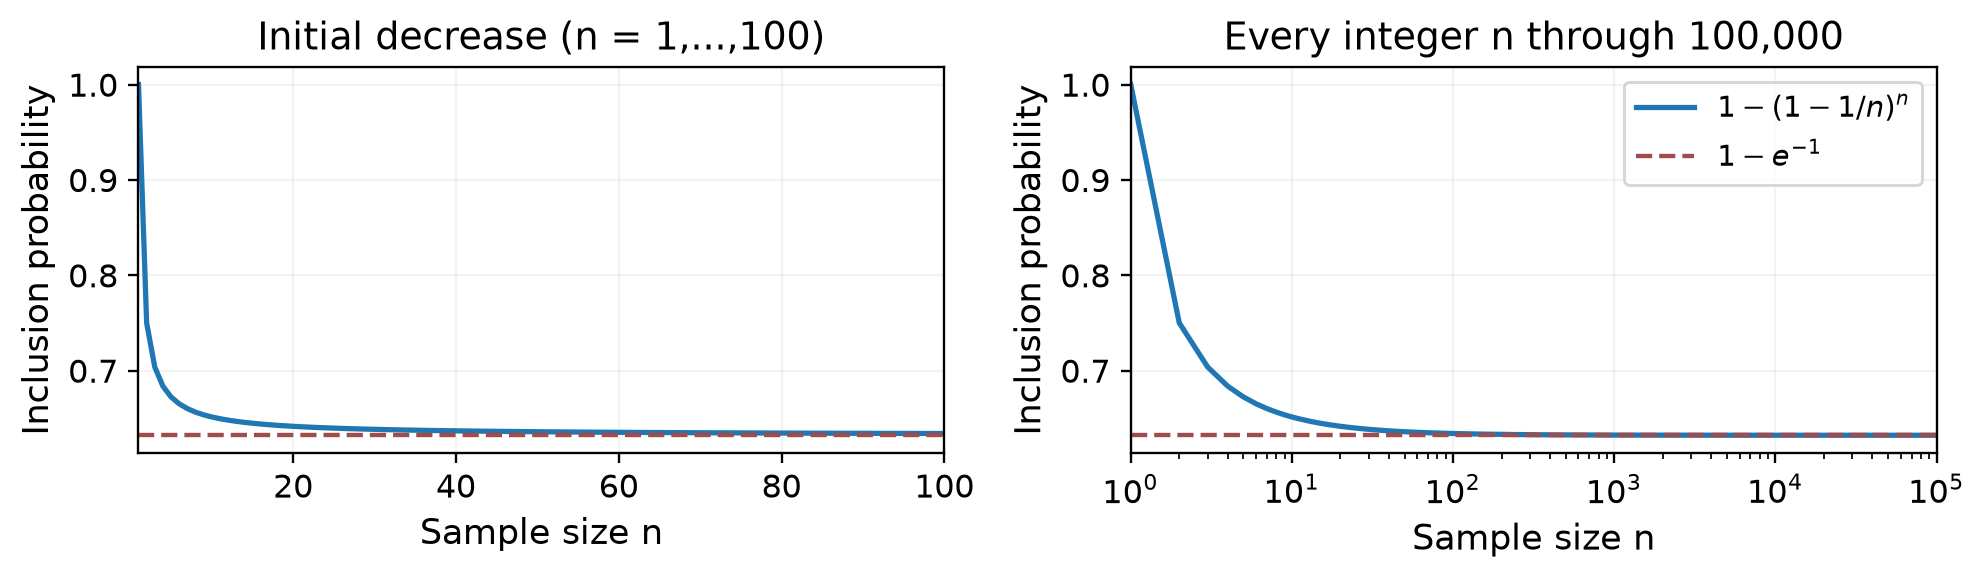

In [3]:
from IPython.display import display, Image
display(Image(filename=str(F / "extra_bootstrap.png"), width=1000))

**(h)** With seed 552, we actually generated 10,000 bootstrap samples of size 100, and checked whether index j = 4 occurs. It appeared in 6,238 samples: empirical probability 0.6238, versus exact 0.633968. The Monte Carlo standard error is sqrt(p(1-p)/10000) = 0.00482; the difference is -2.11 standard errors. This is consistent with simulation noise. Sampling uses NumPy's generator, so the seeded realization need not equal R's.

### ISLR 6.8.4

Source: first edition, seventh printing, Section 6.8 Exercise 4, printed pp.260-261 (PDF pp.275-276). This is the ridge-penalty question. The equivalent second-edition exercise is 6.6.4, not 6.8.4. An unpenalized intercept is understood; lambda increases from zero.

$$
\min_{\beta_0,\beta}\ R(\beta)+\lambda P(\beta),\quad R=\sum_i(y_i-\beta_0-x_i^T\beta)^2,\quad P=\sum_j\beta_j^2
$$

**(a) Training RSS: iii, steadily increases (nondecreasing).** Let R1,P1 and R2,P2 be the residual and penalty values at minimizers for 0 <= lambda1 < lambda2. Optimality gives R1 + lambda1 P1 <= R2 + lambda1 P2 and R2 + lambda2 P2 <= R1 + lambda2 P1. Adding implies P2 <= P1; substituting yields R2 - R1 >= lambda1(P1 - P2) >= 0. Equality is possible, for example when all fitted slopes are zero.

**(b) Test RSS: ii, typically decreases initially and then increases.** Moderate shrinkage can reduce variance enough to improve prediction; excessive shrinkage causes underfitting. A U shape is the intended bias-variance pattern, not a theorem for every test set or underlying signal.

**(c) Variance: iv, decreases.** For centered X = U D V-transpose with fixed design and homoskedastic noise, a ridge coefficient along right singular direction k has variance sigma squared times d_k squared / (d_k squared + lambda) squared. Each such component is nonincreasing; the unpenalized intercept contributes a constant term.

$$
\operatorname{Var}(\hat\beta_{\lambda,k})=\frac{\sigma^2 d_k^2}{(d_k^2+\lambda)^2},\qquad \operatorname{Bias}_k=-\frac{\lambda}{d_k^2+\lambda}\beta_k
$$

**(d) Squared bias: iii, typically increases.** Larger lambda shrinks identifiable slope directions farther toward zero, increasing shrinkage bias. In the orthogonal coefficient norm (or isotropic test average), squared directional biases increase. Arbitrary pointwise squared prediction bias need not be monotone because directional contributions can cancel.

**(e) Irreducible error: v, remains constant.** Changing regularization cannot change the response noise variance.

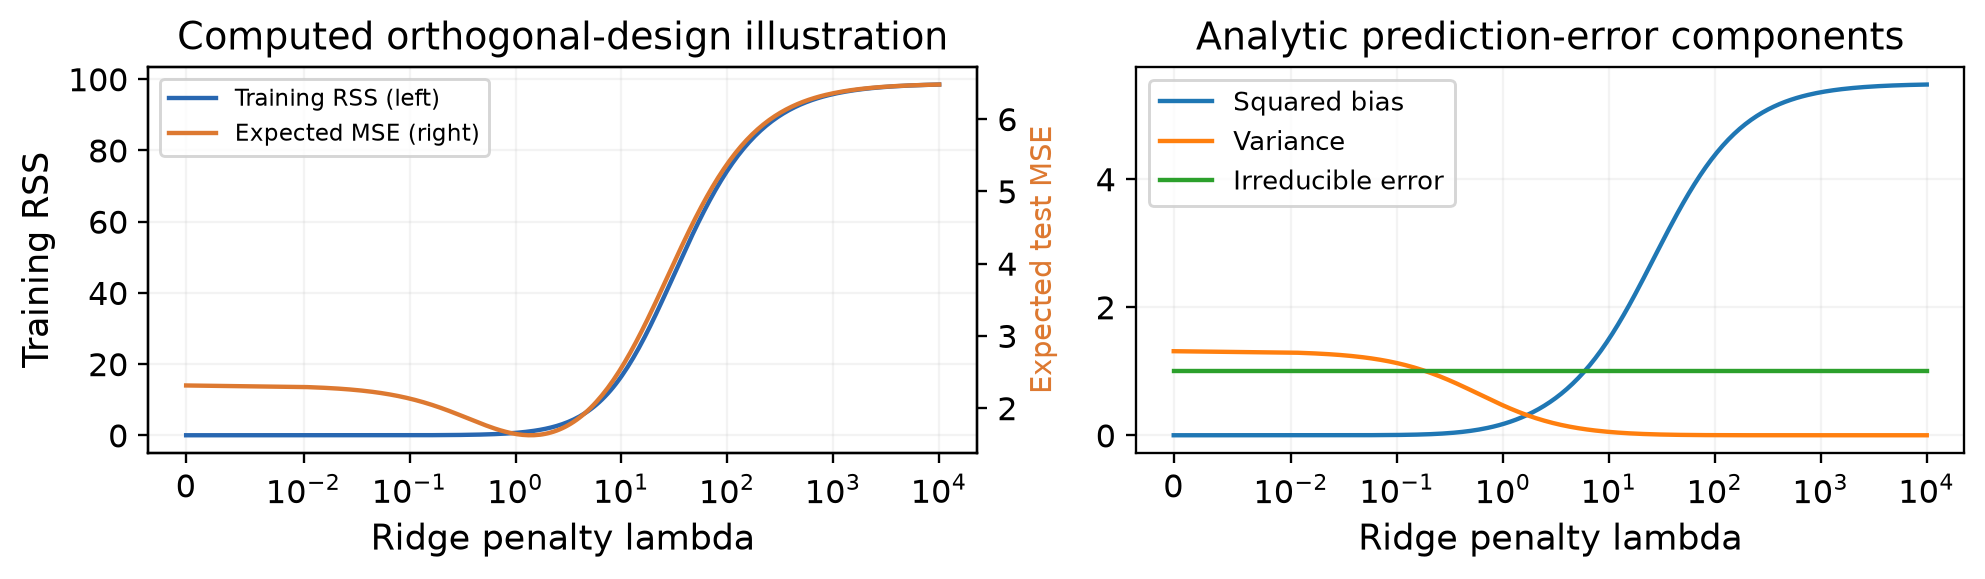

In [4]:
from IPython.display import display, Image
display(Image(filename=str(F / "extra_ridge.png"), width=1000))

Computed illustration: X = diag(4,2,1), true slopes (2,-1,0.7), known zero intercept, unit Gaussian noise, seed 552. Training RSS comes from the realized response; expected test MSE is the analytic sum of squared bias, variance and noise for isotropic test covariates. These are not APS results or held-out empirical estimates. Monotonicity checks passed.

### ISLR 8.4.4

Source: first edition, seventh printing, Section 8.4 Exercise 4, printed pp.332-333 (PDF pp.347-348), Figure 8.12. Checked independently against second-edition 8.4.4, pp.361-362, Figure 8.14: both partitions and all leaf values agree. The task asks (a) for a tree from the left partition and (b) for a partition from the right tree.

**(a)** A valid first split is X1 < 1 (false leaf: 5). On the true branch split X2 < 1 (false leaf: 15). In the lower-left part split X1 < 0 (true leaf: 3). On its false branch split X2 < 0, yielding 10 if true and 0 otherwise. The picture is a redrawing of the source regions and our corresponding tree; the finite plotting window does not bound the actual outer regions.

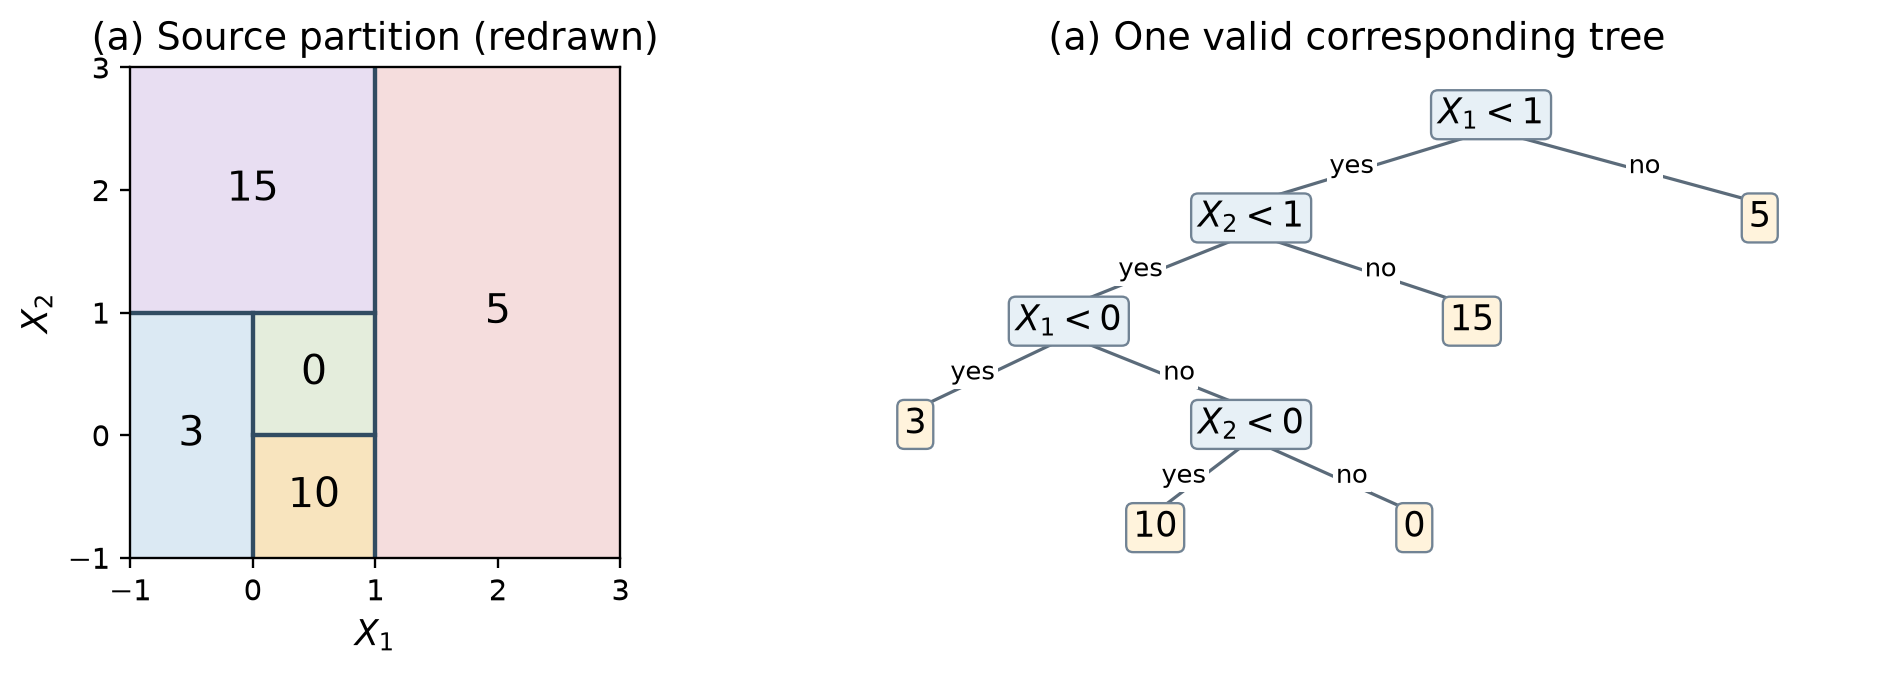

In [5]:
from IPython.display import display, Image
display(Image(filename=str(F / "extra_tree_a.png"), width=1000))

**(b)** The source tree first splits horizontally at X2 = 1, splits the lower half vertically at X1 = 1, then splits the upper half horizontally at X2 = 2 and the middle strip vertically at X1 = 0. The resulting five regions and their means are:

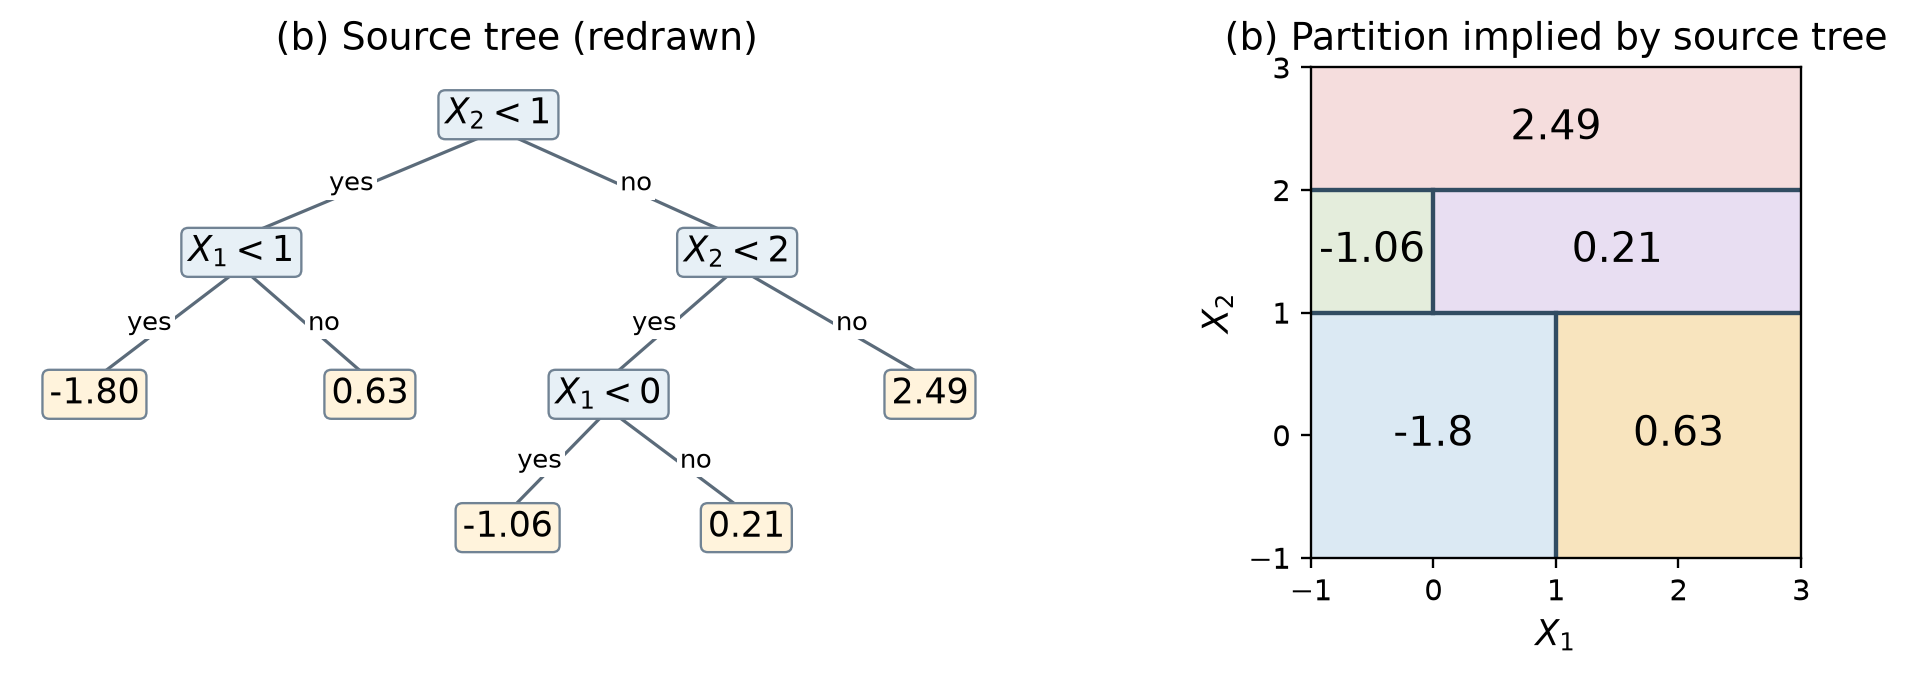

In [6]:
from IPython.display import display, Image
display(Image(filename=str(F / "extra_tree_b.png"), width=1000))

| Region conditions | Mean Y |
| --- | --- |
| X2 < 1 and X1 < 1 | -1.80 |
| X2 < 1 and X1 >= 1 | 0.63 |
| 1 <= X2 < 2 and X1 < 0 | -1.06 |
| 1 <= X2 < 2 and X1 >= 0 | 0.21 |
| X2 >= 2 | 2.49 |

Boundary convention: a less-than condition sends equality to the false branch. Independent tree traversal and piecewise region evaluation agree on 6,561 grid points, including the cut lines. Each diagram has five leaves/regions.

### ISLR 9.7.2

Source: first edition, seventh printing, Section 9.7 Exercise 2, printed p.368 (PDF p.383). The second-edition 9.7.2, p.398, has the same four subparts, curve, inequalities and query points.

**(a)** The curve (1 + X1) squared + (2 - X2) squared = 4 is a circle centered at (-1,2) with radius 2. Its horizontal extremes are (-3,2) and (1,2), and its vertical extremes are (-1,0) and (-1,4).

**(b)** The strict inequality > 4 denotes the exterior; <= 4 denotes the closed disk, including the boundary. The figure shades the exterior Blue and the closed disk Red, matching the rule in (c).

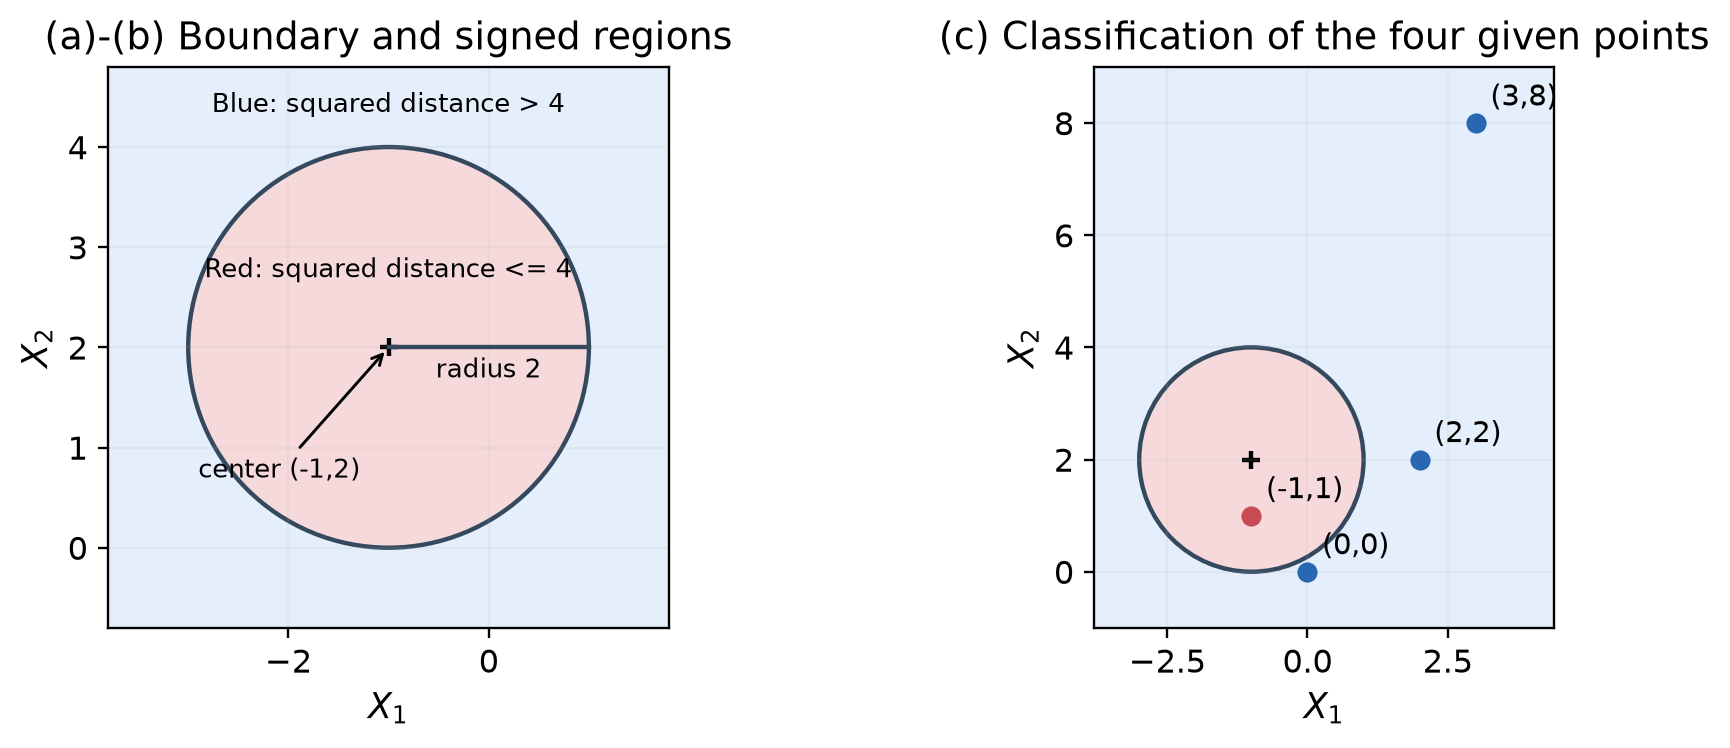

In [7]:
from IPython.display import display, Image
display(Image(filename=str(F / "extra_circle.png"), width=1000))

#### (c) Classify all four specified observations

| Point (X1,X2) | Squared distance from (-1,2) | Class |
| --- | --- | --- |
| (0,0) | 5 | Blue |
| (-1,1) | 1 | Red |
| (2,2) | 9 | Blue |
| (3,8) | 52 | Blue |

#### (d) A linear boundary in the expanded feature space

$$
(1+X_1)^2+(2-X_2)^2-4=X_1^2+X_2^2+2X_1-4X_2+1
$$

Let z = (X1, X1 squared, X2, X2 squared). The same boundary is 1 + 2 z1 + z2 - 4 z3 + z4 = 0, an affine hyperplane with intercept 1 and coefficients (2,1,-4,1). Predict Blue if this score is positive and Red otherwise. Thus the boundary is nonlinear in the original two inputs but linear in these four transformed coordinates. The computed expanded scores (1,-3,5,48) agree exactly with squared distance minus 4.

In [8]:
display(pd.read_csv(R / "extra_circle_points.csv"))
print("Bootstrap simulated inclusion count:", extra_results["bootstrap"]["inclusion_count"])
print("Tree/region grid points verified:", extra_results["tree"]["grid_points_checked"])
assert extra_results["all_passed"]

,X1,X2,squared_distance,expanded_score,class
0,0,0,5,1,Blue
1,-1,1,1,-3,Red
2,2,2,9,5,Blue
3,3,8,52,48,Blue


Bootstrap simulated inclusion count: 6238
Tree/region grid points verified: 6561


## Code-inclusive PDF: implementation and provenance

The current 20-page PDF includes the core Python implementation, all Q1–5 answers, four Q6 exercises, necessary figures and actual numeric outputs. Its body is 10.4 pt and monospaced code is 8.7 pt; no local course font/margin mandate was found. The following compact implementation is printed in the PDF and checked against the original full implementation above. Original APS models and search outputs are preserved. `RUN_TRAINING=False`: only preprocessing, plots and small theoretical examples execute in this section. APS fitting is additionally forbidden by the independent audit. The new cells were executed in a fresh kernel; previous executed cells and outputs remain intact.

In [1]:
import matplotlib
matplotlib.use("Agg")
"""Real, compact core implementation printed in the PDF.
RUN_TRAINING stays False during report revision. Existing APS fits are reused.
The training branches implement the original experiment, without cache/I/O code.
"""
# %% imports
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn import metrics as M
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
SEED = 552
RUN_TRAINING = False  # Original APS fits are not rerun in this revision.
# %% preparation
def read_aps(split):
    path = Path('Homework 6 Data') / f'aps_failure_{split}_set.csv'
    with path.open() as stream:
        h = next(i for i, s in enumerate(stream) if s.startswith('class,'))
    frame = pd.read_csv(path, skiprows=h, na_values=['na'])
    assert frame['class'].isin(['pos', 'neg']).all()
    return (frame.drop(columns='class').astype(float),
            frame['class'].map({'neg': 0, 'pos': 1}).to_numpy())
X, y = read_aps('training')
T, yt = read_aps('test')
assert X.shape == (60000, 170) and T.shape == (16000, 170)
assert X.columns.equals(T.columns)
imp = SimpleImputer(strategy='median', keep_empty_features=True)
A = imp.fit_transform(X)
B = SimpleImputer(strategy='median', keep_empty_features=True).fit_transform(T)
Bt = imp.transform(T)  # Sensitivity only: train-fitted imputation.
D = pd.DataFrame(A, columns=X.columns)
cv = D.std(ddof=1) / D.mean().replace(0, np.nan)
top = cv.nlargest(13).index.tolist()
# %% correlation
corr = D.corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set(xticks=np.arange(0, 170, 10), yticks=np.arange(0, 170, 10))
fig.colorbar(im, ax=ax, label='Pearson correlation')
# %% full_scatter
def full_scatter(Z, ys, columns, colors):
    fig, axes = plt.subplots(13, 13, figsize=(22, 22))
    for i, a in enumerate(columns):
        for j, b in enumerate(columns):
            ax = axes[i, j]
            if i == j:
                for c, color in [(0, '#3378a6'), (1, '#d34c49')]:
                    ax.hist(Z[a].to_numpy()[ys == c], bins=20,
                            histtype='step', density=True, color=color)
            else:
                ax.scatter(Z[b], Z[a], c=colors, s=1.5, alpha=.25)
            if j == 0: ax.set_ylabel(a, fontsize=8)
            if i == 12: ax.set_xlabel(b, fontsize=8)
    return fig
# %% scatter
rng = np.random.default_rng(SEED)
idx = np.r_[rng.choice(np.flatnonzero(y == 0), 2500, replace=False),
            np.flatnonzero(y == 1)]
Z = np.log1p(D.iloc[idx][top])
ys = y[idx]
colors = np.where(ys == 1, '#d34c49', '#3378a6')
# Full matrix: full_scatter(Z, ys, top, colors).
fig, axes = plt.subplots(4, 3, figsize=(9, 10))
for ax, col in zip(axes.flat, top[1:]):
    ax.scatter(Z[top[0]], Z[col], c=colors, s=3, alpha=.3)
    ax.set(xlabel=f'log(1+{top[0]})', ylabel=f'log(1+{col})')
fig.tight_layout()
# %% boxes
fig, axes = plt.subplots(5, 3, figsize=(10, 10))
for ax, col in zip(axes.flat, top):
    groups = [np.log1p(D.loc[y == c, col]) for c in [0, 1]]
    ax.boxplot(groups, tick_labels=['neg', 'pos'], showfliers=False)
    ax.set(title=col, ylabel='log(1+x)')
for ax in list(axes.flat)[13:]: ax.axis('off')
fig.tight_layout()
# %% evaluation
def evaluate(labels, probability):
    pred = (probability >= .5).astype(int)
    return dict(error=float(np.mean(pred != labels)),
        auc=M.roc_auc_score(labels, probability),
        average_precision=M.average_precision_score(labels, probability),
        precision=M.precision_score(labels, pred, zero_division=0),
        recall=M.recall_score(labels, pred), f1=M.f1_score(labels, pred),
        confusion_matrix=M.confusion_matrix(labels, pred, labels=[0, 1]))

def evaluate_splits(model, train, test, test_train_only):
    return {'train': evaluate(y, model.predict_proba(train)[:, 1]),
            'test': evaluate(yt, model.predict_proba(test)[:, 1]),
            'train_only_test': evaluate(yt,
                model.predict_proba(test_train_only)[:, 1])}
# %% forest
def train_forests():
    fitted, scores = {}, {}
    for name, weight in [('rf_plain', None), ('rf_balanced', 'balanced')]:
        model = RandomForestClassifier(n_estimators=500, criterion='gini',
            max_features='sqrt', max_depth=None, min_samples_leaf=1,
            bootstrap=True, oob_score=True, class_weight=weight,
            random_state=SEED, n_jobs=4)
        model.fit(A, y)
        scores[name] = evaluate_splits(model, A, B, Bt)
        oob = model.oob_decision_function_[:, 1]
        scores[name]['oob_error'] = float(np.mean((oob >= .5) != y))
        fitted[name] = model
    return fitted, scores
if RUN_TRAINING:
    forests, forest_scores = train_forests()
# %% roc_confusion
def draw_evaluation(labels, probability, cm_axis, roc_axis):
    cm = M.confusion_matrix(labels, probability >= .5, labels=[0, 1])
    M.ConfusionMatrixDisplay(cm, display_labels=['neg', 'pos']).plot(ax=cm_axis)
    fpr, tpr, _ = M.roc_curve(labels, probability)
    roc_axis.plot(fpr, tpr)
# %% xgb_pipeline
ALPHAS = [0., .001, .01, .1, 1., 10., 100.]
def make_xgb(alpha):
    return XGBClassifier(booster='gbtree', objective='binary:logistic',
        reg_alpha=alpha, reg_lambda=1, n_estimators=250, max_depth=4,
        learning_rate=.08, subsample=1, colsample_bytree=1, min_child_weight=1,
        tree_method='hist', max_bin=256, base_score=.5, eval_metric='logloss',
        random_state=SEED, n_jobs=4)
def fold_pipeline(alpha, use_smote):
    steps = [('imputer', SimpleImputer(strategy='median',
                                     keep_empty_features=True)),
             ('scaler', StandardScaler())]
    if use_smote:
        steps += [('smote', SMOTE(random_state=SEED, k_neighbors=5,
                                  sampling_strategy=1.0))]
    return Pipeline(steps + [('estimator', make_xgb(alpha))])
# %% search
def search_alpha(use_smote):
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    rows = []
    for alpha in ALPHAS:
        for fold, (tr, va) in enumerate(folds.split(X, y), 1):
            pipe = fold_pipeline(alpha, use_smote)
            pipe.fit(X.iloc[tr], y[tr])  # Only this training fold is fitted.
            p = pipe.predict_proba(X.iloc[va])[:, 1]  # Never resampled.
            rows.append(dict(alpha=alpha, fold=fold,
                ap=M.average_precision_score(y[va], p),
                error=float(np.mean((p >= .5) != y[va])),
                auc=M.roc_auc_score(y[va], p)))
    scores = pd.DataFrame(rows)
    summary = scores.groupby('alpha').agg(mean_ap=('ap', 'mean'),
        sd_ap=('ap', 'std'), mean_error=('error', 'mean'),
        sd_error=('error', 'std'), mean_auc=('auc', 'mean')).reset_index()
    best = summary.sort_values(['mean_ap', 'alpha'],
                               ascending=[False, True]).iloc[0]['alpha']
    return scores, summary, float(best)
if RUN_TRAINING:
    plain_folds, plain_summary, alpha0 = search_alpha(False)
    smote_folds, smote_summary, alpha1 = search_alpha(True)
# %% final_fit
def train_final(alpha, use_smote):
    import time
    scaler = StandardScaler()
    As = scaler.fit_transform(A)
    Bs, Bts = scaler.transform(B), scaler.transform(Bt)
    start = time.perf_counter()
    if use_smote:
        Ar, yr = SMOTE(random_state=SEED, k_neighbors=5,
                       sampling_strategy=1.0).fit_resample(As, y)
    else:
        Ar, yr = As, y
    sampling_seconds = time.perf_counter() - start
    model = make_xgb(alpha)
    model.fit(Ar, yr)
    # Evaluation always uses original rows, including for the training scores.
    scores = evaluate_splits(model, As, Bs, Bts)
    counts = np.bincount(yr, minlength=2)
    return model, scaler, scores, counts, sampling_seconds
if RUN_TRAINING:
    plain_final = train_final(alpha0, False)
# %% smote_call
if RUN_TRAINING:
    smote_final = train_final(alpha1, True)
    print(smote_final[3])  # Final class counts: [59000, 59000].
# %% comparison
def pr_curves(predictions):
    fig, ax = plt.subplots(figsize=(6, 4))
    for name, p in predictions.items():
        precision, recall, _ = M.precision_recall_curve(yt, p)
        ap = M.average_precision_score(yt, p)
        ax.plot(recall, precision, label=f'{name}: AP={ap:.3f}')
    ax.axhline(yt.mean(), ls='--', color='black')
    ax.set(xlabel='Recall', ylabel='Precision')
    ax.legend()
    return fig
# Bt (p.1) and evaluate_splits (p.5) produce the sensitivity evaluation.
# %% q3_check
x = np.array([1., -1.]); response = np.array([2., -2.]); penalty = 2.
a = x @ x; c = x @ response
ridge = c / (2*a + penalty)
tstar = np.sign(c) * max(abs(c) - penalty/2, 0) / a
objectives = [np.sum((response - x*tstar)**2) + penalty *
              (abs(w*tstar) + abs((1-w)*tstar)) for w in np.linspace(0, 1, 11)]
assert np.ptp(objectives) < 1e-12
# %% q4
prob = np.array([.1, .15, .2, .2, .55, .6, .6, .65, .7, .75])
red_votes = int((prob > .5).sum())
red_probability = float(prob.mean())
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(np.arange(1, 11), prob)
ax.axhline(.5, color='black', ls='--')
ax.axhline(red_probability, color='purple')
ax.set(xlabel='Bootstrap tree', ylabel='P(Red)', ylim=(0, 1))
# %% q5
from sklearn.svm import SVC
points = np.array([[3,4], [2,2], [4,4], [1,4], [2,1], [4,3], [4,1]])
labels = np.array([1, 1, 1, 1, -1, -1, -1])
svm = SVC(C=1e6, kernel='linear', tol=1e-10).fit(points, labels)
assert set(svm.support_ + 1) == {2, 3, 5, 6}
margin = 1 / np.linalg.norm(svm.coef_[0])
# %% q5_plot
def geometry_plot(points, labels):
    fig, ax = plt.subplots(figsize=(5, 5))
    for cls, color in [(1, '#d34c49'), (-1, '#3378a6')]:
        ax.scatter(*points[labels == cls].T, c=color)
    for i, point in enumerate(points, 1): ax.annotate(str(i), point)
    xx = np.linspace(.5, 4.8, 200)
    for offset, style in [(-.5, '-'), (0, '--'), (-1, '--')]:
        ax.plot(xx, xx + offset, color='black', ls=style)
    ax.plot(xx, xx-.2, ':', color='purple')
    ax.scatter([3], [3], c='#3378a6', marker='X')  # Added Blue point for (h).
    ax.set(xlim=(.5, 4.8), ylim=(.3, 4.8), xlabel='X1', ylabel='X2', aspect='equal')
    return fig
# %% q5_plot_call
geometry_plot(points, labels)
# %% bootstrap
n = np.arange(1, 100001)
included = np.ones(len(n))
included[1:] = -np.expm1(n[1:] * np.log1p(-1/n[1:]))
rng = np.random.default_rng(SEED)
samples = rng.integers(1, 101, size=(10000, 100))
hits = np.any(samples == 4, axis=1)
empirical = float(hits.mean())
exact = float(included[99])
mcse = np.sqrt(exact * (1-exact) / 10000)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(n, included); ax.set_xscale('log')
ax.axhline(1-np.exp(-1), color='red', ls='--')
ax.set(xlabel='n (all integers 1 through 100000)', ylabel='Inclusion probability')
# %% trees
TA = (0, 1, (1, 1, (0, 0, 3, (1, 0, 10, 0)), 15), 5)
TB = (1, 1, (0, 1, -1.80, .63), (1, 2, (0, 0, -1.06, .21), 2.49))
def leaf(t): return not isinstance(t, tuple)
def leaves(t): return 1 if leaf(t) else leaves(t[2]) + leaves(t[3])
def tree_value(t, x):
    if leaf(t): return t
    j, cut, yes, no = t
    return tree_value(yes if x[j] < cut else no, x)
def draw_tree(ax, t, lo=0, hi=1, depth=0):
    x, y0 = (lo+hi)/2, -depth
    if leaf(t):
        text = f'{t:g}'
    else:
        j, cut, yes, no = t
        text = f'X{j+1} < {cut:g}'
        mid = lo + (hi-lo)*leaves(yes)/leaves(t)
        for branch, a, b, label in [(yes,lo,mid,'yes'), (no,mid,hi,'no')]:
            cx, cy = draw_tree(ax, branch, a, b, depth+1)
            ax.plot([x,cx], [y0,cy], color='#536879', zorder=0)
            ax.text((x+cx)/2, (y0+cy)/2, label, fontsize=9,
                    bbox=dict(facecolor='white', edgecolor='none', pad=1))
    ax.text(x, y0, text, ha='center', va='center', fontsize=12,
            bbox=dict(boxstyle='round,pad=.2', facecolor='#e5edf5'))
    return x, y0
RA = [(-1,-1,1,2,3), (0,-1,1,1,10), (0,0,1,1,0),
      (-1,1,2,2,15), (1,-1,2,4,5)]
RB = [(-1,-1,2,2,-1.80), (1,-1,2,2,.63), (-1,1,1,1,-1.06),
      (0,1,3,1,.21), (-1,2,4,1,2.49)]
def tree_partition(t, regions):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    draw_tree(axes[0], t); axes[0].axis('off')
    for x, y0, w, h, mean in regions:
        axes[1].add_patch(plt.Rectangle((x,y0), w, h, facecolor='#e5edf5',
                                       edgecolor='#536879'))
        axes[1].text(x+w/2, y0+h/2, f'{mean:g}', ha='center', va='center')
    axes[1].set(xlim=(-1,3), ylim=(-1,3), xlabel='X1', ylabel='X2', aspect='equal')
    fig.tight_layout()
    return fig
fig_a = tree_partition(TA, RA)
fig_b = tree_partition(TB, RB)
# %% circle
query = np.array([[0,0], [-1,1], [2,2], [3,8]])
distance2 = ((query - [-1,2])**2).sum(axis=1)
score = query[:,0]**2 + query[:,1]**2 + 2*query[:,0] - 4*query[:,1] + 1
classes = np.where(score > 0, 'Blue', 'Red')
assert np.array_equal(score, distance2 - 4)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.7))
for ax in axes:
    ax.set_facecolor('#e5eefb')
    ax.add_patch(plt.Circle((-1,2), 2, facecolor='#f6d9db', edgecolor='black'))
    ax.set(xlabel='X1', ylabel='X2', aspect='equal')
axes[0].set(xlim=(-3.8,1.8), ylim=(-.8,4.8))
axes[0].text(-1, 2.7, 'Red: distance squared <= 4', ha='center', fontsize=9)
axes[1].set(xlim=(-3.8,4.4), ylim=(-1,9))
for point, cls in zip(query, classes):
    axes[1].scatter(*point, c='red' if cls == 'Red' else 'blue')
    axes[1].annotate(f'({point[0]},{point[1]})', point, xytext=(4,5),
                     textcoords='offset points', fontsize=10)
fig.tight_layout()
# %% end

plt.close("all")
print("Core preprocessing, figures and theoretical computations executed; APS fitting disabled.")
print("Bootstrap:", empirical, "Q3 objective:", objectives[0], "Circle:", classes.tolist())

Core preprocessing, figures and theoretical computations executed; APS fitting disabled.
Bootstrap: 0.6238 Q3 objective: 3.5 Circle: ['Blue', 'Red', 'Blue', 'Blue']


In [2]:
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd() / "scripts"))
from audit_submission_core import audit
core_audit = audit()
assert core_audit["all_passed"]

{
  "all_passed": true,
  "aps_fit_calls_forbidden_during_audit": true,
  "original_parameter_dictionaries_equal": {
    "rf_plain": true,
    "rf_balanced": true,
    "xgb_plain": true,
    "xgb_smote": true
  },
  "cv_fold_indices_equal": true,
  "imputation_and_scaling_logic_equal": true,
  "170_feature_cvs_and_top13_equal": true,
  "all_saved_metrics_recomputed": true,
  "extra_bootstrap_circle_and_tree_outputs_equal": true,
  "preserved_experiment_files": 25,
  "core_source_sha256": "d1e5a27eccb7d0fb60de5d0cb3cb455eb2686b349e28429f96ad5582929a7549",
  "q3_check": {
    "ridge": 0.6666666666666666,
    "lasso_sum": 1.5,
    "objective": 3.5
  }
}
